# LA County · corrected quantum spread and three dynamic simulations

**The figures below are included in this file.** They show the verified default
48-hour run; you do not need to execute code just to view them.

To recompute the results, open this notebook in **Colab → Runtime → Run all**,
or use **Run All** in Jupyter / VS Code with Python 3.12 or 3.13. First setup
needs internet; restart the kernel once if the installer requests it.

On GitHub, choose the notebook's **Preview** view rather than **Code / Raw**.
The interactive slider needs a running Python kernel. Saved maps, charts,
and compact GIF previews are included; Run All regenerates full-size GIFs.

### Saved 48-hour comparison

These overview maps are snapshots of the bundled default scenario. Run All
refreshes them after the new simulation finishes. Gray is each model's own
reached area; colors show anticipated spread over the next 24 hours.


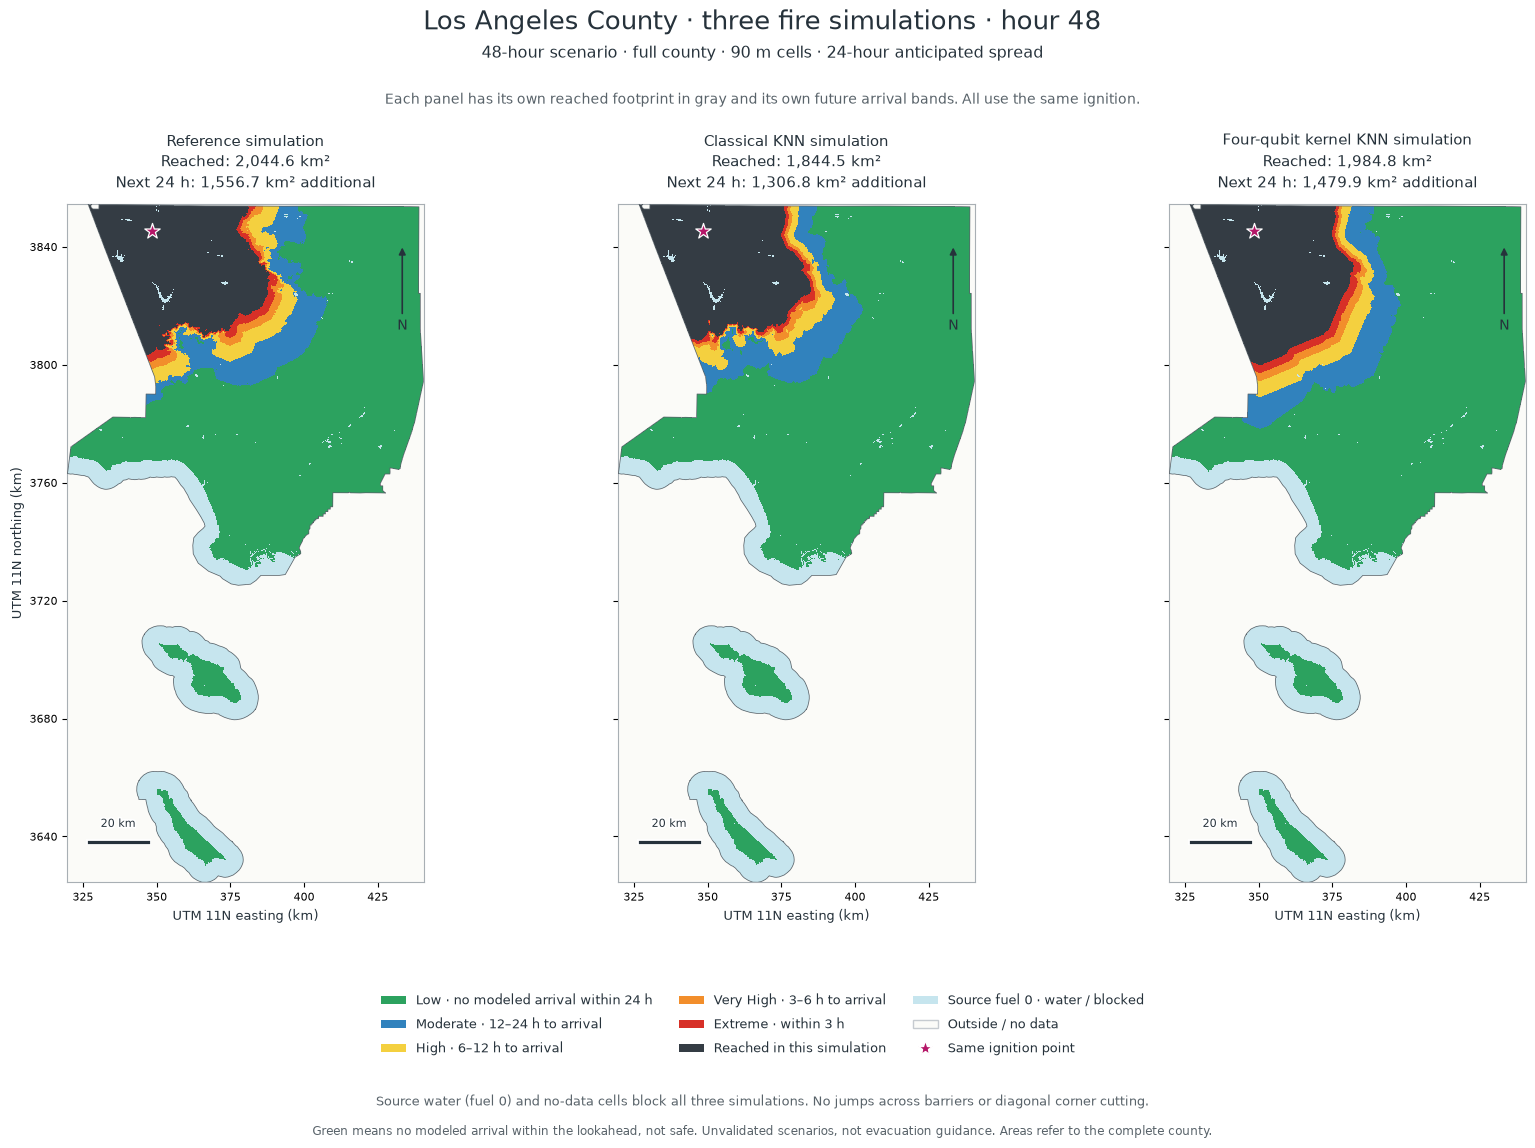

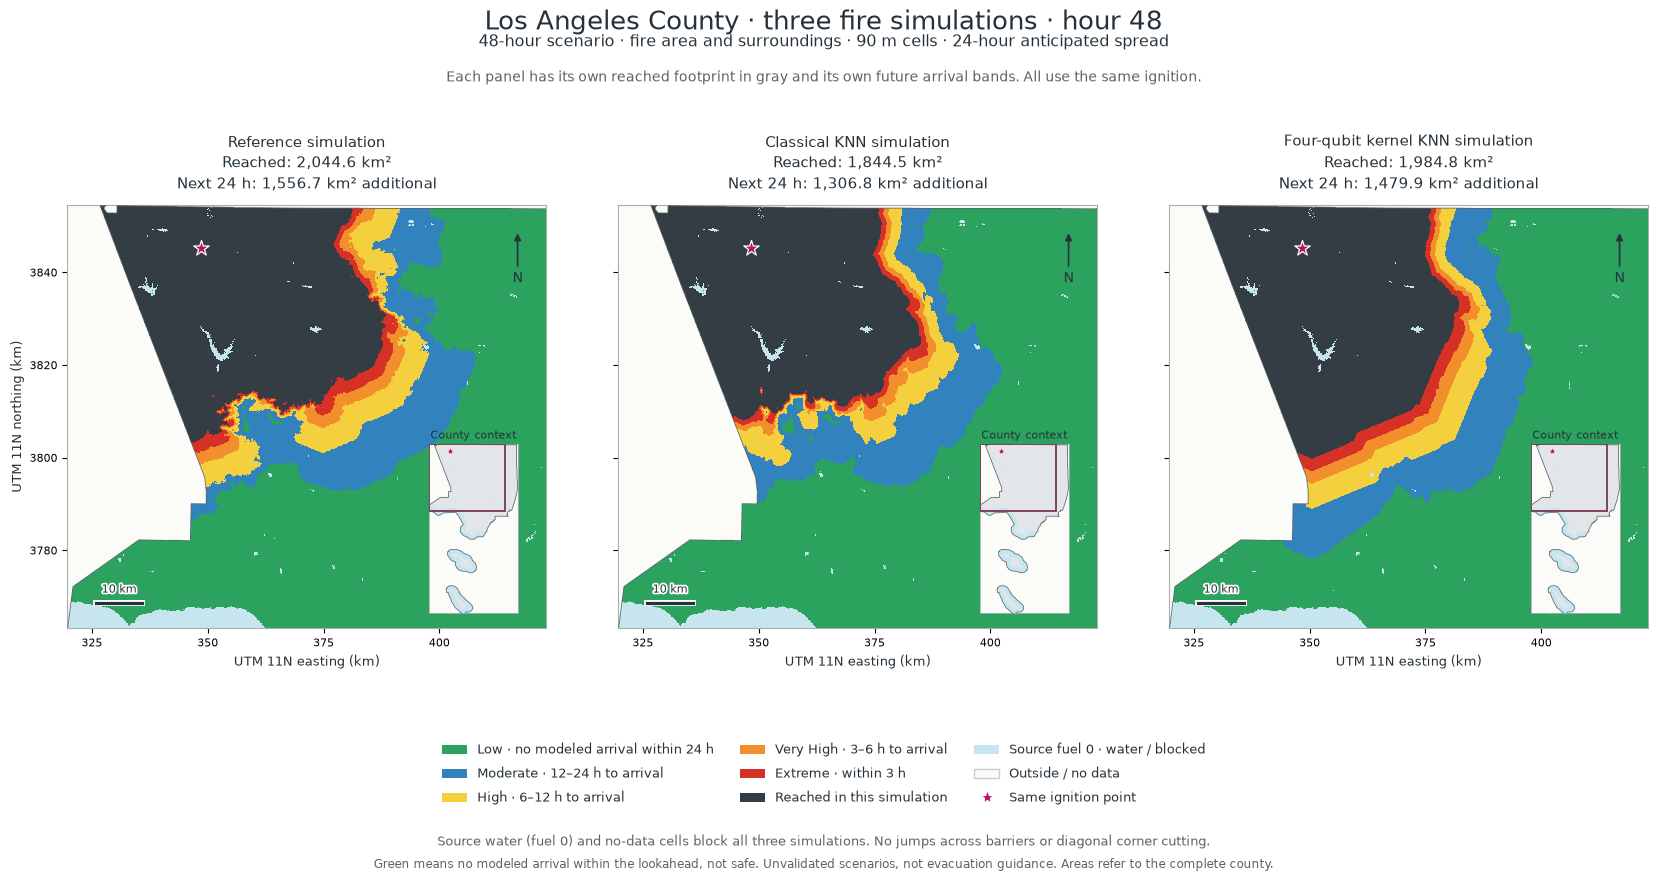

In [ ]:
# Saved overview figures are included below. Run All refreshes these displays.
from pathlib import Path
from IPython.display import display, Image, Markdown, update_display
_overview_dir = Path.cwd() / 'quantum_geo_run' / 'fire_outputs' / '48h_three_simulations'
for _overview_mode in ('county', 'detail'):
    _overview_path = _overview_dir / f'three_simulations_hour_48_{_overview_mode}.png'
    _overview_content = (Image(filename=str(_overview_path)) if _overview_path.is_file()
                         else Markdown('The updated overview will appear here after '
                                       'the three simulations finish in section 5.'))
    display(_overview_content, display_id=f'quantum_geo_overview_{_overview_mode}')

## Run this notebook

1. Open this `.ipynb` in **Google Colab** using **File → Open notebook → GitHub**
   and paste its GitHub URL, or upload this one file. Use a **CPU** runtime.
2. Choose **Runtime → Run all**. The first cell installs the tested packages
   into the running Python environment. Internet access is needed for setup.
3. If setup reports that an already-loaded package changed, **restart the
   session/kernel once, then Run all again**. This avoids mixing old and new
   compiled packages. It is not necessary when the environment already matches.
4. Wait for **Completed** at the bottom. Both GIFs, Excel data, CSVs, kernels,
   rasters, and a ZIP of all results are saved under `quantum_geo_run/`.
   In Colab, use the download controls at the end or the Files panel. Download
   results before the temporary Colab session ends.

Locally, use **64-bit Python 3.12 or 3.13** with JupyterLab or VS Code's Python
and Jupyter extensions, select that Python kernel, and click **Run All**.
An isolated virtual environment is recommended. A notebook cannot install
Python or its notebook host before it starts; Colab supplies both.

Allow several minutes for installation and simulation; slower CPUs take longer.
8 GB RAM and 3 GB free disk are recommended. No GPU is used. GitHub displays
a static preview; it does not execute the code or run the interactive player.
[Colab documentation](https://research.google.com/colaboratory/faq.html)
· [GitHub notebook previews](https://docs.github.com/en/repositories/working-with-files/using-files/working-with-non-code-files#working-with-jupyter-notebook-files)

The default remains the same **48-hour, 90 m** scenario and original seeded
ignition. The notebook calculates through hour 72 for its 24-hour forecasts.


**48-hour animation · reference / classical KNN / quantum KNN · water blocks all three**

The corrected physical simulation is in **sections 5–6**. It uses a separate
four-qubit **fuel-score** regression head and the original connected-cell
travel-time solver. It produces a real third arrival-time field, with water
and unknown cells blocked, no diagonal corner cutting, and the same speed
table. The slider and GIFs show each simulation's own fire footprint and
24-hour look-ahead. Calculations extend to hour 72.

The original hourly **danger-label** experiment and data sheets remain in
sections 2–4. Those independent category predictions are not physical fire
propagation; the corrected animation never uses them as arrival times or fuel.

This notebook rebuilds the classical KNN forecasts, then samples 40 random
90 m cell centers from each **Low, Moderate, High, Very High, Extreme** zone
at hours 1–48: **9,600 rows**. At every hour, each zone contributes 32 training
points and 8 test points from the existing disjoint spatial blocks. Locations
can recur at different hours, but never switch between training and testing.
Only land not yet reached by the reference scenario at that hour is eligible.

The supplied **EIDF_QUANTUM_GEO.pdf**, pages 2–5, describes an RX/RZ → cyclic CZ
→ nonlinear RY → interaction RZ feature map and a squared-overlap kernel for
SVM. Here that gate pattern is extended to **four qubits and four inputs**, and
the kernel feeds a distance-weighted **KNN regressor**, as requested. The
presentation's four illustrative class names and synthetic hinge-loss results
are not transferred to this five-category simulation.

The user-selected supervised target is **reference-simulation future danger**.
The reference's future arrival and label are never inputs to the circuit.
The four inputs are X, Y, baseline KNN continuous susceptibility, and baseline
remaining arrival time. The model learns from the original forecast and is
evaluated against held-out reference labels. This is retrospective synthetic
supervision, not an observed-fire or live evacuation validation.

Outputs include an Excel workbook, 48 point CSVs, a quantum feature table,
16 complex state amplitudes per point, 48 **200 × 200 fidelity kernels**,
their distance matrices, train/test blocks, and new predictions for all 9,600
sample records (1,920 held out). Corrected physical outputs and the full-county
and detail GIFs are saved in **quantum_geo_run/fire_outputs/48h_three_simulations**.

**Standalone GitHub edition.** All code and the supplied scored KML map are
embedded. No other project files, previously computed outputs, PDF, satellite
image, cloud drive mount, API keys, or quantum service account are required.
The source presentation is a method reference, not a runtime input.

**Interpretation:** These are custom future-danger categories, not official
NFDRS ratings, calibrated probabilities, or validated evacuation guidance.
Green does not mean safe. [LA County emergency information](https://lacounty.gov/emergency/)

## 1. Install dependencies, extract data, and rebuild the baseline

In [ ]:
"""Install the tested scientific environment into this notebook's Python."""
import importlib
from importlib.metadata import PackageNotFoundError, version
import platform
import subprocess
import sys

if globals().get('_QUANTUM_GEO_RESTART_REQUIRED'):
    raise RuntimeError(
        'A package update is still waiting for a real kernel/session restart. '
        'Click Restart (not just Run All), then Run All again. Updated packages: '
        + ', '.join(_QUANTUM_GEO_RESTART_REQUIRED))

if sys.version_info[:2] not in ((3, 12), (3, 13)):
    raise RuntimeError(
        'Use a Python 3.12 or 3.13 kernel (64-bit). In Colab choose a compatible '
        'Python runtime; locally select that interpreter, then Run All again.')
if sys.maxsize <= 2**32:
    raise RuntimeError('This county-scale simulation needs 64-bit Python.')

# packaging is normally supplied by the notebook host, but bootstrap it if absent.
try:
    from packaging.requirements import Requirement
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'packaging>=24,<27'])
    importlib.invalidate_caches()
    from packaging.requirements import Requirement

# These are the direct scientific dependencies tested together. Their transitive
# dependencies are resolved by pip. IPython belongs to the running notebook host;
# retain a compatible installed version instead of forcing an unnecessary restart.
PORTABLE_REQUIREMENTS = {
    'numpy': 'numpy==2.5.4',
    'pandas': 'pandas==3.1.0',
    'scipy': 'scipy==1.18.1',
    'sklearn': 'scikit-learn==1.9.1',
    'pennylane': 'pennylane==0.45.1',
    'rasterio': 'rasterio==1.5.2',
    'shapely': 'shapely==2.2.0',
    'pyproj': 'pyproj==3.8.0',
    'matplotlib': 'matplotlib==3.11.2',
    'openpyxl': 'openpyxl==3.1.5',
    'ipywidgets': 'ipywidgets==8.1.9',
    'PIL': 'pillow==13.0.0',
    'affine': 'affine==3.0.1',
    'threadpoolctl': 'threadpoolctl==3.7.0',
    'IPython': 'ipython>=8.12,<10',
}

def installed_version(name):
    try:
        return version(name)
    except PackageNotFoundError:
        return None

requirements = [Requirement(value) for value in PORTABLE_REQUIREMENTS.values()]
before_versions = {req.name: installed_version(req.name) for req in requirements}
loaded_before_install = set(sys.modules)
needs_install = [str(req) for req in requirements
                 if before_versions[req.name] is None
                 or before_versions[req.name] not in req.specifier]
if needs_install:
    print('Installing the tested package set into:', sys.executable, flush=True)
    print('First-run setup needs internet access and may take several minutes.', flush=True)
    subprocess.check_call([
        sys.executable, '-m', 'pip', 'install', '--disable-pip-version-check',
        '--prefer-binary', *PORTABLE_REQUIREMENTS.values()])
    importlib.invalidate_caches()
    changed_loaded = [root for root, text in PORTABLE_REQUIREMENTS.items()
                      if root in loaded_before_install
                      and before_versions[Requirement(text).name]
                      != installed_version(Requirement(text).name)]
    if changed_loaded:
        _QUANTUM_GEO_RESTART_REQUIRED = tuple(changed_loaded)
        raise RuntimeError(
            'Installation finished. Restart the kernel/session, then Run All again '
            'to load the updated packages safely: ' + ', '.join(changed_loaded)
            + '. Colab: Runtime > Restart session. Jupyter/VS Code: Restart kernel.')
for requirement in requirements:
    actual = installed_version(requirement.name)
    if actual is None or actual not in requirement.specifier:
        raise RuntimeError(f'Package setup did not satisfy {requirement}; found {actual}.')

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import output as colab_output
    colab_output.enable_custom_widget_manager()

print('Environment ready:', platform.python_version(), platform.system())
print('CPU execution; no GPU, API key, quantum account, or separate GIS install is needed.')

In [ ]:
from pathlib import Path
import json, hashlib, time, io
from datetime import datetime, timezone
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
import pennylane as qml
from affine import Affine
from threadpoolctl import threadpool_limits
from IPython.display import display, Markdown, FileLink, Image, HTML
from PIL import Image as PILImage
import ipywidgets as widgets

# A writable, relative folder. Existing project outputs are not inputs.
PROJECT_DIR = Path.cwd() / 'quantum_geo_run'
BASELINE_DIR = PROJECT_DIR / 'baseline'
SIM_OUTPUT = PROJECT_DIR / 'fire_outputs' / '48h_three_simulations'
OUTPUT = SIM_OUTPUT / 'quantum_data'
OUTPUT.mkdir(parents=True, exist_ok=True)
HOURS = tuple(range(1, 49))
DISPLAY_HOURS = 48
CELL_M = 90.0
FORECAST_BANDS = (3.0, 6.0, 12.0, 24.0)
CALCULATION_HOURS = DISPLAY_HOURS + FORECAST_BANDS[-1]
BASELINE_SEED = 42
IGNITION_SEED = 42
POINTS_PER_ZONE = 40
TEST_POINTS_PER_ZONE = 8
SNAPSHOT_SEED = 2026
KNN_K = 5
ETA_FEATURE_CAP_HOURS = 48.0
NUM_THREADS = 4
QUERY_BATCH_SIZE = 8192
PHYSICAL_KERNEL_HOUR = 1
GIF_FRAME_MS = 450
GIF_DPI = 90
SPEED_MPS = np.array([0.0, 0.02, 0.10, 0.25, 0.50])
assert PHYSICAL_KERNEL_HOUR == 1 and POINTS_PER_ZONE == 40 and TEST_POINTS_PER_ZONE == 8
assert ETA_FEATURE_CAP_HOURS > FORECAST_BANDS[-1]
print('Snapshots:', len(HOURS), 'hours;', 5*POINTS_PER_ZONE, 'points/hour')
print('Three simulations:', DISPLAY_HOURS, 'display hours;', CALCULATION_HOURS, 'calculation hours')
print('Outputs:', SIM_OUTPUT)

In [ ]:
# @title Load bundled map data { display-mode: "form" }
# The long literal is compressed geographic input, not an error or figure.
import base64, gzip
SOURCE_KML_SHA256 = 'c833f3b621cc073af20f1d688fb7329ccd7b923ef5ccf9a35d32e443bec0aed8'
PRESENTATION_SHA256 = '5a04ab94c7bbfe7c5a379770e9e3a4ac5a473470eb61216257f7694eb58e248b'  # Source reference at packaging time.
KML_GZIP_BASE64 = '...'
embedded_kml = gzip.decompress(base64.b64decode(KML_GZIP_BASE64, validate=True))
assert hashlib.sha256(embedded_kml).hexdigest() == SOURCE_KML_SHA256
input_dir = PROJECT_DIR / 'data'
input_dir.mkdir(parents=True, exist_ok=True)
KML_PATH = input_dir / f'LA_County_Fire_Susceptibility_{SOURCE_KML_SHA256[:12]}.kml'
if KML_PATH.exists():
    if hashlib.sha256(KML_PATH.read_bytes()).hexdigest() != SOURCE_KML_SHA256:
        raise RuntimeError(f'Generated input was modified: {KML_PATH}. '
                           'Move it aside or choose another PROJECT_DIR, then Run All.')
else:
    KML_PATH.write_bytes(embedded_kml)
del embedded_kml, KML_GZIP_BASE64
print('Embedded map restored and SHA-256 verified:', KML_PATH)

In [ ]:
"""Read the supplied KML and solve bounded, barrier-aware fire travel times.

This cell defines reusable functions; it does not download data or start a
county-scale simulation. Distances and speeds use metres and seconds, while
arrival times and the search limit use hours.
"""

from collections import defaultdict
from collections.abc import Mapping
from pathlib import Path
import math
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
from pyproj import Transformer
from rasterio.crs import CRS
from rasterio.features import rasterize
from rasterio.transform import from_origin
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra
from shapely import make_valid
from shapely.geometry import Polygon, MultiPolygon, GeometryCollection, mapping
from shapely.ops import transform as transform_geometry, unary_union


def _polygon_parts(geometry):
    """Keep polygonal parts, including their interior rings, after repair."""
    if geometry.is_empty:
        return []
    if isinstance(geometry, Polygon):
        return [geometry]
    if isinstance(geometry, (MultiPolygon, GeometryCollection)):
        return [part for item in geometry.geoms for part in _polygon_parts(item)]
    return []


def _repair_polygonal(geometry):
    repaired = not geometry.is_valid
    if repaired:
        geometry = make_valid(geometry)
    parts = _polygon_parts(geometry)
    if not parts:
        raise ValueError("A KML polygon has no polygonal area after validation.")
    return (parts[0] if len(parts) == 1 else unary_union(parts)), repaired


def _read_ring(element):
    if element is None or not element.text:
        raise ValueError("A polygon ring is missing its KML coordinates.")
    coordinates = []
    for token in element.text.split():
        pieces = token.split(",")
        if len(pieces) < 2:
            raise ValueError(f"Invalid KML coordinate: {token!r}")
        lon, lat = float(pieces[0]), float(pieces[1])
        if not (np.isfinite(lon) and np.isfinite(lat)
                and -180 <= lon <= 180 and -90 <= lat <= 90):
            raise ValueError(f"Invalid longitude/latitude: {(lon, lat)}")
        coordinates.append((lon, lat))
    if len(set(coordinates)) < 3:
        raise ValueError("A polygon ring needs at least three distinct vertices.")
    if coordinates[0] != coordinates[-1]:
        coordinates.append(coordinates[0])
    return coordinates


def _placemark_polygons(placemark, namespace):
    for element in placemark.findall(".//k:Polygon", namespace):
        exterior = _read_ring(element.find(
            "k:outerBoundaryIs/k:LinearRing/k:coordinates", namespace))
        interiors = [_read_ring(ring) for ring in element.findall(
            "k:innerBoundaryIs/k:LinearRing/k:coordinates", namespace)]
        yield Polygon(exterior, interiors)


def load_susceptibility(kml_path, cell_m=90.0, crs="EPSG:32611"):
    """Rasterize the supplied scored KML polygons on a metric working grid.

    Scores are 0..4; -1 means outside the county or unclassified coverage.
    Interior holes are retained, invalid polygonal geometry is repaired, and
    all scored geometry is clipped to the county boundary. Pixel centres
    determine coverage (all_touched=False). The working grid is resampled in
    the requested projection; its alignment is not the original NLCD grid.
    """
    cell_m = float(cell_m)
    if not np.isfinite(cell_m) or cell_m <= 0:
        raise ValueError("cell_m must be a positive finite distance in metres.")
    target_crs = CRS.from_user_input(crs)
    if not target_crs.is_projected or target_crs.linear_units != "metre":
        raise ValueError("Choose a projected CRS whose linear units are metres.")

    root = ET.parse(Path(kml_path)).getroot()
    namespace_uri = root.tag.partition("}")[0].lstrip("{")
    namespace = {"k": namespace_uri}
    county_parts = []
    scored_parts = []
    source_rows = []
    repair_count = 0

    for placemark in root.findall(".//k:Placemark", namespace):
        attributes = {item.attrib["name"]: item.text
                      for item in placemark.findall(".//k:SimpleData", namespace)}
        # Also accept KML Data/value encoding without relying on display styles.
        attributes.update({item.attrib["name"]: item.findtext("k:value", namespaces=namespace)
                           for item in placemark.findall(".//k:Data", namespace)})
        name = placemark.findtext("k:name", default="", namespaces=namespace)
        style = placemark.findtext("k:styleUrl", default="", namespaces=namespace)
        polygons = list(_placemark_polygons(placemark, namespace))
        if not polygons:
            continue
        if "score" not in attributes:
            if style == "#boundary" or "county" in name.lower():
                for polygon in polygons:
                    valid, repaired = _repair_polygonal(polygon)
                    county_parts.extend(_polygon_parts(valid))
                    repair_count += int(repaired)
            continue

        numeric_score = float(attributes["score"])
        if not numeric_score.is_integer() or not 0 <= numeric_score <= 4:
            raise ValueError(f"Unsupported susceptibility score in {name!r}.")
        score_value = int(numeric_score)
        source_rows.append({
            "score": score_value,
            "land_cover": attributes.get("land_cover", ""),
            "source_year": int(attributes["source_year"]) if attributes.get("source_year") else np.nan,
            "grid_m": float(attributes["grid_m"]) if attributes.get("grid_m") else np.nan,
            "area_km2": float(attributes["area_km2"]) if attributes.get("area_km2") else np.nan,
            "polygon_count": len(polygons),
        })
        for polygon in polygons:
            valid, repaired = _repair_polygonal(polygon)
            scored_parts.append((valid, score_value))
            repair_count += int(repaired)

    if not county_parts or not scored_parts:
        raise ValueError("The KML must contain a county boundary and scored polygons.")

    transformer = Transformer.from_crs("EPSG:4326", target_crs, always_xy=True)
    county_geometry, repaired = _repair_polygonal(transform_geometry(
        transformer.transform, unary_union(county_parts)))
    repair_count += int(repaired)
    projected_parts = []
    projected_areas = defaultdict(float)
    for geometry, score_value in scored_parts:
        projected, repaired = _repair_polygonal(transform_geometry(
            transformer.transform, geometry))
        repair_count += int(repaired)
        clipped = projected.intersection(county_geometry)
        if clipped.is_empty:
            continue
        if not clipped.is_valid:
            clipped = make_valid(clipped)
            repair_count += 1
        for part in _polygon_parts(clipped):
            projected_parts.append((part, score_value))
            projected_areas[score_value] += part.area / 1_000_000.0

    min_x, min_y, max_x, max_y = county_geometry.bounds
    left = math.floor(min_x / cell_m) * cell_m
    bottom = math.floor(min_y / cell_m) * cell_m
    right = math.ceil(max_x / cell_m) * cell_m
    top = math.ceil(max_y / cell_m) * cell_m
    width = int(round((right - left) / cell_m))
    height = int(round((top - bottom) / cell_m))
    affine = from_origin(left, top, cell_m, cell_m)

    # Higher scores win only if supplied polygons overlap at a pixel centre.
    # Rasterizing the full polygons preserves interior holes instead of filling
    # their exterior rings. -1 is deliberately distinct from water (score 0).
    projected_parts.sort(key=lambda item: item[1])
    score = rasterize(
        ((mapping(geometry), value) for geometry, value in projected_parts),
        out_shape=(height, width), transform=affine, fill=-1,
        all_touched=False, dtype="int16").astype(np.int8)
    county_mask = rasterize(
        [(mapping(county_geometry), 1)], out_shape=score.shape,
        transform=affine, fill=0, all_touched=False, dtype="uint8").astype(bool)
    score[~county_mask] = -1

    source_frame = pd.DataFrame(source_rows)
    summary_rows = []
    for score_value, frame in source_frame.groupby("score", sort=True):
        source_years = frame["source_year"].dropna().unique()
        grid_sizes = frame["grid_m"].dropna().unique()
        cell_count = int(np.count_nonzero(score == score_value))
        summary_rows.append({
            "score": int(score_value),
            "land_cover": "; ".join(sorted(set(frame["land_cover"]))),
            "source_year": int(source_years[0]) if len(source_years) == 1 else "; ".join(map(str, source_years)),
            "grid_m": float(grid_sizes[0]) if len(grid_sizes) == 1 else "; ".join(map(str, grid_sizes)),
            "area_km2": frame["area_km2"].sum(min_count=1),
            "projected_area_km2": projected_areas[int(score_value)],
            "raster_cells": cell_count,
            "raster_area_km2": cell_count * cell_m ** 2 / 1_000_000.0,
            "placemarks": len(frame),
            "polygons": int(frame["polygon_count"].sum()),
        })

    return {
        "score": score,
        "transform": affine,
        "crs": target_crs,
        "bounds": (left, bottom, right, top),
        "source_summary": pd.DataFrame(summary_rows),
        "county_geometry": county_geometry,
        "cell_m": cell_m,
        "diagnostics": {
            "geometry_repairs": repair_count,
            "county_cells": int(county_mask.sum()),
            "unclassified_county_cells": int(np.count_nonzero(county_mask & (score == -1))),
            "classified_cells": int(np.count_nonzero(score >= 0)),
        },
    }


def xy_for_cells(grid, flat_indices):
    """Return projected x/y pixel centres for flattened raster indices."""
    indices = np.asarray(flat_indices)
    if indices.dtype.kind not in "iu":
        raise ValueError("flat_indices must contain integer raster indices.")
    indices = indices.reshape(-1).astype(np.int64, copy=False)
    height, width = grid["score"].shape
    if np.any(indices < 0) or np.any(indices >= height * width):
        raise IndexError("A cell index lies outside the raster.")
    rows, columns = np.divmod(indices, width)
    affine = grid["transform"]
    x = affine.a * (columns + 0.5) + affine.b * (rows + 0.5) + affine.c
    y = affine.d * (columns + 0.5) + affine.e * (rows + 0.5) + affine.f
    return np.column_stack((x, y))


def _neighbor_pairs(node_grid, connectivity):
    """Each undirected adjacent pair once; diagonal sides must both be land."""
    directions = [
        ((slice(None), slice(None, -1)), (slice(None), slice(1, None)), 1.0, None),
        ((slice(None, -1), slice(None)), (slice(1, None), slice(None)), 1.0, None),
    ]
    if connectivity == 8:
        directions += [
            ((slice(None, -1), slice(None, -1)), (slice(1, None), slice(1, None)),
             math.sqrt(2.0), ((slice(None, -1), slice(1, None)), (slice(1, None), slice(None, -1)))),
            ((slice(None, -1), slice(1, None)), (slice(1, None), slice(None, -1)),
             math.sqrt(2.0), ((slice(None, -1), slice(None, -1)), (slice(1, None), slice(1, None)))),
        ]
    for source_slice, target_slice, distance_factor, corner_slices in directions:
        source = node_grid[source_slice]
        target = node_grid[target_slice]
        allowed = (source >= 0) & (target >= 0)
        if corner_slices is not None:
            allowed &= ((node_grid[corner_slices[0]] >= 0)
                        & (node_grid[corner_slices[1]] >= 0))
        if np.any(allowed):
            yield source[allowed], target[allowed], distance_factor


def arrival_hours(score, cell_m, speed_lut, ignition_flat, max_hours, connectivity=8,
                  crop_to_horizon=True):
    """Shortest adjacent-cell travel times, bounded by max_hours.

    Water (0) and unknown/outside (-1) are impermeable. Edges use half of
    each cell's crossing time: distance * (1/v_i + 1/v_j) / 2. Diagonal
    movement requires both orthogonal side cells to be traversable.

    The graph uses compact IDs only for burnable cells, is assembled directly
    as CSR, and is discarded before this function returns. By default a finite
    horizon safely crops to the maximum possible travel-distance bounding box.
    Set crop_to_horizon=False to include every burnable cell in the input grid;
    the same max_hours limit still applies to travel times in the full graph.
    """
    score = np.asarray(score)
    if score.ndim != 2 or score.size == 0:
        raise ValueError("score must be a nonempty two-dimensional raster.")
    values = np.unique(score)
    if not np.all(np.isin(values, [-1, 0, 1, 2, 3, 4])):
        raise ValueError("score must contain only integer classes -1, 0, 1, 2, 3, 4.")
    if isinstance(speed_lut, Mapping):
        speeds = np.array([speed_lut[i] for i in range(5)], dtype=float)
    else:
        speeds = np.asarray(speed_lut, dtype=float)
    if speeds.shape != (5,) or not np.all(np.isfinite(speeds)):
        raise ValueError("speed_lut must supply five finite speeds for scores 0..4.")
    if speeds[0] != 0 or np.any(speeds[1:] <= 0):
        raise ValueError("Water speed must be zero; scores 1..4 need positive speeds.")
    cell_m = float(cell_m)
    max_hours = float(max_hours)
    if not np.isfinite(cell_m) or cell_m <= 0:
        raise ValueError("cell_m must be positive and finite.")
    if np.isnan(max_hours) or max_hours < 0:
        raise ValueError("max_hours must be nonnegative (infinity is allowed).")
    if connectivity not in (4, 8):
        raise ValueError("connectivity must be either 4 or 8.")
    if not np.isscalar(ignition_flat) or int(ignition_flat) != ignition_flat:
        raise ValueError("ignition_flat must be an integer flattened cell index.")
    ignition_flat = int(ignition_flat)
    if not 0 <= ignition_flat < score.size or score.flat[ignition_flat] <= 0:
        raise ValueError("Ignition must be inside a classified, nonwater cell.")

    output = np.full(score.shape, np.inf, dtype=np.float64)
    output.flat[ignition_flat] = 0.0
    if max_hours == 0:
        return output
    height, width = score.shape
    ignition_row, ignition_col = divmod(ignition_flat, width)
    if crop_to_horizon and np.isfinite(max_hours):
        # Even the fastest possible path cannot exceed max(speed) * time.
        # One extra cell preserves the side cells used by diagonal checks.
        radius = math.ceil(speeds.max() * max_hours * 3600.0 / cell_m) + 1
        row_start, row_stop = max(0, ignition_row - radius), min(height, ignition_row + radius + 1)
        col_start, col_stop = max(0, ignition_col - radius), min(width, ignition_col + radius + 1)
    else:
        row_start, row_stop, col_start, col_stop = 0, height, 0, width
    cropped = score[row_start:row_stop, col_start:col_stop]
    active_flat = np.flatnonzero(cropped.ravel() > 0)
    node_count = len(active_flat)
    if node_count >= np.iinfo(np.int32).max:
        raise MemoryError("This solver supports fewer than 2^31 burnable cells per search.")
    node_grid = np.full(cropped.shape, -1, dtype=np.int32)
    node_grid.ravel()[active_flat] = np.arange(node_count, dtype=np.int32)
    source_node = int(node_grid[ignition_row - row_start, ignition_col - col_start])
    inverse_speed = 1.0 / speeds[cropped.ravel()[active_flat].astype(np.intp)]

    degree = np.zeros(node_count, dtype=np.uint8)
    for source, target, _ in _neighbor_pairs(node_grid, connectivity):
        # Each array has unique entries for any single grid direction.
        degree[source] += 1
        degree[target] += 1
    edge_count = int(degree.sum(dtype=np.int64))
    if edge_count == 0:
        return output
    if edge_count >= np.iinfo(np.int32).max:
        raise MemoryError("The adjacency graph exceeds the 32-bit CSR edge limit.")

    indptr = np.empty(node_count + 1, dtype=np.int32)
    indptr[0] = 0
    np.cumsum(degree, dtype=np.int64, out=indptr[1:])
    indices = np.empty(edge_count, dtype=np.int32)
    travel_hours = np.empty(edge_count, dtype=np.float64)
    cursor = indptr[:-1].copy()
    for source, target, distance_factor in _neighbor_pairs(node_grid, connectivity):
        cost = cell_m * distance_factor * 0.5 * (inverse_speed[source] + inverse_speed[target]) / 3600.0
        indices[cursor[source]] = target
        travel_hours[cursor[source]] = cost
        cursor[source] += 1
        indices[cursor[target]] = source
        travel_hours[cursor[target]] = cost
        cursor[target] += 1
    if not np.array_equal(cursor, indptr[1:]):
        raise RuntimeError("CSR adjacency assembly did not fill every reserved edge.")

    graph = csr_matrix((travel_hours, indices, indptr), shape=(node_count, node_count), copy=False)
    # Every edge is explicitly stored in both directions. directed=True avoids
    # allocating an additional transposed graph inside the undirected solver.
    distances = dijkstra(graph, directed=True, indices=source_node,
                         return_predecessors=False, limit=max_hours)
    local_rows, local_cols = np.divmod(active_flat, cropped.shape[1])
    output[local_rows + row_start, local_cols + col_start] = distances
    return output


def validate_spread_solver():
    """Small analytic checks of units, barriers, symmetry and time limits."""
    speeds = np.array([0.0, 0.02, 0.10, 0.25, 0.50])
    expected_minutes = {1: 75.0, 2: 15.0, 3: 6.0, 4: 3.0}
    actual_minutes = {}
    for value, expected in expected_minutes.items():
        result = arrival_hours(np.full((1, 2), value, dtype=np.int8), 90, speeds, 0, 4)
        actual_minutes[value] = float(result[0, 1] * 60.0)
        assert result[0, 0] == 0.0
        assert np.isclose(actual_minutes[value], expected), (value, result)

    wall = np.full((5, 5), 4, dtype=np.int8)
    wall[:, 2] = 0
    result = arrival_hours(wall, 90, speeds, 10, 24)
    assert np.all(np.isinf(result[:, 2:])) and np.all(np.isfinite(result[:, :2]))
    diagonal = np.array([[4, 0], [0, 4]], dtype=np.int8)
    assert np.isinf(arrival_hours(diagonal, 90, speeds, 0, 24, 8)[1, 1])
    nodata = np.array([[4, -1, 4]], dtype=np.int8)
    assert np.all(np.isinf(arrival_hours(nodata, 90, speeds, 0, 24)[0, 1:]))

    mixed = np.array([[1, 4]], dtype=np.int8)
    forward = arrival_hours(mixed, 90, speeds, 0, 4)[0, 1]
    reverse = arrival_hours(mixed, 90, speeds, 1, 4)[0, 0]
    expected_mixed = 90.0 * 0.5 * (1.0 / 0.02 + 1.0 / 0.50) / 3600.0
    assert np.isclose(forward, expected_mixed) and np.isclose(reverse, forward)

    uniform = np.full((2, 2), 4, dtype=np.int8)
    assert np.isclose(arrival_hours(uniform, 90, speeds, 0, 4, 4)[1, 1], 0.10)
    assert np.isclose(arrival_hours(uniform, 90, speeds, 0, 4, 8)[1, 1], math.sqrt(2.0) * 0.05)
    horizon = arrival_hours(np.full((1, 4), 4, dtype=np.int8), 90, speeds, 0, 0.075)
    assert np.isclose(horizon[0, 1], 0.05) and np.all(np.isinf(horizon[0, 2:]))
    zero_horizon = arrival_hours(uniform, 90, speeds, 0, 0)
    assert zero_horizon[0, 0] == 0.0 and np.count_nonzero(np.isfinite(zero_horizon)) == 1

    # The smaller search box must preserve every arrival within the horizon,
    # including heterogeneous speeds, an opening in a water wall, and nodata.
    heterogeneous = np.random.default_rng(42).integers(1, 5, size=(21, 25), dtype=np.int8)
    heterogeneous[10, :] = 4
    heterogeneous[:, 12] = 4
    heterogeneous[:, 15] = 0
    heterogeneous[10, 15] = 4
    heterogeneous[5:8, 8:11] = -1
    test_ignition = 10 * heterogeneous.shape[1] + 12
    for neighbors in (4, 8):
        cropped_result = arrival_hours(heterogeneous, 90, speeds, test_ignition, 0.3,
                                       connectivity=neighbors, crop_to_horizon=True)
        full_result = arrival_hours(heterogeneous, 90, speeds, test_ignition, 0.3,
                                    connectivity=neighbors, crop_to_horizon=False)
        assert np.array_equal(np.isfinite(cropped_result), np.isfinite(full_result))
        finite = np.isfinite(full_result)
        assert np.allclose(cropped_result[finite], full_result[finite], rtol=0, atol=1e-12)
        assert np.all(full_result[finite] <= 0.3)
        assert np.isinf(full_result[heterogeneous <= 0]).all()

    return {
        "crossing_minutes": actual_minutes,
        "water_wall_blocked": True,
        "diagonal_corner_cutting_blocked": True,
        "unknown_cells_blocked": True,
        "ignition_at_zero_hours": True,
        "mixed_cover_edge_symmetric": True,
        "four_and_eight_neighbor_distances": True,
        "search_horizon_enforced": True,
        "cropped_and_full_domain_arrivals_match": True,
    }


In [ ]:
"""Quantum Geo's original three-qubit fidelity kernel, evaluated in batches.

The gate sequence is unchanged from EIDF_QUANTUM_GEO.ipynb. Each batch row
stores the eight amplitudes of U(x)|000>. Therefore

    |<000| U(z).dagger() U(x) |000>|**2 = |<psi(z)|psi(x)>|**2.

Computing those inner products reuses each state instead of simulating the
same circuit for every pair. This is an exact state-vector evaluation of the
original kernel, not a new feature map or an approximation. Coordinates are
scaled using training data only; inputs outside the training range are not
clipped. Water (score 0) is a known geographic barrier outside this classifier.
"""

import numpy as np
import pennylane as qml
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC
from sklearn.utils.validation import check_is_fitted


N_QUBITS = 3
_QUANTUM_BASIS = np.arange(2**N_QUBITS)
_QUANTUM_ZERO_INDICES = tuple(
    _QUANTUM_BASIS[(_QUANTUM_BASIS & (1 << (N_QUBITS - wire - 1))) == 0]
    for wire in range(N_QUBITS)
)
_QUANTUM_ONE_INDICES = tuple(
    indices | (1 << (N_QUBITS - wire - 1))
    for wire, indices in enumerate(_QUANTUM_ZERO_INDICES)
)


def _quantum_xy(values, name="X"):
    """Require a finite N-by-2 array without changing its numeric range."""
    array = np.asarray(values, dtype=np.float64)
    if array.ndim != 2 or array.shape[1] != 2:
        raise ValueError(f"{name} must have shape (n_samples, 2); got {array.shape}.")
    if not np.all(np.isfinite(array)):
        raise ValueError(f"{name} contains non-finite coordinates.")
    return array


def _quantum_rx(states, angle, wire):
    zero = _QUANTUM_ZERO_INDICES[wire]
    one = _QUANTUM_ONE_INDICES[wire]
    amplitude_zero = states[:, zero]
    amplitude_one = states[:, one]
    cosine = np.cos(angle / 2)[:, None]
    minus_i_sine = (-1j * np.sin(angle / 2))[:, None]
    states[:, zero] = cosine * amplitude_zero + minus_i_sine * amplitude_one
    states[:, one] = minus_i_sine * amplitude_zero + cosine * amplitude_one


def _quantum_rz(states, angle, wire):
    states[:, _QUANTUM_ZERO_INDICES[wire]] *= np.exp(-0.5j * angle)[:, None]
    states[:, _QUANTUM_ONE_INDICES[wire]] *= np.exp(0.5j * angle)[:, None]


def _quantum_ry(states, angle, wire):
    zero = _QUANTUM_ZERO_INDICES[wire]
    one = _QUANTUM_ONE_INDICES[wire]
    amplitude_zero = states[:, zero]
    amplitude_one = states[:, one]
    cosine = np.cos(angle / 2)[:, None]
    sine = np.sin(angle / 2)[:, None]
    states[:, zero] = cosine * amplitude_zero - sine * amplitude_one
    states[:, one] = sine * amplitude_zero + cosine * amplitude_one


def quantum_states(X_scaled):
    """Return exact original-feature-map states as an N-by-8 complex array.

    Basis order matches PennyLane: wire 0 is the most significant bit.
    The two input features may lie outside [0, 1]; no clipping is applied.
    """
    X_scaled = _quantum_xy(X_scaled, "X_scaled")
    states = np.zeros((len(X_scaled), 2**N_QUBITS), dtype=np.complex128)
    states[:, 0] = 1.0

    for wire in range(N_QUBITS):
        angle = np.pi * X_scaled[:, wire % 2]
        _quantum_rx(states, angle, wire)
        _quantum_rz(states, angle, wire)

    for control, target in ((0, 1), (1, 2), (2, 0)):
        control_bit = 1 << (N_QUBITS - control - 1)
        target_bit = 1 << (N_QUBITS - target - 1)
        both_one = ((_QUANTUM_BASIS & control_bit) != 0) & (
            (_QUANTUM_BASIS & target_bit) != 0
        )
        states[:, both_one] *= -1.0

    for wire in range(N_QUBITS):
        _quantum_ry(states, np.pi * X_scaled[:, wire % 2] ** 2, wire)

    _quantum_rz(states, np.pi * X_scaled[:, 0] * X_scaled[:, 1], 0)
    return states


def quantum_kernel(X1_scaled, X2_scaled):
    """Evaluate the original |<psi(x2)|psi(x1)>|**2 fidelity kernel."""
    states_one = quantum_states(X1_scaled)
    states_two = quantum_states(X2_scaled)
    return np.abs(states_one @ states_two.conj().T) ** 2


def quantum_feature_map(x):
    """The original gate sequence, retained for PennyLane verification/drawing."""
    for wire in range(N_QUBITS):
        qml.RX(np.pi * x[wire % 2], wires=wire)
        qml.RZ(np.pi * x[wire % 2], wires=wire)
    qml.CZ(wires=[0, 1])
    qml.CZ(wires=[1, 2])
    qml.CZ(wires=[2, 0])
    for wire in range(N_QUBITS):
        qml.RY(np.pi * x[wire % 2] ** 2, wires=wire)
    qml.RZ(np.pi * x[0] * x[1], wires=0)


_quantum_reference_device = qml.device("default.qubit", wires=N_QUBITS)


@qml.qnode(_quantum_reference_device)
def reference_qnode(x):
    """PennyLane state circuit for validation and qml.draw_mpl."""
    quantum_feature_map(x)
    return qml.state()


@qml.qnode(_quantum_reference_device)
def _reference_kernel_qnode(x1, x2):
    quantum_feature_map(x1)
    qml.adjoint(quantum_feature_map)(x2)
    return qml.probs(wires=range(N_QUBITS))


class QuantumGeoClassifier(ClassifierMixin, BaseEstimator):
    """Original precomputed-kernel SVC with training-only coordinate scaling.

    The four burnable land-cover targets are 1, 2, 3, and 4. Known water is
    handled separately as score 0. `decision_function` returns the SVC's OVR
    decision values, not calibrated probabilities. State-vector batching
    changes computational cost while preserving the original fidelity kernel.
    """

    def __init__(self, C=1.0):
        self.C = C

    def fit(self, X_train_xy, y_train):
        X_train_xy = _quantum_xy(X_train_xy, "X_train_xy")
        y_train = np.asarray(y_train)
        if y_train.ndim != 1 or len(y_train) != len(X_train_xy):
            raise ValueError("y_train must have one label for each training row.")
        if len(y_train) == 0 or not np.all(np.isin(y_train, [1, 2, 3, 4])):
            raise ValueError("Training labels must be burnable scores 1, 2, 3, or 4.")

        scaler = MinMaxScaler()
        X_scaled = scaler.fit_transform(X_train_xy)
        train_states = quantum_states(X_scaled)
        K_train = np.abs(train_states @ train_states.conj().T) ** 2
        model = SVC(kernel="precomputed", decision_function_shape="ovr", C=self.C)
        model.fit(K_train, y_train.astype(np.int64))

        self.scaler = scaler
        self.model = model
        self.train_states = train_states
        self.classes_ = model.classes_.copy()
        self.n_features_in_ = X_train_xy.shape[1]
        return self

    def _batched_output(self, X_xy, batch_size, method):
        check_is_fitted(self, ["scaler", "model", "train_states"])
        X_xy = _quantum_xy(X_xy, "X_xy")
        if (
            isinstance(batch_size, (bool, np.bool_))
            or not isinstance(batch_size, (int, np.integer))
            or batch_size < 1
        ):
            raise ValueError("batch_size must be a positive integer.")

        if len(X_xy) == 0:
            if method == "predict":
                return np.empty(0, dtype=self.classes_.dtype)
            shape = (0,) if len(self.classes_) == 2 else (0, len(self.classes_))
            return np.empty(shape, dtype=np.float64)

        train_conjugate_transpose = self.train_states.conj().T
        outputs = []
        for start in range(0, len(X_xy), batch_size):
            X_scaled = self.scaler.transform(X_xy[start : start + batch_size])
            states = quantum_states(X_scaled)
            K_batch = np.abs(states @ train_conjugate_transpose) ** 2
            outputs.append(getattr(self.model, method)(K_batch))
        return np.concatenate(outputs, axis=0)

    def predict(self, X_xy, batch_size=8192):
        """Predict burnable classes using the fitted scaling and fidelity kernel."""
        return self._batched_output(X_xy, batch_size, "predict")

    def decision_function(self, X_xy, batch_size=8192):
        """Return the original SVC's decision values for the supplied coordinates."""
        return self._batched_output(X_xy, batch_size, "decision_function")


def validate_quantum_kernel():
    """Assert agreement with the original PennyLane circuit and return errors.

    Seed 42 produces repeatable checks, including inputs outside [0, 1].
    The complete pairwise reference uses the original adjoint/probabilities
    circuit, independent of the batched state-vector implementation.
    """
    rng = np.random.default_rng(42)
    X_check = np.vstack(
        [rng.uniform(-0.5, 1.5, size=(12, 2)), [[0, 0], [1, 1], [0.3, 0.7], [-1, 2]]]
    )
    states = quantum_states(X_check)
    reference_states = np.stack([np.asarray(reference_qnode(x)) for x in X_check])
    K = quantum_kernel(X_check, X_check)
    reference_K = np.array(
        [
            [float(_reference_kernel_qnode(x1, x2)[0]) for x2 in X_check]
            for x1 in X_check
        ]
    )
    minimum_eigenvalue = float(np.linalg.eigvalsh((K + K.T) / 2).min())
    errors = {
        "max_state_error": float(np.max(np.abs(states - reference_states))),
        "max_kernel_error": float(np.max(np.abs(K - reference_K))),
        "max_norm_error": float(np.max(np.abs(np.sum(np.abs(states) ** 2, axis=1) - 1))),
        "max_self_kernel_error": float(np.max(np.abs(np.diag(K) - 1))),
        "max_symmetry_error": float(np.max(np.abs(K - K.T))),
        "psd_violation": max(0.0, -minimum_eigenvalue),
        "minimum_kernel_eigenvalue": minimum_eigenvalue,
    }
    for name, error in errors.items():
        if name != "minimum_kernel_eigenvalue" and error > 5e-12:
            raise AssertionError(f"Quantum fidelity validation failed: {name}={error:.3g}")
    return errors

In [ ]:
"""Spatial holdout, quantum-assisted KNN regression, and future-spread evaluation."""
import numpy as np
import pandas as pd
from scipy import ndimage
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import confusion_matrix, f1_score, accuracy_score


def spatial_holdout(grid, block_m=1800.0, test_fraction=0.2, seed=42):
    """Split entire geographic blocks; never distribute a block across train/test."""
    score = grid['score']
    cell_m = abs(grid['transform'].a)
    block_cells = max(1, int(round(block_m / cell_m)))
    rows, cols = score.shape
    nblock_cols = (cols + block_cells - 1) // block_cells
    block_ids = ((np.arange(rows, dtype=np.int32)[:, None] // block_cells)
                 * nblock_cols + np.arange(cols, dtype=np.int32)[None, :] // block_cells)
    occupied = np.unique(block_ids[score >= 0])
    assert 0 < test_fraction < 1 and len(occupied) > 2
    shuffled = np.random.default_rng(seed).permutation(occupied)
    ntest = max(1, int(round(len(occupied) * test_fraction)))
    is_test_block = np.zeros(int(block_ids.max()) + 1, dtype=bool)
    is_test_block[shuffled[:ntest]] = True
    test = (score >= 0) & is_test_block[block_ids]
    train = (score >= 0) & ~is_test_block[block_ids]
    assert not np.any(train & test)
    return {'train_mask': train, 'test_mask': test,
            'block_m': block_cells * cell_m,
            'training_blocks': len(occupied) - ntest, 'test_blocks': ntest,
            'test_cell_fraction': float(test.sum() / (score >= 0).sum())}


def sample_classes(score, eligible, per_class, seed=42):
    rng = np.random.default_rng(seed)
    chosen = []
    for value in (1, 2, 3, 4):
        candidates = np.flatnonzero((score == value) & eligible)
        if len(candidates) < per_class:
            raise ValueError(f'Score {value}: only {len(candidates)} eligible cells; '
                             f'reduce per-class sample size from {per_class}.')
        chosen.append(rng.choice(candidates, size=per_class, replace=False))
    result = np.concatenate(chosen)
    rng.shuffle(result)
    assert len(np.unique(result)) == len(result)
    return result


class QuantumAssistedKNN:
    """Regress scores from coordinates and four training-fitted QSVM margins.

    No KML score, speed, or simulated arrival time is an input feature.
    The reference labels enter fit(y) only. Water is enforced separately.
    """
    def __init__(self, quantum_model, n_neighbors=5, quantum_weight=0.25):
        self.quantum_model = quantum_model
        self.quantum_weight = float(quantum_weight)
        self.margin_scaler = MinMaxScaler()
        self.regressor = KNeighborsRegressor(n_neighbors=n_neighbors,
                                             weights='distance',
                                             algorithm='kd_tree', n_jobs=-1)

    def fit(self, xy, y):
        margins = self.quantum_model.decision_function(xy)
        self.margin_scaler.fit(margins)
        features = self._features(xy, margins)
        self.regressor.fit(features, np.asarray(y, dtype=float))
        return self

    def _features(self, xy, margins=None):
        if margins is None:
            margins = self.quantum_model.decision_function(xy)
        return np.column_stack((self.quantum_model.scaler.transform(xy),
                                self.quantum_weight * self.margin_scaler.transform(margins)))

    def predict(self, xy):
        return self.regressor.predict(self._features(xy))


def predict_susceptibility(grid, model, batch_size=32768):
    score = grid['score']
    ids = np.flatnonzero(score > 0)
    raw = np.full(score.shape, np.nan, dtype=np.float32)
    raw[score == 0] = 0.0
    predicted = np.full(score.shape, -1, dtype=np.int8)
    predicted[score == 0] = 0
    for start in range(0, len(ids), batch_size):
        batch = ids[start:start + batch_size]
        values = np.clip(model.predict(xy_for_cells(grid, batch)), 1.0, 4.0)
        raw.ravel()[batch] = values
        predicted.ravel()[batch] = np.clip(np.floor(values + 0.5), 1, 4).astype(np.int8)
        if start == 0 or start + batch_size >= len(ids) or start // batch_size % 8 == 0:
            print(f'KNN prediction: {min(start + batch_size, len(ids)):,}/{len(ids):,} burnable cells', flush=True)
    assert np.array_equal(predicted == 0, score == 0)
    assert np.array_equal(predicted < 0, score < 0)
    assert set(np.unique(predicted[score > 0])).issubset({1, 2, 3, 4})
    return raw, predicted


def select_ignition(grid, seed=42):
    """Uniform draw over all known burnable cells, independent of training sampling."""
    eligible = np.flatnonzero(grid['score'] > 0)
    if not len(eligible):
        raise ValueError('No burnable cells are available for ignition.')
    return int(np.random.default_rng(seed).choice(eligible))


def fixed_evaluation_mask(grid, test_mask, ignition_flat, horizon_hours, max_speed=0.5):
    """Held-out burnable cells in the ignition component and maximum travel disk.

    This fixed population is chosen before either arrival field is examined.
    4-connectivity gives the same components as 8-connectivity with no corner cutting.
    """
    score = grid['score']
    components, _ = ndimage.label(score > 0, structure=ndimage.generate_binary_structure(2, 1))
    component_id = int(components.ravel()[ignition_flat])
    assert component_id > 0
    candidates = np.flatnonzero(test_mask & (components == component_id) & (score > 0))
    ignition_xy = xy_for_cells(grid, np.array([ignition_flat]))[0]
    distance_m = np.linalg.norm(xy_for_cells(grid, candidates) - ignition_xy, axis=1)
    radius_m = float(max_speed) * float(horizon_hours) * 3600.0 + abs(grid['transform'].a)
    mask = np.zeros(score.shape, dtype=bool)
    mask.ravel()[candidates[distance_m <= radius_m]] = True
    if not mask.any():
        raise ValueError('No held-out cells in the evaluation region; use smaller spatial blocks or another ignition seed.')
    return mask, {'ignition_component': component_id, 'max_evaluation_radius_m': radius_m,
                  'fixed_evaluation_cells': int(mask.sum())}


def validate_forecast_bands(forecast_bands=(3, 6, 12, 24)):
    """Four increasing hour cutoffs for an editable scenario, not official alerts."""
    bands = np.asarray(forecast_bands, dtype=float)
    if (bands.shape != (4,) or not np.isfinite(bands).all()
            or bands[0] <= 0 or not np.all(np.diff(bands) > 0)):
        raise ValueError('Forecast bands must contain four finite, positive, '
                         'strictly increasing hour cutoffs, e.g. (3, 6, 12, 24).')
    return tuple(float(value) for value in bands)


def forecast_danger(arrival, hour, bands=(3, 6, 12, 24)):
    """Map arrival minus issue time to five future-spread urgency levels.

    With the default cutoffs, levels are 0: beyond 24 h/no arrival within the
    solved horizon; 1: (12, 24] h; 2: (6, 12] h; 3: (3, 6] h; 4: <=3 h.
    A model arrival already in the past is retained in level 4. The caller
    separately masks water, unknown cells, and the reference current footprint.
    These levels are distinct from the original 0..4 land-cover scores.
    """
    cutoffs = validate_forecast_bands(bands)
    issue_hour = float(hour)
    arrival = np.asarray(arrival)
    if not np.isfinite(issue_hour) or issue_hour < 0:
        raise ValueError('Forecast issue hour must be finite and nonnegative.')
    if np.isnan(arrival).any() or np.any(arrival < 0):
        raise ValueError('Arrival times must be nonnegative hours or positive infinity.')
    return (4 - np.searchsorted(cutoffs, arrival - issue_hour,
                                side='left')).astype(np.int8)


def evaluate_hourly(grid, predicted, arrival_ref, arrival_pred, evaluation_mask,
                    hours, *, forecast_bands=(3, 6, 12, 24)):
    """Evaluate warnings for held-out cells not yet reached by the reference.

    At issue hour h, the cohort is the fixed evaluation population intersected
    with source-burnable cells whose reference arrival is later than h. It is
    NOT selected using future arrival or model output. The 5x5 matrix compares
    ETA urgency, while the 2x2 matrix compares arrival by h + look-ahead.
    Predicted arrivals <= h remain positive warnings and maximum urgency;
    removing them would hide overpredicted current spread and false alarms.

    Reference current state is used only for benchmark eligibility. Neither
    arrival field is recomputed or assimilated from that state. Results measure
    agreement between two fixed-origin simulations, not observed-fire skill.
    Arrival fields must have been solved through max(hours) + the last cutoff.
    The class_* and arrival_* keys remain compatibility aliases for plotting.
    """
    bands = validate_forecast_bands(forecast_bands)
    horizon = bands[-1]
    score = np.asarray(grid['score'])
    predicted = np.asarray(predicted)
    arrival_ref, arrival_pred = np.asarray(arrival_ref), np.asarray(arrival_pred)
    evaluation_mask = np.asarray(evaluation_mask, dtype=bool)
    if any(value.shape != score.shape for value in
           (predicted, arrival_ref, arrival_pred, evaluation_mask)):
        raise ValueError('Scores, arrivals, and evaluation mask must have matching shapes.')
    if (np.isnan(arrival_ref).any() or np.isnan(arrival_pred).any()
            or np.any(arrival_ref < 0) or np.any(arrival_pred < 0)):
        raise ValueError('Arrival fields must contain nonnegative hours or positive infinity.')
    burnable = score > 0
    base_mask = evaluation_mask & burnable
    base_n = int(base_mask.sum())
    reference_class = score[base_mask]
    predicted_class = predicted[base_mask]
    ref_t = arrival_ref[base_mask]
    pred_t = arrival_pred[base_mask]
    cell_km2 = abs(grid['transform'].a * grid['transform'].e) / 1e6
    records = []
    for hour in hours:
        issue_hour = float(hour)
        if not np.isfinite(issue_hour) or issue_hour < 0:
            raise ValueError('Forecast issue hours must be finite and nonnegative.')
        eligible = ref_t > issue_hour
        n = int(eligible.sum())
        truth_danger = forecast_danger(ref_t[eligible], issue_hour, bands)
        predicted_danger = forecast_danger(pred_t[eligible], issue_hour, bands)
        class_cm = (confusion_matrix(truth_danger, predicted_danger, labels=np.arange(5))
                    if n else np.zeros((5, 5), dtype=np.int64))
        truth_future = ref_t[eligible] <= issue_hour + horizon
        predicted_future = pred_t[eligible] <= issue_hour + horizon
        arrival_cm = (confusion_matrix(truth_future.astype(int), predicted_future.astype(int),
                                       labels=[0, 1])
                      if n else np.zeros((2, 2), dtype=np.int64))
        tn, fp, fn, tp = arrival_cm.ravel()
        present_labels = np.union1d(truth_danger, predicted_danger)
        danger_accuracy = float(accuracy_score(truth_danger, predicted_danger)) if n else np.nan
        danger_f1 = (float(f1_score(truth_danger, predicted_danger,
                                    labels=present_labels, average='macro', zero_division=0))
                     if n else np.nan)
        forecast_f1 = float(2 * tp / (2 * tp + fp + fn)) if 2 * tp + fp + fn else np.nan
        forecast_precision = float(tp / (tp + fp)) if tp + fp else np.nan
        forecast_recall = float(tp / (tp + fn)) if tp + fn else np.nan
        forecast_iou = float(tp / (tp + fp + fn)) if tp + fp + fn else np.nan
        forecast_accuracy = float((tp + tn) / n) if n else np.nan
        susceptibility_labels = np.union1d(reference_class[eligible], predicted_class[eligible])
        ref_current = burnable & (arrival_ref <= issue_hour)
        pred_current = burnable & (arrival_pred <= issue_hour)
        currently_unreached = burnable & ~ref_current
        ref_future = currently_unreached & (arrival_ref <= issue_hour + horizon)
        pred_future = currently_unreached & (arrival_pred <= issue_hour + horizon)
        overdue = currently_unreached & pred_current
        current_missed = ref_current & ~pred_current
        records.append({
            'hour': int(issue_hour) if issue_hour.is_integer() else issue_hour,
            'forecast_horizon_hours': horizon,
            'lookahead_hours': horizon, 'forecast_bands': bands,
            'class_cm': class_cm, 'class_n': n,
            'arrival_cm': arrival_cm, 'arrival_n': n,
            'class_accuracy': danger_accuracy, 'class_macro_f1': danger_f1,
            'arrival_f1': forecast_f1, 'arrival_precision': forecast_precision,
            'arrival_recall': forecast_recall, 'arrival_iou': forecast_iou,
            'arrival_accuracy': forecast_accuracy,
            'danger_n': n, 'danger_accuracy': danger_accuracy, 'danger_macro_f1': danger_f1,
            'forecast_n': n, 'forecast_f1': forecast_f1,
            'forecast_precision': forecast_precision, 'forecast_recall': forecast_recall,
            'forecast_iou': forecast_iou, 'forecast_accuracy': forecast_accuracy,
            'evaluation_base_n': base_n, 'reference_reached_excluded_n': base_n - n,
            'future_reference_n': int(tp + fn), 'future_predicted_n': int(tp + fp),
            'forecast_true_positive_n': int(tp), 'forecast_true_negative_n': int(tn),
            'forecast_false_positive_n': int(fp), 'forecast_false_negative_n': int(fn),
            'evaluation_predicted_overdue_n': int(np.count_nonzero(pred_t[eligible] <= issue_hour)),
            'susceptibility_accuracy': (float(accuracy_score(reference_class[eligible], predicted_class[eligible]))
                                       if n else np.nan),
            'susceptibility_macro_f1': (float(f1_score(reference_class[eligible], predicted_class[eligible],
                                                       labels=susceptibility_labels, average='macro', zero_division=0))
                                       if n else np.nan),
            'reference_area_km2': float(np.count_nonzero(ref_current) * cell_km2),
            'predicted_area_km2': float(np.count_nonzero(pred_current) * cell_km2),
            'future_reference_area_km2': float(np.count_nonzero(ref_future) * cell_km2),
            'future_predicted_area_km2': float(np.count_nonzero(pred_future) * cell_km2),
            'predicted_overdue_cells': int(np.count_nonzero(overdue)),
            'predicted_overdue_area_km2': float(np.count_nonzero(overdue) * cell_km2),
            'current_missed_cells': int(np.count_nonzero(current_missed)),
            'current_missed_area_km2': float(np.count_nonzero(current_missed) * cell_km2),
        })
    assert all(int(r['class_cm'].sum()) == r['class_n'] for r in records)
    assert all(int(r['arrival_cm'].sum()) == r['arrival_n'] for r in records)
    return records


def export_hourly_tables(records, output_dir):
    output_dir.mkdir(parents=True, exist_ok=True)
    # Retain old scalar names in memory for notebook callers, but make exported
    # metrics unambiguous about their new forward-looking meaning.
    compatibility_fields = {'class_cm', 'arrival_cm', 'class_n', 'class_accuracy',
                            'class_macro_f1', 'arrival_n', 'arrival_f1',
                            'arrival_precision', 'arrival_recall', 'arrival_iou',
                            'arrival_accuracy'}
    metrics = pd.DataFrame([{k: v for k, v in row.items() if k not in compatibility_fields}
                           for row in records])
    metrics.to_csv(output_dir / 'hourly_metrics.csv', index=False)
    matrix_rows = []
    for record in records:
        for key, title in [('class_cm', 'forecast_danger'), ('arrival_cm', 'forecast_arrival')]:
            cm = record[key]
            sums = cm.sum(axis=1)
            for actual in range(len(cm)):
                for predicted in range(len(cm)):
                    matrix_rows.append({'hour': record['hour'], 'matrix': title,
                                        'forecast_horizon_hours': record['forecast_horizon_hours'],
                                        'cohort': 'held_out_reference_unreached_at_issue_hour',
                                        'reference_class': actual, 'predicted_class': predicted,
                                        'count': int(cm[actual, predicted]),
                                        'row_fraction': float(cm[actual, predicted] / sums[actual]) if sums[actual] else np.nan})
    pd.DataFrame(matrix_rows).to_csv(output_dir / 'hourly_confusion_matrices.csv', index=False)
    return metrics


def validate_forecast_evaluation():
    """Exercise warning lead times and failures that a footprint-only test misses."""
    from types import SimpleNamespace

    checks = []
    # An already predicted arrival must stay urgent; cutoff endpoints belong to
    # the sooner band. Positive infinity means outside the finite look-ahead.
    arrivals = np.array([9, 10, 13, 13.01, 16, 16.01, 22, 22.01, 34, 34.01, np.inf])
    expected = np.array([4, 4, 4, 3, 3, 2, 2, 1, 1, 0, 0], dtype=np.int8)
    np.testing.assert_array_equal(forecast_danger(arrivals, 10), expected)
    checks.append('Lead-time cutoffs, overdue arrivals, and infinite arrivals')

    for invalid in [(0, 6, 12, 24), (3, 3, 12, 24), (3, 6, 12), (3, 6, np.nan, 24)]:
        try:
            validate_forecast_bands(invalid)
        except ValueError:
            pass
        else:
            raise AssertionError(f'Invalid forecast bands accepted: {invalid}')
    checks.append('Editable forecast cutoffs reject invalid configurations')

    # At hour 10, exclude one already-reached cell, water, outside-domain, and a
    # non-held-out cell. Keep every other held-out burnable cell, including both
    # never-reached cells and a cell arriving after the look-ahead. Deliberately
    # include a missed future arrival, a spurious future alarm, a correct early
    # warning, and an overdue false alarm.
    score = np.array([[3, 3, 3, 3, 3, 3, 3, 0, -1, 3]], dtype=np.int8)
    grid = {'score': score, 'transform': SimpleNamespace(a=90.0, e=-90.0)}
    truth = np.array([[5, 12, 20, 35, np.inf, np.inf, 34, np.inf, np.inf, 11]], dtype=float)
    model = np.array([[50, 12, 50, 12, np.inf, 9, 34, np.inf, np.inf, 11]], dtype=float)
    holdout = np.array([[True] * 9 + [False]])
    result = evaluate_hourly(grid, score, truth, model, holdout, [10])[0]
    assert result['class_n'] == result['arrival_n'] == 6
    assert result['evaluation_base_n'] == 7 and result['reference_reached_excluded_n'] == 1
    np.testing.assert_array_equal(result['arrival_cm'], np.array([[1, 2], [1, 2]]))
    assert result['evaluation_predicted_overdue_n'] == 1
    assert result['class_cm'][0, 4] == 2  # Spurious and overdue warnings remain visible.
    assert result['class_cm'][2, 0] == 1  # Future arrival missed by the model.
    assert result['current_missed_cells'] == 1
    assert np.isclose(result['forecast_recall'], 2 / 3)
    checks.append('As-of-hour held-out cohort retains misses, false alarms, and overdue warnings')

    # All currently reached cells can leave an empty cohort. This is undefined
    # accuracy, not a perfect score or a confusion-matrix construction failure.
    empty_grid = {'score': np.array([[3]], dtype=np.int8), 'transform': grid['transform']}
    empty = evaluate_hourly(empty_grid, empty_grid['score'], np.array([[0.0]]),
                            np.array([[0.0]]), np.array([[True]]), [1])[0]
    assert empty['danger_n'] == empty['forecast_n'] == 0
    assert empty['class_cm'].sum() == empty['arrival_cm'].sum() == 0
    assert np.isnan(empty['danger_accuracy']) and np.isnan(empty['forecast_accuracy'])
    checks.append('Empty currently-unreached cohort has undefined metrics')

    # A 48 h display requires arrivals through 72 h for a 24 h warning window.
    # Cells that will be reached after the display ends must still receive a
    # warning; no field is cropped to the visible animation duration.
    late = forecast_danger(np.array([50.0, 54.0, 60.0, 72.0, 72.01, np.inf]), 48)
    np.testing.assert_array_equal(late, np.array([4, 3, 2, 1, 0, 0], dtype=np.int8))
    late_grid = {'score': np.full((1, 6), 3, dtype=np.int8), 'transform': grid['transform']}
    late_times = np.array([[50.0, 54.0, 60.0, 72.0, 72.01, np.inf]])
    late_result = evaluate_hourly(late_grid, late_grid['score'], late_times, late_times,
                                  np.ones((1, 6), dtype=bool), [48])[0]
    np.testing.assert_array_equal(late_result['arrival_cm'], np.array([[2, 0], [0, 4]]))
    assert late_result['danger_accuracy'] == 1.0
    checks.append('Final displayed hour retains the full 24 h forecast window')
    return checks


In [ ]:
"""Rebuild the original reference and three-qubit-assisted KNN baseline.

This cell uses the geospatial, original quantum, and modeling helpers embedded
above it. No previous notebook execution, saved baseline, satellite image, or
presentation PDF is required. Every call recomputes from the supplied grid;
existing output files are never treated as an implicit cache.
"""

from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path
import hashlib
import json

import numpy as np
import rasterio
from pyproj import Transformer
from sklearn.metrics import (accuracy_score, f1_score, hinge_loss,
                             mean_absolute_error, mean_squared_error)
from threadpoolctl import threadpool_limits


def prepare_portable_baseline(
        grid, output_dir, *, source_hash, hours=48,
        forecast_bands=(3, 6, 12, 24), cell_m=90, seed=42,
        ignition_seed=42, spatial_block_m=1800, test_fraction=.2,
        knn_k=5, knn_train_per_class=4000, quantum_weight=.25,
        batch_size=32768, num_threads=4):
    """Create the exact original baseline, including the original holdout.

    The 160/40 three-qubit sample, C=1 SVC, class-balanced larger KNN sample,
    seed offsets, fixed water/unknown masks, ignition draw, and travel-time
    calculation match the original fire-spread notebook. The return value
    contains ordinary arrays (not a lazy NPZ handle), the two spatial masks,
    and the manifest. Outputs are written for inspection and downstream use,
    not reused on later calls, so changed inputs cannot select stale results.
    """
    for name, value in [('hours', hours), ('knn_k', knn_k),
                        ('knn_train_per_class', knn_train_per_class),
                        ('batch_size', batch_size), ('num_threads', num_threads)]:
        if not np.isfinite(value) or int(value) != value or value < 1:
            raise ValueError(f'{name} must be a positive integer.')
    if not np.isfinite(cell_m) or cell_m <= 0:
        raise ValueError('cell_m must be finite and positive.')
    if not np.isfinite(spatial_block_m) or spatial_block_m <= 0:
        raise ValueError('spatial_block_m must be finite and positive.')
    if not 0 < test_fraction < 1:
        raise ValueError('test_fraction must be between zero and one.')
    if not np.isfinite(quantum_weight) or quantum_weight < 0:
        raise ValueError('quantum_weight must be finite and nonnegative.')
    if knn_k > 4 * knn_train_per_class:
        raise ValueError('knn_k cannot exceed the number of training samples.')
    if (not isinstance(source_hash, str) or len(source_hash) != 64
            or any(character not in '0123456789abcdef' for character in source_hash.lower())):
        raise ValueError('source_hash must be the SHA-256 digest of the input KML.')
    source_hash = source_hash.lower()
    hours, knn_k = int(hours), int(knn_k)
    knn_train_per_class, batch_size = int(knn_train_per_class), int(batch_size)
    num_threads = int(num_threads)
    bands = validate_forecast_bands(forecast_bands)
    calculation_hours = float(hours + bands[-1])
    score = np.asarray(grid['score'])
    transform = grid['transform']
    if (not np.isclose(abs(transform.a), cell_m)
            or not np.isclose(abs(transform.e), cell_m)
            or transform.b != 0 or transform.d != 0):
        raise ValueError('The grid must contain unrotated square cells of cell_m metres.')
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    speed_mps = np.array([0.0, 0.02, 0.10, 0.25, 0.50])

    parameters = {
        'schema_version': 1, 'source_sha256': source_hash,
        'hours': hours, 'forecast_bands_hours': list(bands),
        'calculation_hours': calculation_hours, 'cell_m': float(cell_m),
        'crs': str(grid['crs']), 'shape': list(score.shape),
        'transform': list(transform), 'seed': int(seed),
        'ignition_seed': int(ignition_seed),
        'spatial_block_m': float(spatial_block_m),
        'test_fraction': float(test_fraction), 'knn_k': knn_k,
        'knn_train_per_class': knn_train_per_class,
        'quantum_feature_weight': float(quantum_weight),
        'batch_size': batch_size, 'num_threads': num_threads,
        'qubits': 3, 'qtrain_per_class': 40, 'qtest_per_class': 10,
        'svm_C': 1.0, 'speed_m_s': speed_mps.tolist(),
        'connectivity': 8, 'crop_to_horizon': False,
    }
    signature = hashlib.sha256(json.dumps(parameters, sort_keys=True,
                                           separators=(',', ':')).encode()).hexdigest()
    print('Rebuilding reference and classical KNN baseline from the embedded KML...', flush=True)
    partition = spatial_holdout(grid, block_m=spatial_block_m,
                                test_fraction=test_fraction, seed=seed)
    train_mask, test_mask = partition['train_mask'], partition['test_mask']
    q_train_ids = sample_classes(score, train_mask, per_class=40, seed=seed)
    q_test_ids = sample_classes(score, test_mask, per_class=10, seed=seed + 1)
    Xq_train, Xq_test = xy_for_cells(grid, q_train_ids), xy_for_cells(grid, q_test_ids)
    yq_train, yq_test = score.ravel()[q_train_ids], score.ravel()[q_test_ids]
    knn_train_ids = sample_classes(score, train_mask,
                                   per_class=knn_train_per_class, seed=seed + 2)
    assert len(q_train_ids) == 160 and len(q_test_ids) == 40
    assert not test_mask.ravel()[knn_train_ids].any()
    assert not test_mask.ravel()[q_train_ids].any()
    assert not train_mask.ravel()[q_test_ids].any()
    with threadpool_limits(limits=num_threads):
        qsvm = QuantumGeoClassifier(C=1.0).fit(Xq_train, yq_train)
        q_pred = qsvm.predict(Xq_test)
        q_decisions = qsvm.decision_function(Xq_test)
        knn = QuantumAssistedKNN(qsvm, n_neighbors=knn_k,
                                 quantum_weight=quantum_weight)
        knn.fit(xy_for_cells(grid, knn_train_ids), score.ravel()[knn_train_ids])
        continuous_scores, predicted_scores = predict_susceptibility(
            grid, knn, batch_size=batch_size)

    ignition_flat = select_ignition(grid, seed=ignition_seed)
    ignition_xy = xy_for_cells(grid, np.array([ignition_flat]))[0]
    ignition_lon, ignition_lat = Transformer.from_crs(
        grid['crs'], 'EPSG:4326', always_xy=True).transform(*ignition_xy)
    ignition = {
        'seed': int(ignition_seed), 'cell_id': ignition_flat,
        'longitude': float(ignition_lon), 'latitude': float(ignition_lat),
        'easting_m': float(ignition_xy[0]), 'northing_m': float(ignition_xy[1]),
        'reference_score': int(score.ravel()[ignition_flat]),
        'predicted_score': int(predicted_scores.ravel()[ignition_flat]),
    }
    print(f'Computing reference and KNN arrival times through hour {calculation_hours:g}...', flush=True)
    arrival_ref = arrival_hours(score, cell_m, speed_mps, ignition_flat,
                                calculation_hours, connectivity=8, crop_to_horizon=False)
    arrival_pred = arrival_hours(predicted_scores, cell_m, speed_mps, ignition_flat,
                                 calculation_hours, connectivity=8, crop_to_horizon=False)
    for arrival in (arrival_ref, arrival_pred):
        assert arrival.shape == score.shape
        assert arrival.ravel()[ignition_flat] == 0
        assert np.isinf(arrival[score <= 0]).all()
        assert np.isfinite(arrival[score > 0]).any()
        assert np.all(arrival[np.isfinite(arrival)] <= calculation_hours + 1e-9)
    evaluation_mask, evaluation_info = fixed_evaluation_mask(
        grid, test_mask, ignition_flat, calculation_hours, max_speed=speed_mps.max())
    assert not evaluation_mask.ravel()[knn_train_ids].any()
    assert not evaluation_mask.ravel()[q_train_ids].any()

    arrays = {
        'reference_score': score, 'predicted_score': predicted_scores,
        'continuous_score': continuous_scores,
        'reference_arrival_hours': arrival_ref, 'predicted_arrival_hours': arrival_pred,
        'evaluation_mask': evaluation_mask, 'ignition_flat': np.asarray(ignition_flat),
        'forecast_bands_hours': np.asarray(bands), 'display_hours': np.asarray(hours),
        'calculation_hours': np.asarray(calculation_hours),
        'transform': np.asarray(tuple(transform)), 'crs': np.asarray(str(grid['crs'])),
    }
    np.savez_compressed(output_dir / 'simulation_arrays.npz', **arrays)
    holdout_values = np.where(score >= 0, test_mask.astype(np.int16), -1).astype(np.int16)
    with rasterio.open(output_dir / 'spatial_holdout_mask.tif', 'w', driver='GTiff',
                       height=score.shape[0], width=score.shape[1], count=1,
                       dtype='int16', crs=grid['crs'], transform=transform,
                       nodata=-1, compress='deflate') as destination:
        destination.write(holdout_values, 1)

    held_burnable = test_mask & (score > 0)
    manifest = {
        'created_utc': datetime.now(timezone.utc).isoformat(),
        'notebook': 'LA_County_Quantum_Geo.ipynb',
        'baseline_mode': 'Freshly rebuilt from embedded KML; no prior output cache is read.',
        'parameters': parameters, 'parameter_signature_sha256': signature,
        'hours': hours, 'cell_m': float(cell_m), 'crs': str(grid['crs']),
        'lookahead_hours': bands[-1], 'calculation_hours': calculation_hours,
        'forecast_band_upper_hours': list(bands),
        'forecast_class_codes': {'0': 'No modeled arrival within lookahead; not safe',
            '1': 'Moderate', '2': 'High', '3': 'Very High', '4': 'Extreme including overdue'},
        'forecast_method': 'Fixed-ignition travel times from KNN fuel scores; no perimeter assimilation.',
        'hourly_evaluation_cohort': 'Fixed held-out region intersected with reference-unreached at issuance; no future selection.',
        'simulation_domain': 'full_county',
        'domain_classified_cells': int(np.count_nonzero(score >= 0)),
        'domain_burnable_cells': int(np.count_nonzero(score > 0)),
        'domain_bounds_m': list(grid['bounds']),
        'speed_m_s': speed_mps.tolist(), 'seed': int(seed), 'ignition': ignition,
        'quantum_samples': 200, 'svm_C': 1.0, 'qubits': 3,
        'knn_k': knn_k, 'knn_training_per_class': knn_train_per_class,
        'quantum_feature_weight': float(quantum_weight),
        'spatial_block_m': partition['block_m'], 'test_block_fraction': float(test_fraction),
        'actual_test_cell_fraction': partition['test_cell_fraction'],
        'evaluation': evaluation_info,
        'quantum_metrics': {
            'train_samples': len(q_train_ids), 'held_out_samples': len(q_test_ids),
            'accuracy': float(accuracy_score(yq_test, q_pred)),
            'macro_f1': float(f1_score(yq_test, q_pred, labels=[1, 2, 3, 4],
                                       average='macro', zero_division=0)),
            'hinge_loss': float(hinge_loss(yq_test, q_decisions, labels=qsvm.model.classes_)),
        },
        'knn_metrics': {
            'training_samples': int(len(knn_train_ids)),
            'held_out_burnable_cells': int(held_burnable.sum()),
            'score_MAE': float(mean_absolute_error(score[held_burnable], continuous_scores[held_burnable])),
            'score_RMSE': float(np.sqrt(mean_squared_error(score[held_burnable], continuous_scores[held_burnable]))),
            'rounded_accuracy': float(accuracy_score(score[held_burnable], predicted_scores[held_burnable])),
            'rounded_macro_f1': float(f1_score(score[held_burnable], predicted_scores[held_burnable],
                                               labels=[1, 2, 3, 4], average='macro', zero_division=0)),
        },
        'reference_type': 'Scenario simulation using supplied KML scores; no observed fire truth.',
        'rating_type': 'Custom arrival lead-time bands, not official NFDRS.',
        'use_limit': 'Illustrative scenario, not validated evacuation guidance; green does not mean safe.',
        'source_hashes': {'LA_County_Fire_Susceptibility_0_to_4.kml': source_hash},
        'package_versions': {name: version(name) for name in (
            'numpy', 'scipy', 'pandas', 'scikit-learn', 'pennylane',
            'shapely', 'pyproj', 'rasterio', 'threadpoolctl')},
        'output_hashes': {name: hashlib.sha256((output_dir / name).read_bytes()).hexdigest()
                          for name in ('simulation_arrays.npz', 'spatial_holdout_mask.tif')},
    }
    (output_dir / 'run_manifest.json').write_text(
        json.dumps(manifest, indent=2), encoding='utf-8')
    print('Baseline rebuilt. Reached cells by hour', hours, ': reference',
          int(np.count_nonzero(arrival_ref <= hours)), '| KNN',
          int(np.count_nonzero(arrival_pred <= hours)), flush=True)
    return {'baseline_manifest': manifest, 'arrays': arrays,
            'train_mask': train_mask, 'test_mask': test_mask}

In [ ]:
"""Map and evaluation figures for the LA County fire-spread notebook.

All maps use the working raster's projected coordinates. The unregistered
satellite PNG is deliberately not treated as a georeferenced basemap.
"""

import math
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from matplotlib.ticker import MaxNLocator


DANGER_COLORS = ["#2ca25f", "#3182bd", "#f4d03f", "#f28e2b", "#d73027"]
DANGER_NAMES = ["Low", "Moderate", "High", "Very High", "Extreme"]
LAND_COVER_NAMES = [
    "Water / blocked", "Developed / bare", "Grass / agriculture",
    "Shrub / scrub", "Forest",
]
SOURCE_COLORS = ["#c6e5ee", "#9aa3ab", "#f4d03f", "#f28e2b", "#d73027"]
WATER_COLOR = "#c6e5ee"
UNREACHED_COLOR = "#e3e6e8"
# Pale source classes retain county context without implying that they burned.
CONTEXT_COLORS = [WATER_COLOR, "#e0e3e5", "#f2efdc", "#f4e8db", "#f0dddc"]
OUTSIDE_COLOR = "#fbfbf8"
IGNITION_COLOR = "#b51668"
_FIRE_STYLE = {
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "figure.facecolor": "white",
    "axes.facecolor": OUTSIDE_COLOR,
    "text.color": "#26323b",
    "axes.labelcolor": "#26323b",
    "axes.edgecolor": "#a8afb4",
    "savefig.facecolor": "white",
}


def _map_extent(grid):
    left, bottom, right, top = map(float, grid["bounds"])
    return left, bottom, right, top


def _map_window(grid, view_bounds=None):
    """Return a north-up raster window and its exact extent in kilometres."""
    transform = grid["transform"]
    if transform.a <= 0 or transform.e >= 0 or transform.b != 0 or transform.d != 0:
        raise ValueError("Map plotting expects a north-up, unrotated working grid.")
    height, width = grid["score"].shape
    left, bottom, right, top = _map_extent(grid) if view_bounds is None else view_bounds
    col0 = max(0, min(width - 1, math.floor((left - transform.c) / transform.a)))
    col1 = max(col0 + 1, min(width, math.ceil((right - transform.c) / transform.a)))
    row0 = max(0, min(height - 1, math.floor((transform.f - top) / -transform.e)))
    row1 = max(row0 + 1, min(height, math.ceil((transform.f - bottom) / -transform.e)))
    x0, y0 = transform * (col0, row0)
    x1, y1 = transform * (col1, row1)
    return (slice(row0, row1), slice(col0, col1)), (x0 / 1000, x1 / 1000, y1 / 1000, y0 / 1000)


def _ignition_xy(grid, ignition_flat):
    row, col = np.unravel_index(int(ignition_flat), grid["score"].shape)
    x, y = grid["transform"] * (float(col) + 0.5, float(row) + 0.5)
    return x / 1000, y / 1000


def _map_axes(ax, extent, ignition_xy=None):
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    ax.set_aspect("equal")
    ax.set_xlabel("UTM 11N easting (km)")
    ax.set_ylabel("UTM 11N northing (km)")
    ax.xaxis.set_major_locator(MaxNLocator(5))
    ax.yaxis.set_major_locator(MaxNLocator(6))
    ax.ticklabel_format(axis="both", style="plain", useOffset=False)
    if ignition_xy is not None:
        ax.scatter(*ignition_xy, s=135, marker="*", color=IGNITION_COLOR,
                   edgecolor="white", linewidth=0.9, zorder=8)
    ax.annotate("N", xy=(0.94, 0.94), xytext=(0.94, 0.81),
                xycoords="axes fraction", ha="center", va="bottom", fontsize=10,
                arrowprops={"arrowstyle": "-|>", "color": "#26323b", "lw": 1.2},
                zorder=10)
    span_x, span_y = extent[1] - extent[0], extent[3] - extent[2]
    desired = span_x * 0.19
    exponent = 10 ** math.floor(math.log10(max(desired, 1e-12)))
    length = max(v * exponent for v in (0.1, 0.2, 0.5, 1, 2, 5) if v * exponent <= desired)
    bar_x, bar_y = extent[0] + 0.06 * span_x, extent[2] + 0.06 * span_y
    line, = ax.plot([bar_x, bar_x + length], [bar_y, bar_y], color="#26323b", lw=2.3, zorder=9)
    line.set_path_effects([path_effects.Stroke(linewidth=4.3, foreground="white"), path_effects.Normal()])
    label = ax.text(bar_x + length / 2, bar_y + 0.018 * span_y, f"{length:g} km",
                    ha="center", va="bottom", fontsize=8, zorder=9)
    label.set_path_effects([path_effects.withStroke(linewidth=2.5, foreground="white")])


def _county_outline(ax, geometry):
    if geometry is None:
        return
    if geometry.geom_type == "Polygon":
        coords = np.asarray(geometry.exterior.coords)
        ax.plot(coords[:, 0] / 1000, coords[:, 1] / 1000, color="#59636a", lw=0.55, zorder=5)
    elif hasattr(geometry, "geoms"):
        for part in geometry.geoms:
            _county_outline(ax, part)


def plot_source_map(grid, ignition_flat=None):
    """Plot supplied 0–4 land-cover susceptibility and the selected ignition."""
    with plt.rc_context(_FIRE_STYLE):
        fig, ax = plt.subplots(figsize=(8.8, 10.5))
        fig.subplots_adjust(left=0.12, right=0.96, bottom=0.18, top=0.90)
        window, extent = _map_window(grid)
        values = np.ma.masked_less(np.asarray(grid["score"])[window], 0)
        cmap = ListedColormap(SOURCE_COLORS)
        cmap.set_bad(OUTSIDE_COLOR)
        ax.imshow(values, origin="upper", extent=extent, interpolation="nearest",
                  cmap=cmap, norm=BoundaryNorm(np.arange(-0.5, 5.5), 5))
        _county_outline(ax, grid.get("county_geometry"))
        ignition_xy = None if ignition_flat is None else _ignition_xy(grid, ignition_flat)
        _map_axes(ax, extent, ignition_xy)
        cell_m = abs(float(grid["transform"].a))
        fig.suptitle("Los Angeles County · fire susceptibility", fontsize=17, y=0.97)
        ax.set_title(f"Supplied land-cover index on the {cell_m:g} m working grid", pad=12)
        handles = [Patch(facecolor=color, label=f"{score}  {label}")
                   for score, (color, label) in enumerate(zip(SOURCE_COLORS, LAND_COVER_NAMES))]
        if ignition_flat is not None:
            handles.append(Line2D([], [], marker="*", color="none", markerfacecolor=IGNITION_COLOR,
                                  markersize=11, label="Random ignition"))
        fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.045),
                   frameon=False, ncol=2, fontsize=10, columnspacing=2.0)
        fig.text(0.5, 0.018, "Water and unclassified cells block propagation.",
                 ha="center", fontsize=9, color="#59636a")
        return fig


def choose_view_bounds(grid, arrival_ref, arrival_pred, ignition_flat, padding_m=15000):
    """Use one fixed detail extent with 15 km of context around all arrivals."""
    reached = (np.isfinite(arrival_ref) | np.isfinite(arrival_pred)) & (grid["score"] > 0)
    row, col = np.unravel_index(int(ignition_flat), grid["score"].shape)
    active_rows = np.flatnonzero(reached.any(axis=1))
    active_cols = np.flatnonzero(reached.any(axis=0))
    r0, r1 = (row, row) if active_rows.size == 0 else (min(row, active_rows[0]), max(row, active_rows[-1]))
    c0, c1 = (col, col) if active_cols.size == 0 else (min(col, active_cols[0]), max(col, active_cols[-1]))
    left, top = grid["transform"] * (int(c0), int(r0))
    right, bottom = grid["transform"] * (int(c1) + 1, int(r1) + 1)
    gleft, gbottom, gright, gtop = _map_extent(grid)
    padding = max(0, float(padding_m))
    return (max(gleft, left - padding), max(gbottom, bottom - padding),
            min(gright, right + padding), min(gtop, top + padding))


def _county_locator(ax, grid, detail_extent, ignition_xy):
    """Locate a detail map within the complete supplied county footprint."""
    inset = ax.inset_axes([0.72, 0.035, 0.255, 0.40], zorder=12)
    window, extent = _map_window(grid)
    source = np.asarray(grid["score"])[window]
    base = np.ma.masked_where(source < 0, np.where(source == 0, 0, 1))
    cmap = ListedColormap([WATER_COLOR, UNREACHED_COLOR])
    cmap.set_bad(OUTSIDE_COLOR)
    inset.imshow(base, origin="upper", extent=extent, interpolation="nearest",
                 cmap=cmap, vmin=0, vmax=1)
    _county_outline(inset, grid.get("county_geometry"))
    x0, x1, y0, y1 = detail_extent
    inset.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False,
                              edgecolor="#80415f", linewidth=1.4, zorder=6))
    inset.scatter(*ignition_xy, marker="*", s=38, color=IGNITION_COLOR,
                   edgecolor="white", linewidth=0.4, zorder=8)
    inset.set_xlim(extent[:2])
    inset.set_ylim(extent[2:])
    inset.set_aspect("equal")
    inset.set_xticks([])
    inset.set_yticks([])
    inset.set_title("County context", fontsize=8, pad=4)
    for spine in inset.spines.values():
        spine.set_color("#a8afb4")
        spine.set_linewidth(0.6)
    return inset


def _forecast_labels(bands=(3, 6, 12, 24), compact=False):
    """Describe scenario lead-time bands independently of fuel susceptibility."""
    a, b, c, d = (float(value) for value in bands)
    if not (0 < a < b < c < d):
        raise ValueError("Four forecast bands must be positive and strictly increasing.")
    if compact:
        return [f"Low\n>{d:g} h / none", f"Moderate\n{c:g}–{d:g} h",
                f"High\n{b:g}–{c:g} h", f"Very High\n{a:g}–{b:g} h",
                f"Extreme\n≤{a:g} h"]
    return [f"Low · no modeled arrival within {d:g} h",
            f"Moderate · {c:g}–{d:g} h to arrival",
            f"High · {b:g}–{c:g} h to arrival",
            f"Very High · {a:g}–{b:g} h to arrival",
            f"Extreme · ≤{a:g} h, including overdue"]


def plot_fire_hour(grid, predicted_scores, arrival_ref, arrival_pred, ignition_flat,
                   hour, view_bounds=None, *, map_mode="county", show_county_context=True,
                   forecast_bands=(3, 6, 12, 24), layer="forecast"):
    """Show danger ahead of the reference current perimeter, across unburned land.

    Both panels use the reference reached-by-now mask solely as a common current
    state for this synthetic benchmark. The independent KNN arrival field is not
    assimilated to that mask. Predicted-overdue cells outside it retain maximum
    danger. ``layer='susceptibility'`` shows the separate, static fuel classes
    across the same unburned land. Neither layer is an evacuation instruction.
    """
    if map_mode not in ("county", "detail"):
        raise ValueError("map_mode must be 'county' or 'detail'")
    if layer not in ("forecast", "susceptibility"):
        raise ValueError("layer must be 'forecast' or 'susceptibility'")
    labels = _forecast_labels(forecast_bands)
    lookahead = float(forecast_bands[-1])
    if view_bounds is None:
        view_bounds = (_map_extent(grid) if map_mode == "county" else
                       choose_view_bounds(grid, arrival_ref, arrival_pred, ignition_flat))
    source = np.asarray(grid["score"])
    reference_current = (np.asarray(arrival_ref) <= float(hour)) & (source > 0)
    currently_unburned = (source > 0) & ~reference_current
    predicted_current = (np.asarray(arrival_pred) <= float(hour)) & (source > 0)
    overdue = currently_unburned & predicted_current
    current_miss = reference_current & ~predicted_current
    cell_km2 = abs(float(grid["transform"].a * grid["transform"].e)) / 1e6
    reached_color = "#343c44"
    with plt.rc_context(_FIRE_STYLE):
        figsize = (13.6, 11.6) if map_mode == "county" else (13.6, 9.8)
        fig, axes = plt.subplots(1, 2, figsize=figsize, sharex=True, sharey=True)
        fig.subplots_adjust(left=0.065, right=0.98, bottom=0.27, top=0.84, wspace=0.13)
        window, extent = _map_window(grid, view_bounds)
        source_window = source[window]
        base = np.ma.masked_where(source_window < 0,
                                  np.where(source_window == 0, 0, 1))
        base_cmap = ListedColormap([WATER_COLOR, UNREACHED_COLOR])
        base_cmap.set_bad(OUTSIDE_COLOR)
        danger_cmap = ListedColormap(DANGER_COLORS)
        danger_cmap.set_bad((0, 0, 0, 0))
        reached_cmap = ListedColormap([reached_color])
        reached_cmap.set_bad((0, 0, 0, 0))
        norm = BoundaryNorm(np.arange(-0.5, 5.5), 5)
        ignition_xy = _ignition_xy(grid, ignition_flat)
        for ax, scores, arrival, title in zip(
                axes, (source, predicted_scores), (arrival_ref, arrival_pred),
                ("Reference scenario", "KNN forecast")):
            values = (forecast_danger(arrival, hour, forecast_bands)
                      if layer == "forecast" else np.asarray(scores))
            overlay = np.ma.masked_where(~currently_unburned[window], values[window])
            footprint = np.ma.masked_where(~reference_current[window],
                                           np.zeros(source_window.shape, dtype=np.int8))
            ax.imshow(base, origin="upper", extent=extent, interpolation="nearest",
                      cmap=base_cmap, vmin=0, vmax=1)
            ax.imshow(overlay, origin="upper", extent=extent, interpolation="nearest",
                      cmap=danger_cmap, norm=norm)
            ax.imshow(footprint, origin="upper", extent=extent, interpolation="nearest",
                      cmap=reached_cmap, vmin=0, vmax=1)
            _county_outline(ax, grid.get("county_geometry"))
            _map_axes(ax, extent, ignition_xy)
            if layer == "forecast":
                prospective = currently_unburned & (np.asarray(arrival) <= float(hour) + lookahead)
                subtitle = f"{np.count_nonzero(prospective) * cell_km2:,.1f} km² flagged for next {lookahead:g} h"
            else:
                subtitle = "Fuel susceptibility on currently unburned land"
            ax.set_title(f"{title}\n{subtitle}", pad=10)
        axes[1].set_ylabel("")
        if map_mode == "detail" and show_county_context:
            _county_locator(axes[0], grid, extent, ignition_xy)
        scope = "Los Angeles County" if map_mode == "county" else "Fire area and surroundings"
        fig.suptitle(f"{scope} · hour {float(hour):g}", fontsize=18, y=0.975)
        heading = (f"Anticipated spread into unburned areas · next {lookahead:g} hours"
                   if layer == "forecast" else "Land-cover susceptibility ahead of the fire")
        fig.text(0.5, 0.93, heading, ha="center", fontsize=12, color="#26323b")
        fig.text(0.5, 0.895, "Dark gray = reference reached by now; colored land remains unburned in the reference.",
                 ha="center", fontsize=9, color="#59636a")
        if layer == "forecast":
            handles = [Patch(facecolor=color, label=label)
                       for color, label in zip(DANGER_COLORS, labels)]
        else:
            handles = [Patch(facecolor=DANGER_COLORS[i], label=f"Fuel {i} · {LAND_COVER_NAMES[i]}")
                       for i in range(1, 5)]
        handles += [Patch(facecolor=WATER_COLOR, label="Water / blocked"),
                    Patch(facecolor=reached_color, label="Reference reached by now"),
                    Patch(facecolor=OUTSIDE_COLOR, edgecolor="#c6cbd0", label="Outside / no data"),
                    Line2D([], [], marker="*", color="none", markerfacecolor=IGNITION_COLOR,
                           markersize=10, label="Random ignition")]
        fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.115),
                   ncol=3, frameon=False, fontsize=8.8, columnspacing=1.5, labelspacing=0.7)
        if layer == "forecast":
            mismatch = (f"KNN current disagreement: {np.count_nonzero(overdue) * cell_km2:,.1f} km² predicted overdue (red); "
                        f"{np.count_nonzero(current_miss) * cell_km2:,.1f} km² reference-reached but KNN not yet reached.")
            detail = "Lead-time colors are illustrative scenario bands, not official NFDRS ratings. Green does not mean safe."
        else:
            mismatch = "Fuel susceptibility is a static land-cover index; switch to anticipated spread for time-to-arrival bands."
            detail = "Colors represent fuel classes, not arrival time or official NFDRS ratings. Water remains a separate barrier."
        fig.text(0.5, 0.075, mismatch, ha="center", fontsize=8.3, color="#59636a")
        fig.text(0.5, 0.045, detail, ha="center", fontsize=8.8, color="#59636a")
        fig.text(0.5, 0.018, "Illustrative scenario, not an evacuation instruction. Shared reference perimeter is synthetic; KNN forecasts are not updated from it.",
                 ha="center", fontsize=8.5, color="#59636a")
        return fig


def _draw_confusion(ax, matrix, labels, title, empty_text, compact=False):
    counts = np.asarray(matrix, dtype=np.int64)
    totals = counts.sum(axis=1, keepdims=True)
    normalized = np.divide(counts, totals, out=np.zeros_like(counts, dtype=float), where=totals > 0)
    values = np.ma.array(normalized, mask=np.broadcast_to(totals == 0, counts.shape))
    cmap = plt.colormaps["Blues"].copy()
    cmap.set_bad("#f0f2f3")
    image = ax.imshow(values, cmap=cmap, vmin=0, vmax=1, interpolation="nearest")
    ticks = np.arange(len(labels))
    ax.set_xticks(ticks, labels, rotation=35, ha="right", fontsize=7 if compact else 9)
    ax.set_yticks(ticks, labels, fontsize=7 if compact else 9)
    ax.set_xlabel("KNN prediction", fontsize=8 if compact else 10)
    ax.set_ylabel("Reference", fontsize=8 if compact else 10)
    ax.set_title(title, fontsize=10 if compact else 12, pad=8)
    ax.set_xticks(np.arange(-0.5, len(labels), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(labels), 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.0)
    ax.tick_params(which="minor", bottom=False, left=False)
    for row in ticks:
        for col in ticks:
            value = "—" if totals[row, 0] == 0 else f"{counts[row, col]:,}"
            ax.text(col, row, value, ha="center", va="center",
                    fontsize=7 if compact else 10,
                    color="white" if normalized[row, col] >= 0.55 else "#26323b")
    if counts.sum() == 0:
        ax.text(0.5, 0.5, empty_text, transform=ax.transAxes, ha="center", va="center",
                fontsize=8 if compact else 11,
                bbox={"facecolor": "white", "edgecolor": "#d0d4d7", "boxstyle": "round,pad=0.5"})
    return image


def plot_confusion_pair(record):
    """Compare future danger and next-window arrival on currently unburned cells."""
    bands = record.get("forecast_bands", (3, 6, 12, 24))
    horizon = float(record.get("lookahead_hours", bands[-1]))
    with plt.rc_context(_FIRE_STYLE):
        fig, axes = plt.subplots(1, 2, figsize=(12.8, 7.8))
        fig.subplots_adjust(left=0.10, right=0.88, bottom=0.27, top=0.80, wspace=0.42)
        image = _draw_confusion(
            axes[0], record["class_cm"], _forecast_labels(bands, compact=True),
            f"Future danger band · n = {int(record['class_n']):,}",
            "No currently unburned\nvalidation cells")
        _draw_confusion(
            axes[1], record["arrival_cm"], [f"No arrival ≤{horizon:g} h", f"Arrival ≤{horizon:g} h"],
            f"Next {horizon:g} h arrival · n = {int(record['arrival_n']):,}",
            "No currently unburned\nvalidation cells")
        fig.suptitle(f"KNN future-spread evaluation · hour {int(record['hour']):02d}", fontsize=17, y=0.965)
        colorbar_ax = fig.add_axes([0.92, 0.33, 0.017, 0.40])
        fig.colorbar(image, cax=colorbar_ax, label="Fraction within reference row")
        fig.text(0.5, 0.075,
                 "Both panels: held-out cells unburned in the reference at this hour, including cells with no future arrival.\n"
                 "Predicted-overdue cells remain Extreme / arrival-positive. Reference labels come from a simulation, not observations.",
                 ha="center", va="bottom", fontsize=9)
        fig.text(0.5, 0.025, "Labels are cell counts; — marks a reference class with no samples. Green / Low does not mean safe.",
                 ha="center", fontsize=9, color="#59636a")
        return fig


def plot_confusion_pages(records, kind="class", per_page=12):
    """Return readable pages covering forward-looking evaluation at every hour."""
    records = list(records)
    if not records:
        return []
    if kind not in ("class", "danger", "arrival"):
        raise ValueError("kind must be 'class', 'danger', or 'arrival'")
    if int(per_page) < 1:
        raise ValueError("per_page must be positive")
    is_class = kind != "arrival"
    matrix_key, n_key = ("class_cm", "class_n") if is_class else ("arrival_cm", "arrival_n")
    horizon = float(records[0].get("lookahead_hours", 24))
    labels = (_forecast_labels(records[0].get("forecast_bands", (3, 6, 12, 24)), compact=True)
              if is_class else [f"No arrival ≤{horizon:g} h", f"Arrival ≤{horizon:g} h"])
    headline = "Hourly KNN future-danger confusion" if is_class else f"Hourly KNN next-{horizon:g}-hour arrival confusion"
    figures = []
    for start in range(0, len(records), int(per_page)):
        page = records[start:start + int(per_page)]
        ncols = min(3, len(page))
        nrows = math.ceil(len(page) / ncols)
        with plt.rc_context(_FIRE_STYLE):
            fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 5.1 * nrows),
                                     squeeze=False, layout="constrained")
            for ax, record in zip(axes.flat, page):
                image = _draw_confusion(
                    ax, record[matrix_key], labels,
                    f"Hour {int(record['hour']):02d} · n = {int(record[n_key]):,}",
                    "No currently unburned\nvalidation cells", compact=True)
            for ax in list(axes.flat)[len(page):]:
                ax.set_visible(False)
            fig.suptitle(f"{headline}\nHeld-out cells unburned in the reference at each issuance hour", fontsize=16)
            fig.colorbar(image, ax=list(axes.flat), label="Fraction within reference row",
                         fraction=0.023, shrink=0.65, pad=0.025)
            fig.supxlabel("Counts include no-future-arrival cells and overdue predictions. Empty reference rows are gray / —. Simulation benchmark only.", fontsize=9)
            figures.append(fig)
    return figures


def plot_hourly_metrics(records):
    """Plot cumulative area and prospective evaluation on the same unburned cohort."""
    records = list(records)
    if not records:
        raise ValueError("At least one hourly record is required.")
    hours = np.array([r["hour"] for r in records], dtype=float)
    horizon = float(records[0].get("lookahead_hours", 24))
    def series(key):
        return np.array([np.nan if r.get(key) is None else r.get(key, np.nan) for r in records], dtype=float)
    with plt.rc_context(_FIRE_STYLE):
        fig, axes = plt.subplots(1, 2, figsize=(13.4, 5.3), layout="constrained")
        axes[0].plot(hours, series("reference_area_km2"), color="#26323b", lw=2.2, label="Reference")
        axes[0].plot(hours, series("predicted_area_km2"), color="#d73027", lw=2.2,
                     linestyle="--", label="KNN prediction")
        axes[0].set(title="Cumulative fire footprint", ylabel="Area reached (km²)")
        axes[1].plot(hours, series("class_macro_f1"), color="#20639b", marker="o", markersize=3,
                     label="Future danger band · macro F1")
        axes[1].plot(hours, series("arrival_f1"), color="#e17c20", marker="s", markersize=3,
                     label=f"Arrival within next {horizon:g} h · F1")
        axes[1].set(title="Forecast agreement on currently unburned validation cells", ylabel="F1 score", ylim=(-0.02, 1.02))
        for ax in axes:
            ax.set_xlabel("Hours since ignition")
            ax.xaxis.set_major_locator(MaxNLocator(8, integer=True))
            ax.set_xlim(min(0, hours.min()), hours.max())
            ax.grid(axis="y", alpha=0.2)
            ax.legend(frameon=False, fontsize=8, loc="best")
            ax.spines[["top", "right"]].set_visible(False)
        fig.suptitle(f"{int(hours.max())}-hour scenario · {horizon:g}-hour look-ahead", fontsize=16)
        fig.supxlabel("Synthetic reference evaluation; forecasts are independent fixed-ignition runs, without observation updates.", fontsize=9)
        return fig


In [ ]:
"""Reproducible spatially held-out snapshots of anticipated fire-spread zones.

This cell uses ``forecast_danger`` and ``validate_forecast_bands`` from the
embedded modeling cell. A snapshot samples cell centers, not arbitrary positions
inside a cell. Every hour has 40 distinct cells from each baseline danger zone,
with 32 from training blocks and 8 from held-out blocks by default. Locations
may repeat across hours but can never switch spatial partitions.
"""

import numpy as np
import pandas as pd
from pyproj import Transformer


SNAPSHOT_FEATURE_COLUMNS = [
    'easting_m', 'northing_m', 'baseline_continuous_susceptibility',
    'baseline_eta_feature_hours',
]
SNAPSHOT_DANGER_NAMES = ['Low', 'Moderate', 'High', 'Very High', 'Extreme']


def sample_hourly_snapshots(grid, continuous_scores, predicted_scores,
                            arrival_ref, arrival_pred, train_mask, test_mask,
                            hours, forecast_bands=(3, 6, 12, 24),
                            points_per_zone=40, test_points_per_zone=8,
                            seed=2026, eta_cap_hours=48):
    """Return a point data sheet and its hour/zone/partition sampling counts.

    Eligibility is source-burnable and reference-unreached at issuance. The
    reference future arrival is used only as the supervised target and audit
    metadata, never as a model feature or to choose a future-reached subset.
    Sampling strata are the BASELINE KNN future-danger zone and pre-existing
    spatial partition. Sampling is uniform without replacement in each stratum.

    ``baseline_eta_feature_hours`` clips modeled remaining time to [0, cap];
    infinity uses the cap as a feature sentinel, not a claim of arrival then.
    Raw arrival/ETA columns preserve infinity and overdue negative ETA for
    audit. Use ``samples.replace([np.inf, -np.inf], np.nan)`` when exporting a
    spreadsheet, and retain the explicit arrival-finite flags alongside it.

    Sparse strata raise a descriptive error; cells are never duplicated or
    silently borrowed from another zone. Seed streams depend on hour, zone,
    and partition, so requesting a subset of hours preserves their samples.
    """
    bands = validate_forecast_bands(forecast_bands)
    if (isinstance(points_per_zone, (bool, np.bool_))
            or not isinstance(points_per_zone, (int, np.integer))
            or points_per_zone < 2):
        raise ValueError('points_per_zone must be an integer of at least two.')
    if (isinstance(test_points_per_zone, (bool, np.bool_))
            or not isinstance(test_points_per_zone, (int, np.integer))
            or not 0 < test_points_per_zone < points_per_zone):
        raise ValueError('test_points_per_zone must be positive and smaller than points_per_zone.')
    if (isinstance(seed, (bool, np.bool_))
            or not isinstance(seed, (int, np.integer)) or seed < 0):
        raise ValueError('seed must be a nonnegative integer.')
    cap = float(eta_cap_hours)
    if not np.isfinite(cap) or cap <= bands[-1]:
        raise ValueError('eta_cap_hours must be finite and exceed the forecast look-ahead.')
    raw_hours = np.asarray(list(hours), dtype=float)
    if (raw_hours.ndim != 1 or raw_hours.size == 0 or not np.isfinite(raw_hours).all()
            or np.any(raw_hours < 0) or np.any(raw_hours != np.floor(raw_hours))
            or len(np.unique(raw_hours)) != len(raw_hours)):
        raise ValueError('hours must contain distinct nonnegative integer issuance hours.')
    hour_values = raw_hours.astype(np.int64)

    score = np.asarray(grid['score'])
    continuous = np.asarray(continuous_scores)
    predicted = np.asarray(predicted_scores)
    ref_t = np.asarray(arrival_ref)
    pred_t = np.asarray(arrival_pred)
    train = np.asarray(train_mask, dtype=bool)
    test = np.asarray(test_mask, dtype=bool)
    if score.ndim != 2 or any(a.shape != score.shape for a in
                             (continuous, predicted, ref_t, pred_t, train, test)):
        raise ValueError('The source grid, predictions, arrival fields, and split masks must have matching 2D shapes.')
    if np.any(train & test):
        raise ValueError('Training and held-out spatial masks overlap.')
    burnable = score > 0
    if np.any(burnable & ~(train | test)):
        raise ValueError('Every burnable cell must belong to exactly one spatial partition.')
    if not np.isfinite(continuous[burnable]).all():
        raise ValueError('Baseline continuous susceptibility must be finite on burnable cells.')
    if not np.all(np.isin(predicted[burnable], [1, 2, 3, 4])):
        raise ValueError('Baseline fuel scores on burnable cells must be in 1..4.')
    for name, arrivals in [('reference', ref_t), ('baseline', pred_t)]:
        if np.isnan(arrivals).any() or np.any(arrivals < 0):
            raise ValueError(f'{name} arrival times must be nonnegative hours or positive infinity.')
    transform = grid['transform']
    to_lonlat = Transformer.from_crs(grid['crs'], 'EPSG:4326', always_xy=True)
    score_flat, continuous_flat, predicted_flat = score.ravel(), continuous.ravel(), predicted.ravel()
    ref_flat, pred_flat = ref_t.ravel(), pred_t.ravel()
    training_n = int(points_per_zone - test_points_per_zone)
    sample_frames, count_rows = [], []

    for hour in hour_values:
        eligible = burnable & (ref_t > hour)
        baseline_zone = forecast_danger(pred_t, hour, bands)
        reference_zone = forecast_danger(ref_t, hour, bands)
        hour_parts = []
        for zone, danger_name in enumerate(SNAPSHOT_DANGER_NAMES):
            zone_mask = eligible & (baseline_zone == zone)
            for partition_index, (split, mask, count) in enumerate([
                    ('train', train, training_n), ('test', test, int(test_points_per_zone))]):
                candidates = np.flatnonzero(zone_mask & mask)
                population = len(candidates)
                if population < count:
                    raise ValueError(
                        f'Hour {hour}, {danger_name}, {split}: need {count} distinct cells '
                        f'but only {population} are eligible. Reduce the requested sample '
                        'count or change the scenario; no replacement or cross-zone borrowing is allowed.')
                rng = np.random.default_rng(np.random.SeedSequence(
                    [int(seed), int(hour), int(zone), int(partition_index)]))
                ids = rng.choice(candidates, size=count, replace=False)
                rows, cols = np.unravel_index(ids, score.shape)
                easting = (transform.c + (cols + 0.5) * transform.a
                           + (rows + 0.5) * transform.b)
                northing = (transform.f + (cols + 0.5) * transform.d
                            + (rows + 0.5) * transform.e)
                longitude, latitude = to_lonlat.transform(easting, northing)
                raw_baseline_eta = pred_flat[ids] - float(hour)
                raw_reference_eta = ref_flat[ids] - float(hour)
                reference_codes = reference_zone.ravel()[ids]
                sampling_probability = count / population
                sampling_weight = population / count
                count_record = {
                    'hour': int(hour), 'baseline_danger_code': zone,
                    'baseline_danger_name': danger_name, 'split': split,
                    'eligible_population_cells': population, 'sample_count': count,
                    'sampling_probability': sampling_probability,
                    'sampling_weight': sampling_weight,
                }
                count_rows.append(count_record)
                hour_parts.append(pd.DataFrame({
                    'hour': int(hour), 'cell_id': ids, 'row': rows, 'col': cols,
                    'easting_m': easting, 'northing_m': northing,
                    'longitude': longitude, 'latitude': latitude,
                    'split': split,
                    'baseline_danger_code': zone, 'baseline_danger_name': danger_name,
                    'reference_danger_code': reference_codes,
                    'reference_danger_name': [SNAPSHOT_DANGER_NAMES[int(code)] for code in reference_codes],
                    'baseline_continuous_susceptibility': continuous_flat[ids],
                    'baseline_susceptibility_score': predicted_flat[ids],
                    'reference_susceptibility_score': score_flat[ids],
                    'baseline_arrival_hours': pred_flat[ids],
                    'reference_arrival_hours': ref_flat[ids],
                    'baseline_remaining_hours': raw_baseline_eta,
                    'reference_remaining_hours': raw_reference_eta,
                    'baseline_eta_feature_hours': np.clip(raw_baseline_eta, 0.0, cap),
                    'baseline_arrival_within_calculated_horizon': np.isfinite(pred_flat[ids]),
                    'reference_arrival_within_calculated_horizon': np.isfinite(ref_flat[ids]),
                    'predicted_overdue': pred_flat[ids] <= hour,
                    'forecast_lookahead_hours': bands[-1],
                    'eta_feature_cap_hours': cap,
                    'eligible_population_cells': population,
                    'sampling_probability': sampling_probability,
                    'sampling_weight': sampling_weight,
                }))
        frame = pd.concat(hour_parts, ignore_index=True)
        assert len(frame) == 5 * points_per_zone and frame['cell_id'].is_unique
        frame.insert(0, 'sample_id', [f'H{int(hour):02d}_P{i + 1:03d}' for i in range(len(frame))])
        frame.insert(1, 'hour_row', np.arange(len(frame), dtype=np.int64))
        sample_frames.append(frame)
    samples = pd.concat(sample_frames, ignore_index=True)
    counts = pd.DataFrame(count_rows)
    assert samples['sample_id'].is_unique
    assert samples.groupby(['hour', 'baseline_danger_code']).size().eq(points_per_zone).all()
    assert np.isfinite(samples[SNAPSHOT_FEATURE_COLUMNS].to_numpy()).all()
    assert not set(samples.loc[samples['split'] == 'train', 'cell_id']).intersection(
        samples.loc[samples['split'] == 'test', 'cell_id'])
    return samples, counts


def validate_snapshot_sampling():
    """Exercise exact strata, spatial independence, reproducibility, and failures."""
    from affine import Affine

    # Five fixed arrival bands, each with multiple cells from each partition.
    # A reached cell, a water cell, and an unknown cell are deliberate decoys.
    score = np.full((5, 13), 3, dtype=np.int8)
    score[0, 0] = 0
    score[1, 0] = -1
    grid = {'score': score, 'transform': Affine(90, 0, 350000, 0, -90, 3840000),
            'crs': 'EPSG:32611'}
    continuous = np.full(score.shape, 2.8)
    predicted = score.copy()
    reference = np.full(score.shape, 70.0)
    reference[2, 0] = 0.0
    reference[score <= 0] = np.inf
    # At h=10 or h=11 these are Low, Moderate, High, Very High, Extreme.
    baseline = np.broadcast_to(np.array([np.inf, 30, 20, 15, 9])[:, None], score.shape).copy()
    baseline[score <= 0] = np.inf
    test = np.broadcast_to((np.arange(score.shape[1]) % 3 == 0)[None, :], score.shape).copy()
    train = ~test
    kwargs = dict(points_per_zone=4, test_points_per_zone=1, seed=2026)
    samples, counts = sample_hourly_snapshots(grid, continuous, predicted,
        reference, baseline, train, test, [10, 11], **kwargs)
    assert len(samples) == 40
    assert samples.groupby(['hour', 'baseline_danger_code']).size().eq(4).all()
    assert samples.groupby(['hour', 'baseline_danger_code', 'split']).size().unstack()['train'].eq(3).all()
    assert samples.groupby(['hour', 'baseline_danger_code', 'split']).size().unstack()['test'].eq(1).all()
    assert samples.groupby('hour')['cell_id'].nunique().eq(20).all()
    ids = samples['cell_id'].to_numpy()
    assert np.all(score.ravel()[ids] > 0)
    assert np.all(reference.ravel()[ids] > samples['hour'].to_numpy())
    assert np.all(test.ravel()[samples.loc[samples['split'] == 'test', 'cell_id']])
    assert np.all(train.ravel()[samples.loc[samples['split'] == 'train', 'cell_id']])
    assert set(samples['reference_danger_code']) == {0}  # Reference labels never select zones.
    assert samples.loc[samples['baseline_danger_code'] == 4, 'predicted_overdue'].all()
    assert samples.loc[samples['baseline_danger_code'] == 4, 'baseline_eta_feature_hours'].eq(0).all()
    assert samples.loc[samples['baseline_danger_code'] == 0, 'baseline_eta_feature_hours'].eq(48).all()
    assert np.isclose((counts['sampling_weight'] * counts['sample_count']).sum(),
                      counts['eligible_population_cells'].sum())
    checks = ['Exact per-hour zone counts, unique eligible centers, and preserved spatial holdout',
              'Reference future labels never select zones; overdue and infinite ETA features are explicit',
              'Sampling weights recover each stratum population']

    repeat, _ = sample_hourly_snapshots(grid, continuous, predicted,
        reference, baseline, train, test, [10, 11], **kwargs)
    pd.testing.assert_frame_equal(samples, repeat)
    subset, _ = sample_hourly_snapshots(grid, continuous, predicted,
        reference, baseline, train, test, [11], **kwargs)
    pd.testing.assert_frame_equal(samples[samples.hour == 11].reset_index(drop=True), subset)
    checks.append('Identical seeds and hour subsets reproduce identical point snapshots')

    sparse_test = test.copy()
    sparse_test[4, :] = False
    try:
        sample_hourly_snapshots(grid, continuous, predicted, reference, baseline,
                               ~sparse_test, sparse_test, [10], **kwargs)
    except ValueError as exc:
        assert 'Extreme, test' in str(exc) and 'only 0' in str(exc)
    else:
        raise AssertionError('Sparse zone silently accepted fewer points or replacement.')
    checks.append('An undersized spatial stratum fails rather than duplicating or moving points')
    return checks


In [ ]:
"""Four-qubit Quantum Geo feature states and kernel-distance KNN feedback.

This extends the presentation's RX/RZ -> cyclic CZ -> RY -> interaction-RZ
gate sequence to four wires and four classical inputs. It is an exact,
noiseless state-vector simulation, not a quantum-hardware experiment.

The fidelity kernel is a similarity. KNN instead receives the distance
sqrt(2 - 2 K), the Hilbert--Schmidt distance between pure-state projectors.
Training-only scaling and the precomputed-distance backend preserve that
distinction. No future reference labels are inputs to the feature circuit.
"""

import numpy as np
import pennylane as qml
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import MinMaxScaler
from sklearn.utils.validation import check_is_fitted


FEEDBACK_FEATURE_NAMES = (
    'easting_m', 'northing_m', 'baseline_continuous_susceptibility',
    'baseline_eta_feature_hours',
)
Q4_N_QUBITS = 4
_Q4_BASIS = np.arange(2**Q4_N_QUBITS)
_Q4_ZERO_INDICES = tuple(
    _Q4_BASIS[(_Q4_BASIS & (1 << (Q4_N_QUBITS - wire - 1))) == 0]
    for wire in range(Q4_N_QUBITS)
)
_Q4_ONE_INDICES = tuple(
    indices | (1 << (Q4_N_QUBITS - wire - 1))
    for wire, indices in enumerate(_Q4_ZERO_INDICES)
)


def _four_qubit_inputs(values, name='X'):
    array = np.asarray(values, dtype=np.float64)
    if array.ndim != 2 or array.shape[1] != 4:
        raise ValueError(f'{name} must have shape (n_samples, 4); got {array.shape}.')
    if not np.isfinite(array).all():
        raise ValueError(f'{name} must contain finite classical feature values.')
    return array


def _q4_rx(states, angle, wire):
    zero, one = _Q4_ZERO_INDICES[wire], _Q4_ONE_INDICES[wire]
    amplitude_zero, amplitude_one = states[:, zero], states[:, one]
    cosine = np.cos(angle / 2)[:, None]
    minus_i_sine = (-1j * np.sin(angle / 2))[:, None]
    states[:, zero] = cosine * amplitude_zero + minus_i_sine * amplitude_one
    states[:, one] = minus_i_sine * amplitude_zero + cosine * amplitude_one


def _q4_rz(states, angle, wire):
    states[:, _Q4_ZERO_INDICES[wire]] *= np.exp(-0.5j * angle)[:, None]
    states[:, _Q4_ONE_INDICES[wire]] *= np.exp(0.5j * angle)[:, None]


def _q4_ry(states, angle, wire):
    zero, one = _Q4_ZERO_INDICES[wire], _Q4_ONE_INDICES[wire]
    amplitude_zero, amplitude_one = states[:, zero], states[:, one]
    cosine, sine = np.cos(angle / 2)[:, None], np.sin(angle / 2)[:, None]
    states[:, zero] = cosine * amplitude_zero - sine * amplitude_one
    states[:, one] = sine * amplitude_zero + cosine * amplitude_one


def four_qubit_states(X_scaled):
    """Return N-by-16 complex amplitudes, ordered |0000> through |1111>.

    Feature i is encoded on wire i; wire 0 is the most significant bit.
    Like the original Quantum Geo map, scaled queries are not clipped to the
    training range. Query values outside [0, 1] remain valid circuit angles.
    """
    X_scaled = _four_qubit_inputs(X_scaled, 'X_scaled')
    states = np.zeros((len(X_scaled), 16), dtype=np.complex128)
    states[:, 0] = 1.0
    for wire in range(4):
        angle = np.pi * X_scaled[:, wire]
        _q4_rx(states, angle, wire)
        _q4_rz(states, angle, wire)
    for control, target in ((0, 1), (1, 2), (2, 3), (3, 0)):
        both_one = ((_Q4_BASIS & (1 << (3 - control))) != 0) & (
            (_Q4_BASIS & (1 << (3 - target))) != 0)
        states[:, both_one] *= -1.0
    for wire in range(4):
        _q4_ry(states, np.pi * X_scaled[:, wire]**2, wire)
    _q4_rz(states, np.pi * X_scaled[:, 0] * X_scaled[:, 1], 0)
    return states


def four_qubit_feature_map(x):
    """PennyLane gate definition for independent validation and circuit drawing."""
    for wire in range(4):
        qml.RX(np.pi * x[wire], wires=wire)
        qml.RZ(np.pi * x[wire], wires=wire)
    for control, target in ((0, 1), (1, 2), (2, 3), (3, 0)):
        qml.CZ(wires=[control, target])
    for wire in range(4):
        qml.RY(np.pi * x[wire]**2, wires=wire)
    qml.RZ(np.pi * x[0] * x[1], wires=0)


_four_qubit_device = qml.device('default.qubit', wires=4)


@qml.qnode(_four_qubit_device)
def four_qubit_reference_qnode(x):
    four_qubit_feature_map(x)
    return qml.state()


@qml.qnode(_four_qubit_device)
def _four_qubit_overlap_qnode(x, z):
    four_qubit_feature_map(x)
    qml.adjoint(four_qubit_feature_map)(z)
    return qml.probs(wires=range(4))


def fidelity_kernel_from_states(states_a, states_b=None):
    """K_ij = |<psi(x_i)|psi(x_j)>|² for normalized four-qubit states."""
    arrays = [np.asarray(states_a, dtype=np.complex128)]
    arrays.append(arrays[0] if states_b is None else np.asarray(states_b, dtype=np.complex128))
    for states in arrays:
        if states.ndim != 2 or states.shape[1] != 16 or not np.isfinite(states).all():
            raise ValueError('States must be finite N-by-16 complex arrays.')
        if not np.allclose(np.sum(np.abs(states)**2, axis=1), 1.0, rtol=0, atol=1e-10):
            raise ValueError('Every quantum feature state must have unit norm.')
    kernel = np.abs(arrays[0] @ arrays[1].conj().T)**2
    # Remove only floating-point overshoot of the fidelity's [0, 1] bounds.
    return np.clip(kernel, 0.0, 1.0)


def kernel_to_distance(kernel, *, square=False):
    """Convert fidelity similarities to projector distances suitable for KNN.

    Numerical squared distances <= 1e-12 are treated as zero so identical
    feature states receive KNN's documented duplicate/zero-distance handling.
    ``square=True`` is for a training Gram matrix and enforces its symmetry.
    """
    values = np.asarray(kernel, dtype=np.float64)
    if values.ndim != 2 or not np.isfinite(values).all():
        raise ValueError('The kernel must be a finite two-dimensional matrix.')
    if np.any(values < -1e-10) or np.any(values > 1 + 1e-10):
        raise ValueError('Fidelity similarities must lie in [0, 1].')
    if square:
        if values.shape[0] != values.shape[1]:
            raise ValueError('The training kernel must be square.')
        if not np.allclose(values, values.T, rtol=0, atol=1e-10):
            raise ValueError('The training kernel must be symmetric.')
        if not np.allclose(np.diag(values), 1.0, rtol=0, atol=1e-10):
            raise ValueError('The fidelity training kernel must have unit diagonal.')
        values = (values + values.T) * 0.5
    squared = np.maximum(0.0, 2.0 - 2.0 * np.clip(values, 0.0, 1.0))
    squared[squared <= 1e-12] = 0.0
    distance = np.sqrt(squared)
    if square:
        np.fill_diagonal(distance, 0.0)
    return distance


class QuantumKernelKNN(RegressorMixin, BaseEstimator):
    """K=5 distance-weighted regression using four-qubit kernel distances.

    Fit on reference-simulation danger targets 0..4. The baseline KNN's
    fuel score and finite capped ETA may be feature inputs, but the reference
    future-danger labels and reference future arrival times may not.
    A separate instance is fitted for each hour; no held-out labels fit the
    scaler, circuit, kernel metric, or estimator.
    """
    def __init__(self, n_neighbors=5):
        self.n_neighbors = n_neighbors

    def fit(self, X, y):
        X = _four_qubit_inputs(X)
        y = np.asarray(y, dtype=np.float64)
        if (y.ndim != 1 or len(y) != len(X) or len(X) == 0
                or not np.isin(y, [0, 1, 2, 3, 4]).all()):
            raise ValueError('Training y must contain one danger label 0..4 per feature row.')
        if (isinstance(self.n_neighbors, (bool, np.bool_))
                or not isinstance(self.n_neighbors, (int, np.integer))
                or not 1 <= self.n_neighbors <= len(X)):
            raise ValueError('n_neighbors must be an integer from 1 to the training row count.')
        self.scaler = MinMaxScaler()
        self.train_states = four_qubit_states(self.scaler.fit_transform(X))
        self.train_kernel = fidelity_kernel_from_states(self.train_states)
        self.train_distances = kernel_to_distance(self.train_kernel, square=True)
        self.model = KNeighborsRegressor(n_neighbors=self.n_neighbors,
                                         weights='distance', metric='precomputed',
                                         algorithm='brute', n_jobs=-1)
        self.model.fit(self.train_distances, y)
        self.n_features_in_ = 4
        self.train_targets = y.copy()
        return self

    def transform(self, X):
        check_is_fitted(self, ['scaler', 'train_states', 'model'])
        return self.scaler.transform(_four_qubit_inputs(X))

    def states(self, X):
        return four_qubit_states(self.transform(X))

    def kernel(self, X):
        """Return query-by-training similarities in the original training order."""
        return fidelity_kernel_from_states(self.states(X), self.train_states)

    def predict_from_kernel(self, kernel_query_train):
        check_is_fitted(self, ['scaler', 'train_states', 'model'])
        kernel = np.asarray(kernel_query_train, dtype=np.float64)
        if kernel.ndim != 2 or kernel.shape[1] != len(self.train_states):
            raise ValueError('Query kernel columns must follow every fitted training row.')
        if len(kernel) == 0:
            return np.empty(0, dtype=np.float64)
        return self.model.predict(kernel_to_distance(kernel))

    def predict(self, X, batch_size=8192):
        check_is_fitted(self, ['scaler', 'train_states', 'model'])
        X = _four_qubit_inputs(X)
        if (isinstance(batch_size, (bool, np.bool_))
                or not isinstance(batch_size, (int, np.integer)) or batch_size < 1):
            raise ValueError('batch_size must be a positive integer.')
        if len(X) == 0:
            return np.empty(0, dtype=np.float64)
        return np.concatenate([
            self.predict_from_kernel(self.kernel(X[start:start + batch_size]))
            for start in range(0, len(X), batch_size)
        ])


def validate_four_qubit_feedback():
    """Independent circuit and regression checks, including held-out scaling."""
    rng = np.random.default_rng(42)
    X = np.vstack([rng.uniform(-0.25, 1.25, (12, 4)), np.zeros(4), np.ones(4)])
    states = four_qubit_states(X)
    direct = np.stack([np.asarray(four_qubit_reference_qnode(x)) for x in X])
    state_error = float(np.max(np.abs(states - direct)))
    assert state_error < 1e-12
    kernel = fidelity_kernel_from_states(states)
    direct_kernel = np.array([
        [float(_four_qubit_overlap_qnode(x, z)[0]) for z in X] for x in X
    ])
    kernel_error = float(np.max(np.abs(kernel - direct_kernel)))
    assert kernel_error < 1e-12
    assert np.allclose(np.sum(np.abs(states)**2, axis=1), 1, rtol=0, atol=1e-12)
    assert np.allclose(kernel, kernel.T, rtol=0, atol=1e-12)
    assert np.allclose(np.diag(kernel), 1, rtol=0, atol=1e-12)
    minimum_eigenvalue = float(np.linalg.eigvalsh(kernel).min())
    assert minimum_eigenvalue >= -1e-10
    distances = kernel_to_distance(kernel, square=True)
    assert np.allclose(distances, distances.T, rtol=0, atol=1e-12)
    assert np.array_equal(np.diag(distances), np.zeros(len(X)))

    # An orthogonal pair has distance sqrt(2); a global phase changes neither
    # physical state nor kernel distance. Similarity must never be fed as distance.
    basis = np.zeros((3, 16), dtype=np.complex128)
    basis[0, 0] = 1
    basis[1, 1] = 1
    basis[2, 0] = 1j
    basis_distances = kernel_to_distance(fidelity_kernel_from_states(basis), square=True)
    assert np.isclose(basis_distances[0, 1], np.sqrt(2))
    assert basis_distances[0, 2] == 0

    raw_train = rng.uniform(10, 20, (16, 4))
    raw_train[1] = raw_train[0]
    targets = rng.integers(0, 5, len(raw_train))
    targets[:2] = [0, 4]
    model = QuantumKernelKNN(5).fit(raw_train, targets)
    duplicate_prediction = float(model.predict(raw_train[[0]])[0])
    assert np.isclose(duplicate_prediction, 2.0)
    query = rng.uniform(5, 25, (11, 4))
    first = model.predict(query, batch_size=3)
    query_order, train_order = rng.permutation(len(query)), rng.permutation(len(raw_train))
    np.testing.assert_allclose(model.predict(query[query_order]), first[query_order], rtol=1e-10, atol=1e-10)
    permuted = QuantumKernelKNN(5).fit(raw_train[train_order], targets[train_order])
    np.testing.assert_allclose(permuted.predict(query), first, rtol=1e-10, atol=1e-10)
    np.testing.assert_allclose(model.predict_from_kernel(model.kernel(query)), first, rtol=1e-10, atol=1e-10)
    np.testing.assert_array_equal(model.scaler.data_min_, raw_train.min(axis=0))
    np.testing.assert_array_equal(model.scaler.data_max_, raw_train.max(axis=0))
    original_limits = (model.scaler.data_min_.copy(), model.scaler.data_max_.copy())
    outside = np.array([[-100]*4, [100]*4], dtype=float)
    model.predict(outside)
    assert (model.transform(outside)[0] < 0).all() and (model.transform(outside)[1] > 1).all()
    np.testing.assert_array_equal(model.scaler.data_min_, original_limits[0])
    np.testing.assert_array_equal(model.scaler.data_max_, original_limits[1])

    return {
        'qubits': 4, 'state_amplitudes': 16,
        'pennylane_state_max_error': state_error,
        'adjoint_kernel_max_error': kernel_error,
        'gram_minimum_eigenvalue': minimum_eigenvalue,
        'orthogonal_and_global_phase_distances': 'passed',
        'duplicate_zero_distance_prediction': duplicate_prediction,
        'query_and_training_permutation_invariance': 'passed',
        'batch_and_precomputed_prediction_agreement': 'passed',
        'training_only_scaler_and_outside_range_queries': 'passed',
    }


In [ ]:
"""Export hourly quantum features and feed their distances into classical KNN."""
from pathlib import Path
import json
import numpy as np
import pandas as pd
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, mean_absolute_error


def rounded_danger(values):
    return np.clip(np.floor(np.asarray(values) + 0.5), 0, 4).astype(np.int8)


def feedback_metrics(truth, prediction):
    truth, prediction = np.asarray(truth), np.asarray(prediction)
    cm = confusion_matrix(truth, prediction, labels=np.arange(5))
    binary = confusion_matrix(truth > 0, prediction > 0, labels=[False, True])
    tn, fp, fn, tp = binary.ravel()
    return {
        'n': len(truth), 'accuracy': float(accuracy_score(truth, prediction)),
        'macro_f1': float(f1_score(truth, prediction, labels=np.arange(5),
                                 average='macro', zero_division=0)),
        'ordinal_mae': float(mean_absolute_error(truth, prediction)),
        'future_precision': float(tp / (tp + fp)) if tp + fp else np.nan,
        'future_recall': float(tp / (tp + fn)) if tp + fn else np.nan,
        'future_f1': float(2 * tp / (2 * tp + fp + fn)) if 2 * tp + fp + fn else np.nan,
    }, cm


def fit_export_hourly_feedback(samples, output_dir, n_neighbors=5):
    """One 160-row training fit and 40-row spatial test per hourly snapshot.

    All 200 rows are exported in sample_id/hour_row order. Test rows are never
    used to fit the scaler or the neighbor estimator. The complete 200x200
    kernel is an export artifact; only its train/train block fits KNN.
    """
    output_dir = Path(output_dir)
    kernel_dir = output_dir / 'kernels'
    snapshot_dir = output_dir / 'hourly_snapshots'
    kernel_dir.mkdir(parents=True, exist_ok=True)
    snapshot_dir.mkdir(parents=True, exist_ok=True)
    models, matrices, metrics, points, features, kernel_audits = {}, {}, [], [], [], []
    amplitude_rows, scaled_rows, raw_rows, ids_rows, hour_rows = [], [], [], [], []
    for hour, original in samples.groupby('hour', sort=True):
        frame = original.sort_values('hour_row').copy().reset_index(drop=True)
        X = frame[list(FEEDBACK_FEATURE_NAMES)].to_numpy(dtype=float)
        y = frame['reference_danger_code'].to_numpy(dtype=np.int8)
        train_rows = np.flatnonzero(frame['split'].eq('train'))
        test_rows = np.flatnonzero(frame['split'].eq('test'))
        model = QuantumKernelKNN(n_neighbors).fit(X[train_rows], y[train_rows])
        scaled = model.transform(X)
        states = four_qubit_states(scaled)
        kernel = fidelity_kernel_from_states(states)
        distances = kernel_to_distance(kernel, square=True)
        K_train = kernel[np.ix_(train_rows, train_rows)]
        K_test = kernel[np.ix_(test_rows, train_rows)]
        np.testing.assert_allclose(K_train, model.train_kernel, rtol=0, atol=1e-12)
        eigenvalue = float(np.linalg.eigvalsh(kernel).min())
        assert eigenvalue >= -1e-9
        assert np.allclose(np.diag(kernel), 1, atol=1e-12)
        quantum_continuous = model.predict_from_kernel(kernel[:, train_rows])
        # Control changes only the metric, not features, scaler, labels, K,
        # weights, training population, or test population.
        control = KNeighborsRegressor(n_neighbors=n_neighbors, weights='distance',
                                       algorithm='kd_tree', metric='euclidean', n_jobs=-1)
        control.fit(scaled[train_rows], y[train_rows])
        euclidean_continuous = control.predict(scaled)
        frame['quantum_knn_continuous_danger'] = quantum_continuous
        frame['quantum_knn_danger_code'] = rounded_danger(quantum_continuous)
        frame['euclidean_knn_continuous_danger'] = euclidean_continuous
        frame['euclidean_knn_danger_code'] = rounded_danger(euclidean_continuous)
        frame['quantum_knn_danger_name'] = [SNAPSHOT_DANGER_NAMES[v] for v in frame['quantum_knn_danger_code']]
        frame['evaluation_role'] = np.where(frame['split'].eq('test'), 'held_out_prediction', 'in_sample_fit')
        record = {'hour': int(hour), 'training_n': len(train_rows), 'held_out_n': len(test_rows)}
        hour_matrices = {}
        for label, column in [('baseline', 'baseline_danger_code'),
                              ('euclidean', 'euclidean_knn_danger_code'),
                              ('quantum', 'quantum_knn_danger_code')]:
            result, cm = feedback_metrics(y[test_rows], frame[column].to_numpy()[test_rows])
            record.update({f'{label}_{key}': value for key, value in result.items()})
            hour_matrices[label] = cm
        metrics.append(record)
        matrices[int(hour)] = hour_matrices
        models[int(hour)] = (model, control)
        sample_ids = frame['sample_id'].to_numpy(dtype=str)
        # All identifiers explicitly label both matrix axes, including rectangular query blocks.
        for name, values, row_ids, col_ids in [
                ('kernel_200', kernel, sample_ids, sample_ids),
                ('distance_200', distances, sample_ids, sample_ids),
                ('kernel_train', K_train, sample_ids[train_rows], sample_ids[train_rows]),
                ('kernel_test_train', K_test, sample_ids[test_rows], sample_ids[train_rows])]:
            pd.DataFrame(values, index=pd.Index(row_ids, name='sample_id'), columns=col_ids).to_csv(
                kernel_dir / f'hour_{int(hour):02d}_{name}.csv', float_format='%.12g')
        np.savez_compressed(kernel_dir / f'hour_{int(hour):02d}.npz',
            sample_ids=sample_ids, train_rows=train_rows, test_rows=test_rows,
            feature_names=np.asarray(FEEDBACK_FEATURE_NAMES), X_raw=X, X_scaled=scaled,
            states=states, kernel=kernel, distances=distances,
            K_train=K_train, K_test_train=K_test,
            D_train=distances[np.ix_(train_rows, train_rows)],
            D_test_train=distances[np.ix_(test_rows, train_rows)],
            y_train=y[train_rows], y_test=y[test_rows], y_reference=y,
            scaler_data_min=model.scaler.data_min_, scaler_data_max=model.scaler.data_max_,
            scaler_scale=model.scaler.scale_, scaler_min=model.scaler.min_,
            quantum_test_prediction=quantum_continuous[test_rows])
        feature_frame = frame[['sample_id', 'hour', 'hour_row', 'split']].copy()
        for index, name in enumerate(FEEDBACK_FEATURE_NAMES):
            feature_frame[f'x{index}_raw_{name}'] = X[:, index]
            feature_frame[f'x{index}_scaled'] = scaled[:, index]
            feature_frame[f'wire_{index}_rx_rz_radians'] = np.pi * scaled[:, index]
            feature_frame[f'wire_{index}_ry_radians'] = np.pi * scaled[:, index]**2
        feature_frame['wire_0_interaction_rz_radians'] = np.pi * scaled[:, 0] * scaled[:, 1]
        for basis in range(16):
            name = f'{basis:04b}'
            feature_frame[f'amplitude_{name}_real'] = states[:, basis].real
            feature_frame[f'amplitude_{name}_imag'] = states[:, basis].imag
        features.append(feature_frame)
        points.append(frame)
        frame.replace([np.inf, -np.inf], np.nan).to_csv(
            snapshot_dir / f'hour_{int(hour):02d}_200_points.csv', index=False)
        amplitude_rows.append(states); scaled_rows.append(scaled); raw_rows.append(X)
        ids_rows.append(sample_ids); hour_rows.append(np.full(len(frame), hour, dtype=np.int16))
        kernel_audits.append({'hour': int(hour), 'n': len(frame), 'minimum_eigenvalue': eigenvalue,
                              'symmetry_max_error': float(np.max(np.abs(kernel-kernel.T))),
                              'diagonal_max_error': float(np.max(np.abs(np.diag(kernel)-1)))})
        print(f'Hour {int(hour):02d}: 200 points, 4-qubit kernel, 160 train / 40 held out; '
              f'F1 baseline={record["baseline_macro_f1"]:.3f}, '
              f'Euclidean={record["euclidean_macro_f1"]:.3f}, quantum={record["quantum_macro_f1"]:.3f}', flush=True)
    enriched = pd.concat(points, ignore_index=True)
    metrics = pd.DataFrame(metrics)
    feature_table = pd.concat(features, ignore_index=True)
    enriched.replace([np.inf, -np.inf], np.nan).to_csv(output_dir/'hourly_points_9600.csv', index=False)
    feature_table.to_csv(output_dir/'quantum_feature_map.csv', index=False)
    np.savez_compressed(output_dir/'quantum_feature_map.npz',
        sample_ids=np.concatenate(ids_rows), hours=np.concatenate(hour_rows),
        X_raw=np.vstack(raw_rows), X_scaled=np.vstack(scaled_rows), states=np.vstack(amplitude_rows),
        feature_names=np.asarray(FEEDBACK_FEATURE_NAMES), basis_order=np.asarray([f'{i:04b}' for i in range(16)]))
    metrics.to_csv(output_dir/'hourly_feedback_metrics.csv', index=False)
    pd.DataFrame(kernel_audits).to_csv(output_dir/'kernel_validation.csv', index=False)
    cm_rows = []
    for hour, comparisons in matrices.items():
        for label, cm in comparisons.items():
            for actual in range(5):
                for prediction in range(5):
                    cm_rows.append({'hour': hour, 'model': label, 'reference_danger': actual,
                                    'predicted_danger': prediction, 'count': int(cm[actual, prediction])})
    pd.DataFrame(cm_rows).to_csv(output_dir/'hourly_feedback_confusion_matrices.csv', index=False)
    return enriched, feature_table, metrics, models, matrices


def export_snapshot_workbook(samples, counts, metrics, path):
    """Human-readable workbook; quantum complex states remain in CSV/NPZ."""
    data = samples.replace([np.inf, -np.inf], np.nan)
    descriptions = {
        'sample_id': 'Stable ID; use this to align kernel rows/columns and point records.',
        'hour_row': 'Zero-based row in the corresponding 200x200 hourly kernel.',
        'hour': 'Hours since ignition. Snapshots cover hours 1 through 48.',
        'cell_id': 'Row-major index of the 90m grid cell; points are exact cell centers.',
        'split': 'train or test, inherited from disjoint geographic blocks; a location never switches.',
        'easting_m': 'Quantum input x0, UTM 11N EPSG:32611 easting in meters.',
        'northing_m': 'Quantum input x1, UTM 11N EPSG:32611 northing in meters.',
        'baseline_continuous_susceptibility': 'Quantum input x2, baseline KNN fuel score before rounding (1..4).',
        'baseline_eta_feature_hours': 'Quantum input x3: baseline remaining ETA clipped to [0,48]; infinity uses 48, not an arrival claim.',
        'baseline_danger_code': 'Sampling stratum: 0 Low,1 Moderate,2 High,3 VeryHigh,4 Extreme from BASELINE forecast ETA.',
        'reference_danger_code': 'Supervised target from REFERENCE future arrival; never an input feature.',
        'reference_arrival_hours': 'Supervision/audit only, never a feature. Blank means no finite arrival through calculation horizon.',
        'reference_remaining_hours': 'Supervision/audit only, never a feature.',
        'baseline_arrival_hours': 'Baseline time since ignition; blank means no modeled arrival through calculation horizon.',
        'baseline_remaining_hours': 'Baseline arrival minus issue hour; negatives indicate overdue prediction. Blank means no finite arrival.',
        'predicted_overdue': 'Baseline expects arrival already, but reference has not arrived; retained in Extreme.',
        'quantum_knn_danger_code': 'Rounded four-qubit kernel-distance KNN prediction of reference future-danger (0..4).',
        'quantum_knn_continuous_danger': 'Distance-weighted ordinal regression output. Not a probability or arrival time.',
        'euclidean_knn_danger_code': 'Control using identical features/scaler/targets/training rows and Euclidean distance.',
        'evaluation_role': 'Only held_out_prediction rows count for reported prediction metrics.',
        'sampling_probability': 'Draw count / eligible cells for this hour,baseline-zone,spatial-partition stratum.',
        'sampling_weight': 'Inverse sampling probability. Balanced sampled metrics are not county prevalence estimates.',
    }
    dictionary = pd.DataFrame([{'column': col, 'description': descriptions.get(col, 'Metadata/audit; not a quantum input unless listed as x0..x3.')}
                               for col in data.columns])
    summary = pd.DataFrame([
        ('Rows', len(data)), ('Hours', data.hour.nunique()), ('Points per hour', 200),
        ('Points per baseline zone per hour', 40), ('Training/test per zone', '32 / 8'),
        ('Features', ', '.join(FEEDBACK_FEATURE_NAMES)), ('Target', 'Reference simulation future danger'),
        ('Quantum representation', '4 qubits,16 complex amplitudes,48 independent hourly train-only scalers'),
        ('Kernel', 'K_ij=abs(<phi(x_i)|phi(x_j)>)^2'), ('KNN distance', 'sqrt(max(0,2-2K))'),
        ('Model', 'K=5, inverse-distance weighted regression, round floor(s+0.5) to0..4'),
        ('Blank arrival/ETA', 'No modeled finite arrival within72h; see finite-arrival flags'),
        ('Limits', 'Synthetic retrospective supervision. Not observed fire validation or operational evacuation guidance.'),
    ], columns=['item','value'])
    with pd.ExcelWriter(path, engine='openpyxl') as writer:
        summary.to_excel(writer, sheet_name='Read_me', index=False)
        dictionary.to_excel(writer, sheet_name='Data_dictionary', index=False)
        data.to_excel(writer, sheet_name='All_points', index=False)
        counts.to_excel(writer, sheet_name='Sampling_counts', index=False)
        metrics.to_excel(writer, sheet_name='Held_out_metrics', index=False)
        for hour, frame in data.groupby('hour', sort=True):
            frame.to_excel(writer, sheet_name=f'Hour_{int(hour):02d}', index=False)
        for sheet in writer.book.worksheets:
            sheet.freeze_panes = 'C2' if sheet.title.startswith('Hour_') or sheet.title=='All_points' else 'A2'
            sheet.auto_filter.ref = sheet.dimensions
            for column in sheet.columns:
                header = str(column[0].value or '')
                sheet.column_dimensions[column[0].column_letter].width = min(42, max(15, len(header)+2))
        writer.book['Read_me'].column_dimensions['B'].width = 115
        writer.book['Data_dictionary'].column_dimensions['B'].width = 115


def predict_feedback_grid(grid, continuous_scores, arrival_ref, arrival_pred, hour,
                          model, eta_cap_hours=48, batch_size=8192):
    """New danger predictions on every currently reference-unreached cell.

    This is a category feedback model, not a second travel-time simulation.
    Unknown=-1, reference reached=-2, water=-3. No ETA is inferred from a category.
    """
    source = grid['score']
    current = (source > 0) & (arrival_ref <= hour)
    ids = np.flatnonzero((source > 0) & ~current)
    result = np.full(source.shape, -1, dtype=np.int8)
    result[source == 0] = -3
    result[current] = -2
    for start in range(0, len(ids), batch_size):
        selected = ids[start:start+batch_size]
        xy = xy_for_cells(grid, selected)
        eta = np.clip(arrival_pred.ravel()[selected]-hour, 0, eta_cap_hours)
        features = np.column_stack((xy, continuous_scores.ravel()[selected], eta))
        result.ravel()[selected] = rounded_danger(model.predict(features, batch_size=batch_size))
    return result


In [ ]:
"""Figures for hourly sampling and four-qubit kernel feedback.

This cell follows visualization.py and modeling.py in the generated notebook.
It reuses their geographic axes and forecast-band definitions. Quantum-model
outputs are ordinal danger predictions, not newly simulated arrival times.
"""

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator


_FEEDBACK_REACHED_COLOR = "#343c44"


def _feedback_map_background(ax, grid, values, current_mask, extent_bounds,
                             ignition_flat):
    """Draw categorical predictions with distinct water and current-footprint masks."""
    source = np.asarray(grid["score"])
    values = np.asarray(values)
    current_mask = np.asarray(current_mask, dtype=bool)
    if values.shape != source.shape or current_mask.shape != source.shape:
        raise ValueError("Danger values and current footprint must match the working grid.")
    eligible = (source > 0) & ~current_mask
    if not np.all(np.isin(values[eligible], np.arange(5))):
        raise ValueError("Every currently unburned cell must have a danger category from 0 to 4.")
    window, extent = _map_window(grid, extent_bounds)
    source_window = source[window]
    base = np.ma.masked_where(source_window < 0, np.where(source_window == 0, 0, 1))
    base_cmap = ListedColormap([WATER_COLOR, UNREACHED_COLOR])
    base_cmap.set_bad(OUTSIDE_COLOR)
    danger_cmap = ListedColormap(DANGER_COLORS)
    danger_cmap.set_bad((0, 0, 0, 0))
    reached_cmap = ListedColormap([_FEEDBACK_REACHED_COLOR])
    reached_cmap.set_bad((0, 0, 0, 0))
    ax.imshow(base, origin="upper", extent=extent, interpolation="nearest",
              cmap=base_cmap, vmin=0, vmax=1)
    ax.imshow(np.ma.masked_where(~eligible[window], values[window]),
              origin="upper", extent=extent, interpolation="nearest",
              cmap=danger_cmap, norm=BoundaryNorm(np.arange(-0.5, 5.5), 5))
    reached = (source > 0) & current_mask
    ax.imshow(np.ma.masked_where(~reached[window], np.zeros(source_window.shape)),
              origin="upper", extent=extent, interpolation="nearest",
              cmap=reached_cmap, vmin=0, vmax=1)
    _county_outline(ax, grid.get("county_geometry"))
    _map_axes(ax, extent, _ignition_xy(grid, ignition_flat))
    return extent


def _feedback_legend(forecast_bands, *, points=False):
    handles = [Patch(facecolor=color, label=label)
               for color, label in zip(DANGER_COLORS, _forecast_labels(forecast_bands))]
    handles += [Patch(facecolor=_FEEDBACK_REACHED_COLOR, label="Reference reached by now"),
                Patch(facecolor=WATER_COLOR, label="Water / blocked"),
                Patch(facecolor=OUTSIDE_COLOR, edgecolor="#c6cbd0", label="Outside / no data")]
    if points:
        handles += [Line2D([], [], marker="o", linestyle="none", markerfacecolor="white",
                           markeredgecolor="#24333d", markersize=6, label="Training point"),
                    Line2D([], [], marker="^", linestyle="none", markerfacecolor="#18222a",
                           markeredgecolor="white", markersize=7, label="Held-out point")]
    return handles


def plot_snapshot_points(grid, samples_hour, arrival_ref, arrival_pred, ignition_flat,
                         forecast_bands=(3, 6, 12, 24), view_bounds=None):
    """Show every sampled point on the county map, plus a fire-area detail view."""
    required = {"hour", "split", "baseline_danger_code", "easting_m", "northing_m"}
    if not required.issubset(samples_hour.columns) or len(samples_hour) == 0:
        raise ValueError("A nonempty hourly sample table with coordinates and split labels is required.")
    hours = np.asarray(samples_hour["hour"].unique())
    if len(hours) != 1:
        raise ValueError("Pass one hour of samples to plot_snapshot_points.")
    hour = float(hours[0])
    if not set(samples_hour["split"]).issubset({"train", "test"}):
        raise ValueError("Sample splits must be 'train' or 'test'.")
    current = (np.asarray(grid["score"]) > 0) & (np.asarray(arrival_ref) <= hour)
    baseline = forecast_danger(arrival_pred, hour, forecast_bands)
    detail_bounds = (choose_view_bounds(grid, arrival_ref, arrival_pred, ignition_flat)
                     if view_bounds is None else view_bounds)
    counts = samples_hour.groupby("baseline_danger_code").size().reindex(range(5), fill_value=0)
    totals = samples_hour["split"].value_counts()
    with plt.rc_context(_FIRE_STYLE):
        fig, axes = plt.subplots(1, 2, figsize=(14.4, 11.3))
        fig.subplots_adjust(left=0.065, right=0.98, bottom=0.25, top=0.83, wspace=0.18)
        for ax, bounds, title, detail in zip(
                axes, (tuple(grid["bounds"]), detail_bounds),
                ("Entire LA County · all sampled points", "Fire area and surroundings · detail"),
                (False, True)):
            extent = _feedback_map_background(ax, grid, baseline, current, bounds, ignition_flat)
            x = samples_hour["easting_m"].to_numpy() / 1000
            y = samples_hour["northing_m"].to_numpy() / 1000
            train = samples_hour["split"].to_numpy() == "train"
            ax.scatter(x[train], y[train], marker="o", s=24 if detail else 17,
                       facecolor="white", edgecolor="#24333d", linewidth=0.6, zorder=11)
            ax.scatter(x[~train], y[~train], marker="^", s=42 if detail else 30,
                       facecolor="#18222a", edgecolor="white", linewidth=0.65, zorder=12)
            ax.set_title(title, fontsize=11, pad=12)
            if detail:
                _county_locator(ax, grid, extent, _ignition_xy(grid, ignition_flat))
        fig.suptitle(f"Hourly sampling · hour {hour:g}", fontsize=18, y=0.975)
        fig.text(0.5, 0.93,
                 f"{len(samples_hour)} points: {int(totals.get('train', 0))} training + "
                 f"{int(totals.get('test', 0))} held out in separate geographic blocks",
                 ha="center", fontsize=11)
        count_text = " · ".join(f"{name}: {int(counts.iloc[i])}" for i, name in enumerate(DANGER_NAMES))
        fig.text(0.5, 0.895, count_text, ha="center", fontsize=10, color="#59636a")
        fig.legend(handles=_feedback_legend(forecast_bands, points=True), loc="lower center",
                   bbox_to_anchor=(0.5, 0.08), ncol=3, frameon=False, fontsize=8.7,
                   columnspacing=1.7, labelspacing=0.7)
        fig.text(0.5, 0.043,
                 "Background: original KNN anticipated-spread zones. All sampled cells are unburned in the reference at this hour.",
                 ha="center", fontsize=9, color="#59636a")
        fig.text(0.5, 0.018,
                 "Random cell centers without replacement within each hour. Scenario categories are not evacuation instructions; green does not mean safe.",
                 ha="center", fontsize=8.8, color="#59636a")
        return fig


def plot_feedback_map(grid, baseline_danger, feedback_danger, reference_danger,
                      current_mask, ignition_flat, hour,
                      forecast_bands=(3, 6, 12, 24), view_bounds=None):
    """Compare baseline and quantum-kernel KNN danger with synthetic reference bands.

    The quantum panel predicts an ordinal category directly. It does not imply
    that a new propagation solver produced a physically consistent arrival field.
    """
    bounds = tuple(grid["bounds"]) if view_bounds is None else view_bounds
    source = np.asarray(grid["score"])
    eligible = (source > 0) & ~np.asarray(current_mask, dtype=bool)
    cell_km2 = abs(float(grid["transform"].a * grid["transform"].e)) / 1e6
    with plt.rc_context(_FIRE_STYLE):
        height = 11.8 if view_bounds is None else 8.8
        fig, axes = plt.subplots(1, 3, figsize=(17.0, height), sharex=True, sharey=True)
        fig.subplots_adjust(left=0.055, right=0.985, bottom=0.235, top=0.82, wspace=0.15)
        for ax, values, title in zip(axes,
                (baseline_danger, feedback_danger, reference_danger),
                ("Original KNN forecast", "Four-qubit kernel → KNN", "Reference simulation")):
            values = np.asarray(values)
            _feedback_map_background(ax, grid, values, current_mask, bounds, ignition_flat)
            flagged = int(np.count_nonzero(eligible & (values > 0)))
            ax.set_title(f"{title}\n{flagged * cell_km2:,.1f} km² assigned Moderate–Extreme", fontsize=11, pad=12)
        for ax in axes[1:]:
            ax.set_ylabel("")
        fig.suptitle(f"Quantum-kernel feedback · hour {float(hour):g}", fontsize=19, y=0.975)
        fig.text(0.5, 0.93, "Predicted danger categories on areas not yet reached in the reference", ha="center", fontsize=12)
        fig.text(0.5, 0.895,
                 "Same current reference footprint in gray. The quantum panel is a category prediction, not a newly simulated arrival-time field.",
                 ha="center", fontsize=10, color="#59636a")
        fig.legend(handles=_feedback_legend(forecast_bands), loc="lower center",
                   bbox_to_anchor=(0.5, 0.08), ncol=3, frameon=False, fontsize=9,
                   columnspacing=2.0, labelspacing=0.8)
        fig.text(0.5, 0.044,
                 "Four-qubit fidelity similarity is converted to distance for KNN. Supervision uses reference-simulation danger labels.",
                 ha="center", fontsize=9, color="#59636a")
        fig.text(0.5, 0.019,
                 "Illustrative simulation comparison, not validated evacuation guidance. Green does not mean safe.",
                 ha="center", fontsize=9, color="#59636a")
        return fig


def plot_feedback_confusions(hour, baseline_cm, euclidean_cm, quantum_cm,
                             forecast_bands=(3, 6, 12, 24)):
    """Compare all three models on the same stratified held-out hourly points."""
    matrices = [np.asarray(value) for value in (baseline_cm, euclidean_cm, quantum_cm)]
    if any(matrix.shape != (5, 5) for matrix in matrices):
        raise ValueError("Each danger confusion matrix must have shape 5 by 5.")
    totals = [int(matrix.sum()) for matrix in matrices]
    if len(set(totals)) != 1:
        raise ValueError("All models must be evaluated on the same number of held-out points.")
    labels = _forecast_labels(forecast_bands, compact=True)
    with plt.rc_context(_FIRE_STYLE):
        fig, axes = plt.subplots(1, 3, figsize=(17.0, 7.4))
        fig.subplots_adjust(left=0.075, right=0.92, bottom=0.28, top=0.80, wspace=0.46)
        for ax, matrix, title in zip(axes, matrices,
                ("Original KNN forecast", "Same-feature Euclidean KNN", "Four-qubit kernel KNN")):
            image = _draw_confusion(ax, matrix, labels, title,
                                     "No held-out points", compact=False)
            ax.set_xlabel("Predicted danger")
        fig.suptitle(f"Quantum feedback evaluation · hour {float(hour):g}", fontsize=18, y=0.97)
        fig.text(0.5, 0.91, f"Same {totals[0]} held-out points for every model · reference-simulation labels",
                 ha="center", fontsize=11, color="#59636a")
        colorbar_ax = fig.add_axes([0.945, 0.34, 0.012, 0.36])
        fig.colorbar(image, cax=colorbar_ax, label="Fraction within reference row")
        fig.text(0.5, 0.10,
                 "The two feedback models use the same four features and training points; their distance definitions differ.\n"
                 "Samples are balanced across original KNN zones, not across reference labels or county area.",
                 ha="center", fontsize=9)
        fig.text(0.5, 0.04,
                 "Counts shown; gray / — means an empty reference row. This is a synthetic held-out benchmark, not observed-fire validation.",
                 ha="center", fontsize=9, color="#59636a")
        return fig


def plot_feedback_scores(metrics_df):
    """Show paired performance for the same hourly held-out sampling design."""
    required = {"hour", "baseline_macro_f1", "euclidean_macro_f1", "quantum_macro_f1",
                "baseline_accuracy", "euclidean_accuracy", "quantum_accuracy"}
    if len(metrics_df) == 0 or not required.issubset(metrics_df.columns):
        raise ValueError("Hourly metrics must include accuracy and macro F1 for all three models.")
    data = metrics_df.sort_values("hour")
    colors = {"baseline": "#606b73", "euclidean": "#2b7b8c", "quantum": "#8e477c"}
    labels = {"baseline": "Original KNN forecast", "euclidean": "Same-feature Euclidean KNN",
              "quantum": "Four-qubit kernel KNN"}
    with plt.rc_context(_FIRE_STYLE):
        fig, axes = plt.subplots(1, 2, figsize=(13.8, 5.6))
        fig.subplots_adjust(left=0.07, right=0.98, bottom=0.23, top=0.80, wspace=0.18)
        for ax, suffix, title in zip(axes, ("macro_f1", "accuracy"),
                                      ("Macro F1", "Accuracy")):
            for model in ("baseline", "euclidean", "quantum"):
                ax.plot(data["hour"], data[f"{model}_{suffix}"], color=colors[model],
                         lw=1.8, marker="o", markersize=2.4, label=labels[model])
            ax.set(title=title, xlabel="Hours since ignition", ylabel="Score", ylim=(-0.02, 1.02))
            ax.xaxis.set_major_locator(MaxNLocator(8, integer=True))
            ax.set_xlim(max(0, data["hour"].min() - 1), data["hour"].max())
            ax.grid(axis="y", alpha=0.2)
            ax.spines[["top", "right"]].set_visible(False)
        handles, legend_labels = axes[0].get_legend_handles_labels()
        fig.legend(handles, legend_labels, loc="lower center", bbox_to_anchor=(0.5, 0.075),
                   ncol=3, frameon=False, fontsize=9)
        fig.suptitle("Hourly quantum-kernel feedback comparison", fontsize=17, y=0.97)
        fig.text(0.5, 0.885,
                 "40 held-out points per hour, stratified by original KNN danger zone; the same points evaluate all models",
                 ha="center", fontsize=10, color="#59636a")
        fig.text(0.5, 0.025,
                 "Unweighted sample metrics are not county-area accuracy. Reference labels are synthetic, not observed fire outcomes.",
                 ha="center", fontsize=9, color="#59636a")
        return fig


In [ ]:
"""A connected physical propagation branch for the four-qubit kernel.

The existing hourly future-danger regressor remains a separate experiment.
This module reuses the first snapshot's feature map/kernel and fits an
additional fuel-score head. One frozen fuel field drives the same adjacent-
cell travel-time solver as the reference and original KNN simulations.
"""

import numpy as np
import pandas as pd
from scipy import ndimage
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, mean_absolute_error


PHYSICAL_SPEED_MPS = np.array([0.0, 0.02, 0.10, 0.25, 0.50], dtype=float)


def fit_physical_quantum_head(grid, points_hour, bundle, n_neighbors=5):
    """Fit a separate fuel head using the exact hour-1 exported kernel inputs.

    Returns (model, info). The original reference-danger targets are neither
    modified nor reinterpreted as fuel. Fuel supervision is read from the
    supplied source grid at the SAME 160 spatial-training sample locations.
    The held-out 40 labels are used only for validation after fitting.
    """
    frame = pd.DataFrame(points_hour).sort_values('hour_row').reset_index(drop=True)
    if len(frame) != 200 or frame['hour'].nunique() != 1 or int(frame['hour'].iloc[0]) != 1:
        raise ValueError('The physical head requires the 200-point first-hour snapshot.')
    sample_ids = frame['sample_id'].to_numpy(dtype=str)
    np.testing.assert_array_equal(sample_ids, np.asarray(bundle['sample_ids']).astype(str))
    np.testing.assert_array_equal(frame['hour_row'].to_numpy(), np.arange(200))
    train_rows = np.asarray(bundle['train_rows'], dtype=np.int64)
    test_rows = np.asarray(bundle['test_rows'], dtype=np.int64)
    if len(train_rows) != 160 or len(test_rows) != 40:
        raise ValueError('The first-hour kernel must retain its 160/40 train/test split.')
    np.testing.assert_array_equal(np.sort(np.r_[train_rows, test_rows]), np.arange(200))
    assert not np.intersect1d(train_rows, test_rows).size
    assert frame.iloc[train_rows]['split'].eq('train').all()
    assert frame.iloc[test_rows]['split'].eq('test').all()

    X = np.asarray(bundle['X_raw'], dtype=np.float64)
    if X.shape != (200, 4) or not np.isfinite(X).all():
        raise ValueError('The kernel bundle must contain 200 finite four-feature rows.')
    np.testing.assert_array_equal(np.asarray(bundle['feature_names']).astype(str),
                                  np.asarray(FEEDBACK_FEATURE_NAMES))
    sheet_X = frame[list(FEEDBACK_FEATURE_NAMES)].to_numpy(dtype=float)
    # The point CSV preserves the source float32 value's shortest decimal;
    # the model-ready bundle promotes that value to full float64 precision.
    np.testing.assert_array_equal(sheet_X[:, 2].astype(np.float32), X[:, 2].astype(np.float32))
    np.testing.assert_allclose(sheet_X[:, [0, 1, 3]], X[:, [0, 1, 3]], rtol=1e-12, atol=1e-8)
    cell_ids = frame['cell_id'].to_numpy(dtype=np.int64)
    if np.any(cell_ids < 0) or np.any(cell_ids >= grid['score'].size) or len(np.unique(cell_ids)) != 200:
        raise ValueError('Physical-head sample locations must be 200 distinct valid cells.')
    np.testing.assert_allclose(xy_for_cells(grid, cell_ids), X[:, :2], rtol=0, atol=1e-8)
    fuel = np.asarray(grid['score']).ravel()[cell_ids].astype(np.int8)
    if not np.isin(fuel, [1, 2, 3, 4]).all():
        raise ValueError('Fuel training/test samples must be known burnable source classes 1..4.')
    np.testing.assert_array_equal(fuel, frame['reference_susceptibility_score'].to_numpy())

    model = QuantumKernelKNN(n_neighbors=n_neighbors).fit(X[train_rows], fuel[train_rows])
    np.testing.assert_array_equal(model.scaler.data_min_, bundle['scaler_data_min'])
    np.testing.assert_array_equal(model.scaler.data_max_, bundle['scaler_data_max'])
    np.testing.assert_allclose(model.train_kernel, bundle['K_train'], rtol=0, atol=1e-12)
    np.testing.assert_allclose(model.train_distances, bundle['D_train'], rtol=0, atol=1e-10)
    np.testing.assert_allclose(model.train_states, np.asarray(bundle['states'])[train_rows],
                               rtol=0, atol=1e-12)
    caps = frame['eta_feature_cap_hours'].unique()
    if len(caps) != 1 or not np.isfinite(caps[0]) or caps[0] <= 0:
        raise ValueError('The first-hour data must record one finite, positive ETA feature cap.')
    model.physical_feature_hour_ = 1
    model.physical_eta_cap_hours_ = float(caps[0])

    raw = model.predict(X[test_rows])
    rounded = np.clip(np.floor(raw + 0.5), 1, 4).astype(np.int8)
    target = fuel[test_rows]
    baseline = frame.iloc[test_rows]['baseline_susceptibility_score'].to_numpy(dtype=np.int8)
    baseline_continuous = X[test_rows, 2]
    info = {
        'head': 'Additional reference-fuel regression; original future-danger head preserved separately.',
        'static_kernel_hour': 1,
        'feature_hour': 1,
        'eta_feature_cap_hours': float(caps[0]),
        'training_n': len(train_rows), 'held_out_n': len(test_rows),
        'fuel_target_classes': [1, 2, 3, 4],
        'training_source_fuel_counts': {str(i): int(np.count_nonzero(fuel[train_rows] == i)) for i in range(1, 5)},
        'held_out_source_fuel_counts': {str(i): int(np.count_nonzero(target == i)) for i in range(1, 5)},
        'feature_order': list(FEEDBACK_FEATURE_NAMES),
        'training_sample_ids': sample_ids[train_rows].tolist(),
        'held_out_sample_ids': sample_ids[test_rows].tolist(),
        'feature_scaler_kernel_parity': 'passed against the exported hour-1 kernel bundle',
        'kernel_max_difference': float(np.max(np.abs(model.train_kernel - bundle['K_train']))),
        'held_out_fuel_metrics': {
            'quantum_score_mae': float(mean_absolute_error(target, raw)),
            'quantum_rounded_accuracy': float(accuracy_score(target, rounded)),
            'quantum_rounded_macro_f1': float(f1_score(target, rounded, labels=[1, 2, 3, 4],
                                                       average='macro', zero_division=0)),
            'quantum_confusion_matrix_1_to_4': confusion_matrix(target, rounded, labels=[1, 2, 3, 4]).tolist(),
            'baseline_score_mae': float(mean_absolute_error(target, baseline_continuous)),
            'baseline_rounded_accuracy': float(accuracy_score(target, baseline)),
            'baseline_rounded_macro_f1': float(f1_score(target, baseline, labels=[1, 2, 3, 4],
                                                        average='macro', zero_division=0)),
        },
        'interpretation': 'Retrospective static fuel estimate frozen from the first snapshot; not hourly target switching.',
    }
    return model, info


def predict_quantum_fuel_grid(grid, continuous, baseline_arrival, model,
                              feature_hour=1, eta_cap_hours=48, batch_size=8192):
    """Return one static continuous/discrete fuel field for physical propagation.

    Every source-burnable cell is predicted, INCLUDING cells already reached
    by the reference. The reference arrival field is not an input. Water 0
    and unknown/outside -1 are copied exactly, never regressed or interpolated.
    """
    source = np.asarray(grid['score'])
    continuous = np.asarray(continuous)
    baseline_arrival = np.asarray(baseline_arrival)
    if source.ndim != 2 or continuous.shape != source.shape or baseline_arrival.shape != source.shape:
        raise ValueError('Source, baseline fuel, and baseline arrivals must have matching 2D shapes.')
    if not np.isin(source, [-1, 0, 1, 2, 3, 4]).all():
        raise ValueError('Source fuel must use -1/0/1/2/3/4 codes.')
    if np.isnan(baseline_arrival).any() or np.any(baseline_arrival < 0):
        raise ValueError('Baseline arrivals must be nonnegative hours or positive infinity.')
    if not np.isfinite(continuous[source > 0]).all():
        raise ValueError('Baseline continuous fuel must be finite on every burnable cell.')
    if not np.isfinite(feature_hour) or feature_hour < 0 or not np.isfinite(eta_cap_hours) or eta_cap_hours <= 0:
        raise ValueError('Feature hour and ETA cap must be finite and valid.')
    if feature_hour != getattr(model, 'physical_feature_hour_', feature_hour):
        raise ValueError('Queries must use the fitted frozen feature hour.')
    if eta_cap_hours != getattr(model, 'physical_eta_cap_hours_', eta_cap_hours):
        raise ValueError('Queries must use the fitted ETA feature cap.')
    if isinstance(batch_size, (bool, np.bool_)) or not isinstance(batch_size, (int, np.integer)) or batch_size < 1:
        raise ValueError('batch_size must be a positive integer.')
    raw_grid = np.full(source.shape, np.nan, dtype=np.float32)
    raw_grid[source == 0] = 0.0
    fuel_grid = np.full(source.shape, -1, dtype=np.int8)
    fuel_grid[source == 0] = 0
    ids = np.flatnonzero(source > 0)
    for start in range(0, len(ids), batch_size):
        selected = ids[start:start + batch_size]
        eta = np.clip(baseline_arrival.ravel()[selected] - feature_hour, 0, eta_cap_hours)
        features = np.column_stack((xy_for_cells(grid, selected), continuous.ravel()[selected], eta))
        raw = np.asarray(model.predict(features, batch_size=batch_size), dtype=float)
        if raw.shape != (len(selected),) or not np.isfinite(raw).all():
            raise ValueError('The quantum fuel head must return one finite prediction per queried cell.')
        raw = np.clip(raw, 1.0, 4.0)
        raw_grid.ravel()[selected] = raw
        fuel_grid.ravel()[selected] = np.clip(np.floor(raw + 0.5), 1, 4).astype(np.int8)
    np.testing.assert_array_equal(fuel_grid == 0, source == 0)
    np.testing.assert_array_equal(fuel_grid < 0, source < 0)
    assert np.isin(fuel_grid[source > 0], [1, 2, 3, 4]).all()
    assert np.isfinite(raw_grid[source > 0]).all() and np.isnan(raw_grid[source < 0]).all()
    return raw_grid, fuel_grid


def validate_physical_arrivals(grid, arrivals, ignition, horizon):
    """Assert barriers, reachability, speed bounds, and monotone physical fronts.

    ``arrivals`` maps simulation names to complete arrival-time arrays. A
    fastest-allowed (all burnable fuel=4) solve provides an independent lower
    bound using the SAME water barriers and no-corner-cutting adjacency.
    """
    source = np.asarray(grid['score'])
    if source.ndim != 2 or not np.isin(source, [-1, 0, 1, 2, 3, 4]).all():
        raise ValueError('The grid must contain source fuel codes -1..4.')
    if not np.isfinite(horizon) or horizon < 0:
        raise ValueError('Validation requires a finite nonnegative arrival horizon.')
    if not np.isscalar(ignition) or int(ignition) != ignition or not 0 <= int(ignition) < source.size:
        raise ValueError('Ignition must be a valid flattened cell ID.')
    ignition = int(ignition)
    if source.ravel()[ignition] <= 0:
        raise ValueError('Ignition must be a source-burnable cell.')
    if not arrivals:
        raise ValueError('Provide at least one arrival field to validate.')
    cell_m = float(grid.get('cell_m', abs(grid['transform'].a)))
    components, _ = ndimage.label(source > 0, structure=ndimage.generate_binary_structure(2, 1))
    source_component = int(components.ravel()[ignition])
    disconnected = (source > 0) & (components != source_component)
    fastest_fuel = np.where(source > 0, 4, source).astype(np.int8)
    fastest = arrival_hours(fastest_fuel, cell_m, PHYSICAL_SPEED_MPS, ignition, float(horizon),
                            connectivity=8, crop_to_horizon=False)
    frame_hours = list(range(min(48, int(np.floor(horizon))) + 1))
    results = {}
    for name, value in arrivals.items():
        arrival = np.asarray(value)
        if arrival.shape != source.shape or np.isnan(arrival).any() or np.any(arrival < 0):
            raise AssertionError(f'{name}: invalid shape or negative/NaN arrival values.')
        assert arrival.ravel()[ignition] == 0, f'{name}: ignition must arrive at time zero.'
        assert np.isposinf(arrival[source <= 0]).all(), f'{name}: water/unknown cells were reached.'
        assert np.isposinf(arrival[disconnected]).all(), f'{name}: a disconnected component was reached.'
        finite = np.isfinite(arrival)
        assert np.all(arrival[finite] <= horizon + 1e-9), f'{name}: arrival extends beyond solved horizon.'
        assert np.isfinite(fastest[finite]).all(), f'{name}: a path violates the fastest allowed reachability.'
        assert np.all(arrival[finite] + 1e-8 >= fastest[finite]), f'{name}: arrival exceeds allowed spread speed.'
        counts = [int(np.count_nonzero(arrival <= hour)) for hour in frame_hours]
        assert np.all(np.diff(counts) >= 0), f'{name}: reached footprint shrank.'
        results[str(name)] = {
            'finite_arrival_cells': int(finite.sum()),
            'blocked_cells_reached': int(np.count_nonzero(finite & (source <= 0))),
            'disconnected_cells_reached': int(np.count_nonzero(finite & disconnected)),
            'maximum_finite_arrival_hours': float(arrival[finite].max()),
            'fastest_allowed_path_lower_bound': 'passed',
            'reached_cells_by_hour': counts,
            'monotone_reached_footprint': True,
        }
    return {
        'maximum_speed_m_s': float(PHYSICAL_SPEED_MPS.max()),
        'horizon_hours': float(horizon), 'frame_hours': frame_hours,
        'source_water_cells': int(np.count_nonzero(source == 0)),
        'source_unknown_cells': int(np.count_nonzero(source < 0)),
        'source_disconnected_burnable_cells': int(disconnected.sum()),
        'simulation_checks': results,
    }


def validate_physical_feedback():
    """Exercise physical failure cases with a deliberately overpredicting head."""
    from affine import Affine

    class MaximumFuel:
        def predict(self, features, batch_size=8192):
            # Every candidate is predicted maximally burnable; geography still
            # has to block water, outside cells, and disconnected land.
            return np.full(len(features), 4.0)

    def make_grid(score):
        return {'score': np.asarray(score, dtype=np.int8), 'cell_m': 90.0,
                'transform': Affine(90, 0, 350000, 0, -90, 3840000), 'crs': 'EPSG:32611'}

    source = np.full((7, 9), 3, dtype=np.int8)
    source[:, 4] = 0
    source[0, 0] = -1
    grid = make_grid(source)
    baseline = np.full(source.shape, np.inf)
    ignition = 3 * 9 + 1
    baseline.ravel()[ignition] = 0
    raw, fuel = predict_quantum_fuel_grid(grid, np.full(source.shape, 3.0), baseline,
                                          MaximumFuel(), batch_size=11)
    np.testing.assert_array_equal(fuel[source <= 0], source[source <= 0])
    assert np.all(fuel[source > 0] == 4) and fuel.ravel()[ignition] == 4
    assert np.isnan(raw[source < 0]).all() and np.all(raw[source == 0] == 0)
    reached = arrival_hours(fuel, 90, PHYSICAL_SPEED_MPS, ignition, 2, connectivity=8,
                             crop_to_horizon=False)
    assert np.isinf(reached[:, 4:]).all()
    assert np.isclose(reached[3, 2], 3 / 60)
    validation = validate_physical_arrivals(grid, {'maximum_prediction': reached}, ignition, 2)

    diagonal_grid = make_grid([[3, 0], [0, 3]])
    _, diagonal_fuel = predict_quantum_fuel_grid(diagonal_grid, np.full((2, 2), 3.0),
        np.full((2, 2), np.inf), MaximumFuel())
    diagonal = arrival_hours(diagonal_fuel, 90, PHYSICAL_SPEED_MPS, 0, 2, connectivity=8)
    assert np.isinf(diagonal[1, 1]), 'A diagonal must not jump across blocked corners.'

    detour_source = np.full((3, 5), 3, dtype=np.int8)
    detour_source[1, 2] = 0
    detour_grid = make_grid(detour_source)
    _, detour_fuel = predict_quantum_fuel_grid(detour_grid, np.full((3, 5), 3.0),
        np.full((3, 5), np.inf), MaximumFuel())
    detour = arrival_hours(detour_fuel, 90, PHYSICAL_SPEED_MPS, 5, 2, connectivity=4)
    assert np.isinf(detour[1, 2])
    assert np.isclose(detour[1, 4], 6 * 3 / 60)  # Six legal edges, not four through water.
    assert detour[1, 4] > 4 * 3 / 60

    # The arrival audit must reject both an isolated false arrival and an
    # impossible travel time even when all source mask values look correct.
    bad_component = reached.copy(); bad_component[3, 7] = 0.1
    bad_speed = reached.copy(); bad_speed[3, 2] = 0.001
    rejected = []
    for name, invalid in [('disconnected arrival', bad_component), ('impossible speed', bad_speed)]:
        try:
            validate_physical_arrivals(grid, {name: invalid}, ignition, 2)
        except AssertionError:
            rejected.append(name)
        else:
            raise AssertionError(f'The physical validator accepted {name}.')
    return {
        'fixed_speed_table_m_s': PHYSICAL_SPEED_MPS.tolist(),
        'maximal_fuel_prediction_preserves_water_and_unknown_masks': 'passed',
        'already_reached_cells_are_included_in_static_fuel_field': 'passed',
        'water_wall_and_disconnected_land_blocked': 'passed',
        'diagonal_corner_cutting_blocked': 'passed',
        'legal_detour_adds_required_travel_time': 'passed',
        'uniform_forest_90m_crossing_minutes': float(reached[3, 2] * 60),
        'invalid_arrival_fields_rejected': rejected,
        'synthetic_monotonicity_and_speed_bound': validation['simulation_checks']['maximum_prediction'],
    }


In [ ]:
"""Three physically propagated fire fronts with their own future arrival bands.

This cell follows modeling.py, visualization.py and feedback_visualization.py.
All three arrival fields must come from the barrier-aware propagation solver.
Each panel masks its own reached cells; none borrows the reference footprint.
"""

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator


def _physical_simulation_legend(forecast_bands):
    """Keep the fuel score zero separate from the forecast category zero."""
    labels = _forecast_labels(forecast_bands)
    labels[-1] = f"Extreme · within {float(forecast_bands[0]):g} h"
    handles = [Patch(facecolor=color, label=label)
               for color, label in zip(DANGER_COLORS, labels)]
    handles.extend([
        Patch(facecolor=_FEEDBACK_REACHED_COLOR, label="Reached in this simulation"),
        Patch(facecolor=WATER_COLOR, label="Source fuel 0 · water / blocked"),
        Patch(facecolor=OUTSIDE_COLOR, edgecolor="#c6cbd0", label="Outside / no data"),
        Line2D([], [], marker="*", linestyle="none", markerfacecolor=IGNITION_COLOR,
               markeredgecolor="white", markersize=11, label="Same ignition point"),
    ])
    return handles


def plot_three_simulations(grid, arrival_ref, arrival_knn, arrival_quantum,
                           ignition_flat, hour, forecast_bands=(3, 6, 12, 24),
                           view_bounds=None, map_mode="county"):
    """Compare separate reached footprints and anticipated spread at one hour.

    Colored land has not yet been reached in that panel's own simulation. Its
    danger band is calculated from the same panel's barrier-aware arrival time.
    Area annotations describe the complete modeled county, including when the
    axes show a detail view. Unreachable land receives Low (no modeled arrival
    within the lookahead), never a positive forecast alert.
    """
    if map_mode not in ("county", "detail"):
        raise ValueError("map_mode must be 'county' or 'detail'.")
    _forecast_labels(forecast_bands)
    hour = float(hour)
    if not np.isfinite(hour) or hour < 0:
        raise ValueError("hour must be finite and nonnegative.")
    source = np.asarray(grid["score"])
    arrivals = tuple(np.asarray(value) for value in
                     (arrival_ref, arrival_knn, arrival_quantum))
    if any(value.shape != source.shape for value in arrivals):
        raise ValueError("All three arrival fields must match the working grid.")
    if any(np.any(np.isnan(value)) or np.any(value < 0) for value in arrivals):
        raise ValueError("Arrival fields must contain nonnegative hours or positive infinity.")
    if view_bounds is None:
        view_bounds = (_map_extent(grid) if map_mode == "county" else
                       choose_view_bounds(grid, np.minimum(arrivals[0], arrivals[1]),
                                          arrivals[2], ignition_flat, padding_m=15000))
    burnable = source > 0
    cell_m = abs(float(grid["transform"].a))
    cell_km2 = abs(float(grid["transform"].a * grid["transform"].e)) / 1e6
    lookahead = float(forecast_bands[-1])
    titles = ("Reference simulation", "Classical KNN simulation",
              "Four-qubit kernel KNN simulation")
    with plt.rc_context(_FIRE_STYLE):
        height = 11.8 if map_mode == "county" else 9.0
        fig, axes = plt.subplots(1, 3, figsize=(17.0, height),
                                 sharex=True, sharey=True)
        fig.subplots_adjust(left=0.055, right=0.985, bottom=0.235,
                            top=0.81, wspace=0.15)
        for ax, arrival, title in zip(axes, arrivals, titles):
            current = burnable & (arrival <= hour)
            future = burnable & (arrival > hour) & (arrival <= hour + lookahead)
            danger = forecast_danger(arrival, hour, forecast_bands)
            extent = _feedback_map_background(ax, grid, danger, current,
                                              view_bounds, ignition_flat)
            reached_area = float(np.count_nonzero(current)) * cell_km2
            future_area = float(np.count_nonzero(future)) * cell_km2
            ax.set_title(
                f"{title}\nReached: {reached_area:,.1f} km²\n"
                f"Next {lookahead:g} h: {future_area:,.1f} km² additional",
                fontsize=10.5, pad=12, linespacing=1.45)
            if map_mode == "detail":
                _county_locator(ax, grid, extent, _ignition_xy(grid, ignition_flat))
        for ax in axes[1:]:
            ax.set_ylabel("")
        scope = "full county" if map_mode == "county" else "fire area and surroundings"
        fig.suptitle(f"Los Angeles County · three fire simulations · hour {hour:02g}",
                     fontsize=19, y=0.975)
        fig.text(0.5, 0.934,
                 f"48-hour scenario · {scope} · {cell_m:g} m cells · "
                 f"{lookahead:g}-hour anticipated spread",
                 ha="center", fontsize=11.5)
        fig.text(0.5, 0.895,
                 "Each panel has its own reached footprint in gray and its own future arrival bands. "
                 "All use the same ignition.",
                 ha="center", fontsize=10, color="#59636a")
        fig.legend(handles=_physical_simulation_legend(forecast_bands),
                   loc="lower center", bbox_to_anchor=(0.5, 0.079),
                   ncol=3, frameon=False, fontsize=9,
                   columnspacing=2.1, labelspacing=0.8)
        fig.text(0.5, 0.046,
                 "Source water (fuel 0) and no-data cells block all three simulations. "
                 "No jumps across barriers or diagonal corner cutting.",
                 ha="center", fontsize=9, color="#59636a")
        fig.text(0.5, 0.021,
                 "Green means no modeled arrival within the lookahead, not safe. "
                 "Unvalidated scenarios, not evacuation guidance. Areas refer to the complete county.",
                 ha="center", fontsize=8.8, color="#59636a")
        return fig


def plot_three_simulation_metrics(frame):
    """Plot each front's reached area and optional binary future-arrival F1."""
    required = {"hour", "reference_area_km2", "classical_area_km2", "quantum_area_km2"}
    if len(frame) == 0 or not required.issubset(frame.columns):
        raise ValueError("Metrics require hourly reached areas for all three simulations.")
    data = frame.sort_values("hour")
    f1_columns = {"classical_future_f1", "quantum_future_f1"}
    show_f1 = f1_columns.issubset(data.columns)
    series = (
        ("reference", "Reference simulation", "#303c45"),
        ("classical", "Classical KNN", "#277b9b"),
        ("quantum", "Four-qubit kernel KNN", "#9c4f83"),
    )
    with plt.rc_context(_FIRE_STYLE):
        fig, axes = plt.subplots(1, 2 if show_f1 else 1,
                                 figsize=(14.5 if show_f1 else 10.8, 5.5), squeeze=False)
        fig.subplots_adjust(left=0.075, right=0.975, bottom=0.24,
                            top=0.79, wspace=0.22)
        area_ax = axes[0, 0]
        for key, label, color in series:
            area_ax.plot(data["hour"], data[f"{key}_area_km2"],
                         color=color, label=label, linewidth=2)
        area_ax.set(title="Reached area from each independent front",
                    xlabel="Hours since ignition", ylabel="Reached area (km²)")
        area_ax.set_ylim(bottom=0)
        if show_f1:
            f1_ax = axes[0, 1]
            for key, label, color in series[1:]:
                f1_ax.plot(data["hour"], data[f"{key}_future_f1"],
                           color=color, label=label, linewidth=1.8)
            f1_ax.set(title="Future arrival F1 against reference",
                      xlabel="Hours since ignition", ylabel="F1", ylim=(-0.02, 1.02))
        for ax in axes.ravel():
            ax.xaxis.set_major_locator(MaxNLocator(8, integer=True))
            ax.set_xlim(float(data["hour"].min()), max(float(data["hour"].max()), 1))
            ax.grid(axis="y", alpha=0.20)
            ax.spines[["top", "right"]].set_visible(False)
        handles, labels = area_ax.get_legend_handles_labels()
        fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 0.075),
                   ncol=3, frameon=False, fontsize=9)
        fig.suptitle("Three physically propagated fire simulations", fontsize=17, y=0.97)
        fig.text(0.5, 0.88,
                 "Same ignition, grid and barrier rules; source, classical KNN and quantum KNN fuel fields",
                 ha="center", fontsize=10, color="#59636a")
        fig.text(0.5, 0.025,
                 ("F1 compares arrival within the forecast window on the same held-out cells "
                  "not yet reached in the reference. Reference outcomes are simulated, not observed."
                  if show_f1 else
                  "Reached means the modeled front has arrived, not that a cell burns indefinitely. "
                  "Reference outcomes are simulated, not observed."),
                 ha="center", fontsize=8.7, color="#59636a")
        return fig


In [ ]:
baseline_checks = {
    'travel_time_solver': validate_spread_solver(),
    'original_quantum_kernel': validate_quantum_kernel(),
    'forecast_evaluation': validate_forecast_evaluation(),
}
grid = load_susceptibility(KML_PATH, cell_m=CELL_M)
baseline = prepare_portable_baseline(
    grid, BASELINE_DIR, source_hash=SOURCE_KML_SHA256,
    hours=DISPLAY_HOURS, forecast_bands=FORECAST_BANDS, cell_m=CELL_M,
    seed=BASELINE_SEED, ignition_seed=IGNITION_SEED,
    knn_k=KNN_K, num_threads=NUM_THREADS)
baseline_manifest = baseline['baseline_manifest']
arrays = baseline['arrays']
train_mask, test_mask = baseline['train_mask'], baseline['test_mask']
score = arrays['reference_score']
baseline_scores = arrays['predicted_score']
continuous_scores = arrays['continuous_score']
arrival_ref = arrays['reference_arrival_hours']
arrival_pred = arrays['predicted_arrival_hours']
ignition_flat = int(arrays['ignition_flat'])
required = ['run_manifest.json', 'simulation_arrays.npz', 'spatial_holdout_mask.tif']
baseline_hashes = {name: hashlib.sha256((BASELINE_DIR/name).read_bytes()).hexdigest()
                   for name in required}
np.testing.assert_array_equal(SPEED_MPS, baseline_manifest['speed_m_s'])
assert baseline_manifest['calculation_hours'] >= CALCULATION_HOURS
assert not np.any(train_mask & test_mask)
assert np.all((score < 0) | train_mask | test_mask)
print('Fresh baseline and physical/quantum checks passed:', baseline_checks)

## 2. Exact hourly sampling and the data sheet

Sampling is stratified by the **original KNN danger zone** and the existing
spatial split. It is uniform without replacement within each stratum. A point
is the center of a randomly selected eligible 90 m cell. A sparse zone raises
an error instead of repeating points or borrowing from another category.

The baseline ETA bands are Extreme ≤3 h (including overdue predictions), Very
High (3,6] h, High (6,12] h, Moderate (12,24] h, and Low >24 h or no modeled
arrival in that window. Reference-reached land, water, and unknown cells are
excluded. The reference's **current** footprint selects the still-unreached
cohort; its future values are reserved for supervision and evaluation.

Four ordered feature columns:

| Qubit | Input | Meaning |
|---|---|---|
| 0 | easting_m | Projected X, EPSG:32611 |
| 1 | northing_m | Projected Y, EPSG:32611 |
| 2 | baseline_continuous_susceptibility | Original KNN fuel score before rounding |
| 3 | baseline_eta_feature_hours | Original KNN arrival minus current hour, clipped to [0,48] |

Infinite ETA maps to the 48 h feature cap. This is a numeric sentinel, **not**
a predicted arrival at 48 h. Raw ETA and finite-arrival flags remain in the
sheet; negative raw ETA identifies overdue predictions. Blank raw arrival/ETA
in Excel/CSV means no finite arrival through the 72-hour calculation horizon.
Hour is metadata because each hourly model is fitted separately. Reference
fuel/arrival/danger fields are audit/target columns and must not be features.

baseline_danger_name,Extreme,High,Low,Moderate,Very High
hour,,,,,
1,40,40,40,40,40
2,40,40,40,40,40
3,40,40,40,40,40
4,40,40,40,40,40
5,40,40,40,40,40
6,40,40,40,40,40
7,40,40,40,40,40
8,40,40,40,40,40
9,40,40,40,40,40


,sample_id,hour_row,hour,cell_id,row,col,easting_m,northing_m,longitude,latitude,...,reference_remaining_hours,baseline_eta_feature_hours,baseline_arrival_within_calculated_horizon,reference_arrival_within_calculated_horizon,predicted_overdue,forecast_lookahead_hours,eta_feature_cap_hours,eligible_population_cells,sampling_probability,sampling_weight
0,H01_P001,0,1,1451310,1080,870,398025.0,3757275.0,-118.103590,33.951032,...,inf,48.000000,False,False,False,24.0,48.0,951904,0.000034,29747.0
1,H01_P002,1,1,745878,555,513,365895.0,3804525.0,-118.458529,34.373419,...,62.027321,48.000000,True,True,False,24.0,48.0,951904,0.000034,29747.0
2,H01_P003,2,1,46519,34,857,396855.0,3851415.0,-118.127570,34.799743,...,65.695236,48.000000,False,True,False,24.0,48.0,951904,0.000034,29747.0
3,H01_P004,3,1,671120,499,963,406395.0,3809565.0,-118.018675,34.423321,...,inf,48.000000,False,False,False,24.0,48.0,951904,0.000034,29747.0
4,H01_P005,4,1,848049,631,616,375165.0,3797685.0,-118.356740,34.312910,...,62.797675,48.000000,True,True,False,24.0,48.0,951904,0.000034,29747.0
5,H01_P006,5,1,664407,494,965,406575.0,3810015.0,-118.016765,34.427395,...,inf,48.000000,False,False,False,24.0,48.0,951904,0.000034,29747.0
6,H01_P007,6,1,924988,688,1004,410085.0,3792555.0,-117.976743,34.270268,...,inf,48.000000,False,False,False,24.0,48.0,951904,0.000034,29747.0
7,H01_P008,7,1,768831,572,635,376875.0,3802995.0,-118.338920,34.360989,...,57.684681,48.000000,True,True,False,24.0,48.0,951904,0.000034,29747.0
8,H01_P009,8,1,639807,476,539,368235.0,3811635.0,-118.434179,34.437820,...,43.245236,45.216935,True,True,False,24.0,48.0,951904,0.000034,29747.0
9,H01_P010,9,1,517542,385,487,363555.0,3819825.0,-118.486412,34.511046,...,31.720615,31.363813,True,True,False,24.0,48.0,951904,0.000034,29747.0


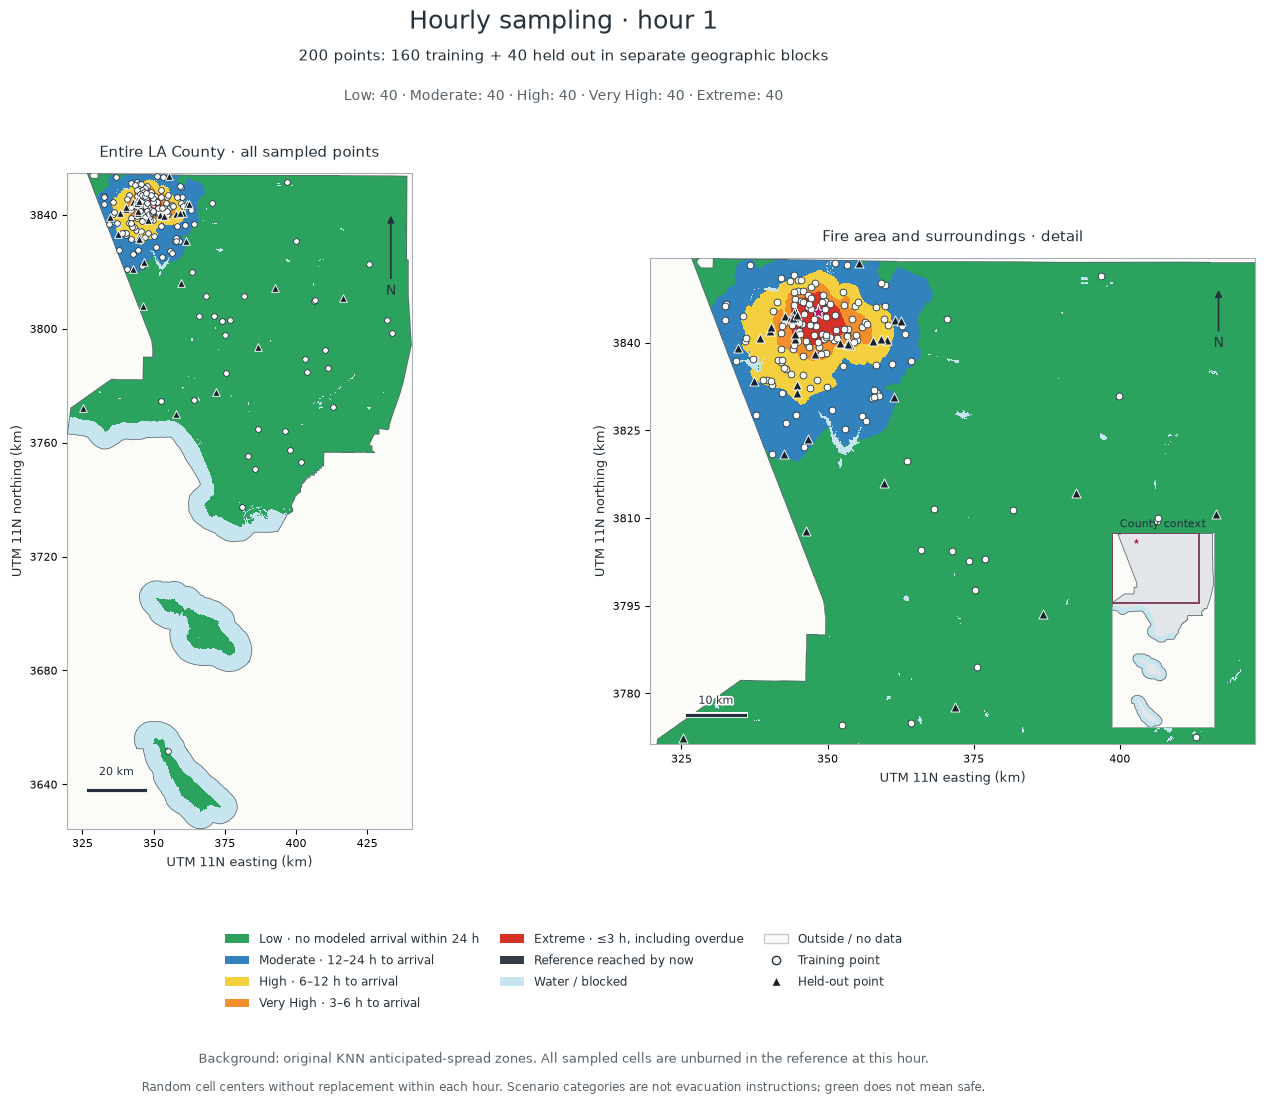

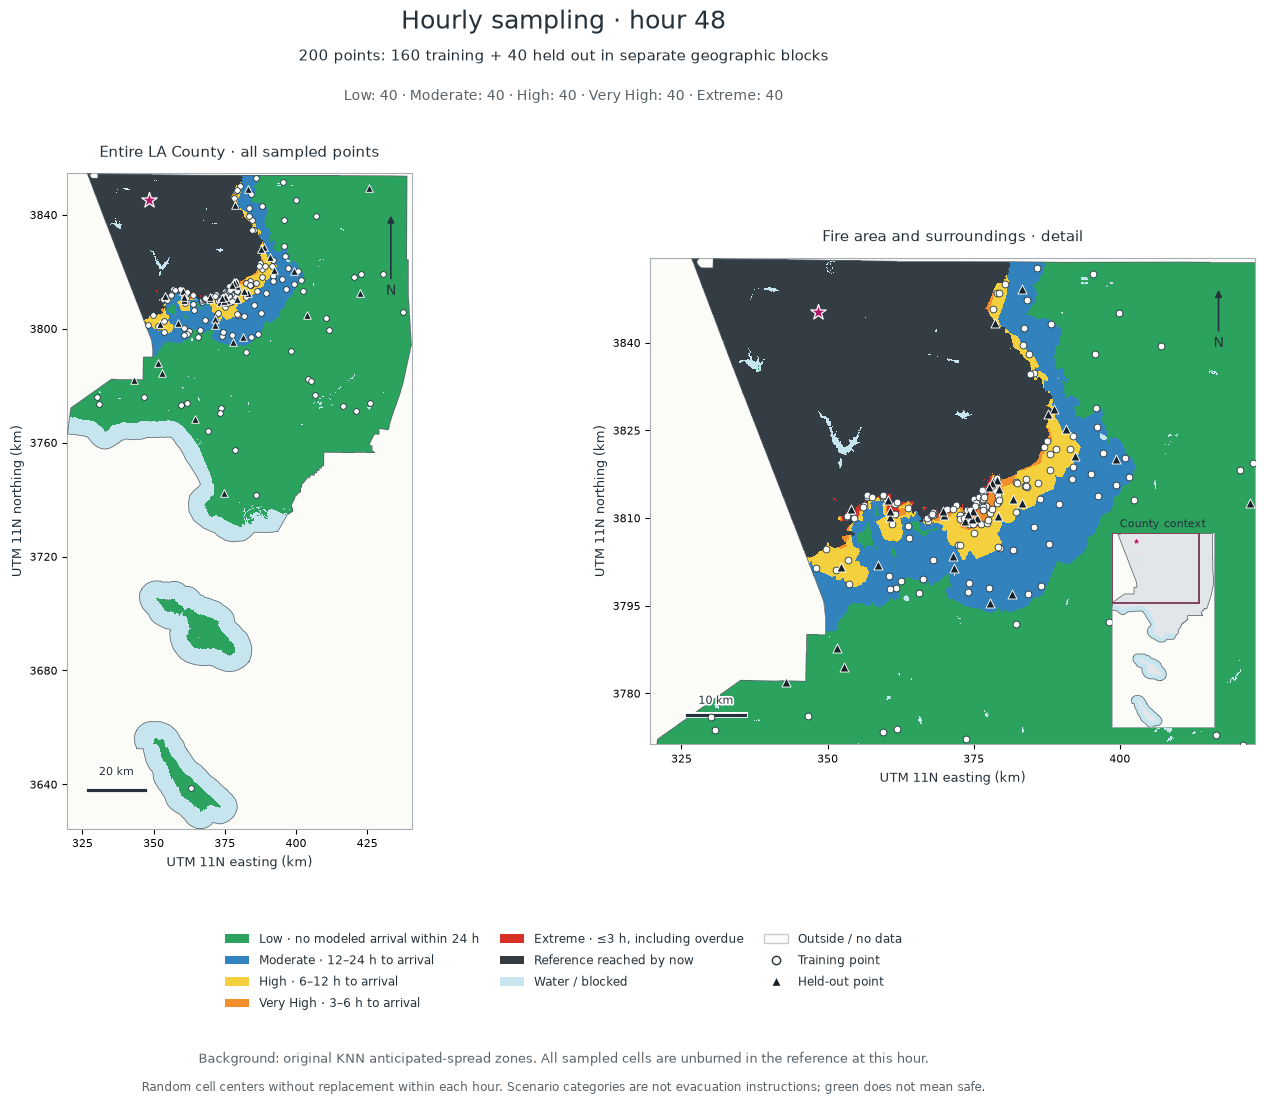

In [ ]:
sampling_checks = validate_snapshot_sampling()
quantum_checks = validate_four_qubit_feedback()
assert tuple(SNAPSHOT_FEATURE_COLUMNS) == tuple(FEEDBACK_FEATURE_NAMES)
samples, counts = sample_hourly_snapshots(
    grid, continuous_scores, baseline_scores, arrival_ref, arrival_pred,
    train_mask, test_mask, HOURS, forecast_bands=FORECAST_BANDS,
    points_per_zone=POINTS_PER_ZONE, test_points_per_zone=TEST_POINTS_PER_ZONE,
    seed=SNAPSHOT_SEED, eta_cap_hours=ETA_FEATURE_CAP_HOURS)
assert len(samples) == len(HOURS)*5*POINTS_PER_ZONE
assert samples.groupby(['hour','baseline_danger_code']).size().eq(POINTS_PER_ZONE).all()
counts.to_csv(OUTPUT/'sampling_counts.csv', index=False)
display(counts.groupby(['hour','baseline_danger_name'])['sample_count'].sum().unstack())
display(samples.head(10))
for hour in (min(HOURS), max(HOURS)):
    fig = plot_snapshot_points(grid, samples[samples.hour.eq(hour)], arrival_ref, arrival_pred,
                               ignition_flat, forecast_bands=FORECAST_BANDS)
    fig.savefig(OUTPUT/f'sampled_points_hour_{hour:02d}.png', dpi=160, bbox_inches='tight')
    display(fig); plt.close(fig)
print('Sampling checks:', sampling_checks)
print('Quantum checks:', quantum_checks)

## 3. Four-qubit feature map, kernel matrices, and KNN feedback

For each hour, a MinMaxScaler fits **only its 160 training points**. Four scaled
features enter RX(πxᵢ), RZ(πxᵢ), cyclic CZ edges (0,1),(1,2),(2,3),(3,0),
RY(πxᵢ²), then RZ(πx₀x₁) on wire 0. The output is
**Φ(x)=U(x)|0000⟩**, a unit vector with 16 complex amplitudes, ordered |0000⟩
through |1111⟩. This is an exact noiseless state-vector simulation, not quantum
hardware, and no quantum advantage is assumed.

The presentation's fidelity similarity is
**Kᵢⱼ = |⟨Φ(xᵢ)|Φ(xⱼ)⟩|²**. KNN requires **distances**, so it receives
**Dᵢⱼ = √max(0, 2−2Kᵢⱼ)**, the distance between the corresponding pure-state
projectors. The training matrix is 160×160; held-out queries use 40×160. The
full 200×200 matrix is exported with row IDs but is not fitted with test rows.

This keeps the existing KNN model family, **K=5** and inverse-distance weights,
while replacing its distance and target with the requested feedback experiment.
The output is an ordinal reference-danger estimate, rounded with floor(s+0.5)
and clipped to 0–4. It is not a probability, new physical arrival time, or a
new propagation solver. The baseline speed table and arrival fields are preserved.

Each hour has its own training-fitted scaler and KNN. Do not treat the 48
independently scaled kernels as one global 9,600×9,600 training kernel. Use the
matching hourly scaler, row IDs, states and training block for new queries.

An ordinary Euclidean KNN uses **identical inputs, scaler, labels, K, and split**
as a control, separating encoding effects from the extra reference supervision.
[scikit-learn: precomputed KNN distances](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html)
· [PennyLane: fidelity kernels](https://www.pennylane.ai/demos/tutorial_kernels_module)

,hour,held_out_n,baseline_macro_f1,euclidean_macro_f1,quantum_macro_f1,baseline_accuracy,euclidean_accuracy,quantum_accuracy
0,1,40,0.7960,0.7490,0.6812,0.800,0.750,0.675
1,2,40,0.6807,0.6468,0.6387,0.700,0.675,0.650
2,3,40,0.6869,0.8373,0.7878,0.700,0.850,0.800
3,4,40,0.6089,0.7788,0.6939,0.625,0.800,0.700
4,5,40,0.8996,0.8785,0.8463,0.900,0.875,0.850
5,6,40,0.8481,0.8473,0.8124,0.850,0.850,0.825
6,7,40,0.6876,0.7386,0.6958,0.675,0.725,0.675
7,8,40,0.7678,0.6822,0.6407,0.775,0.700,0.675
8,9,40,0.7075,0.7880,0.8120,0.700,0.775,0.800
9,10,40,0.7454,0.9481,0.8616,0.750,0.950,0.875


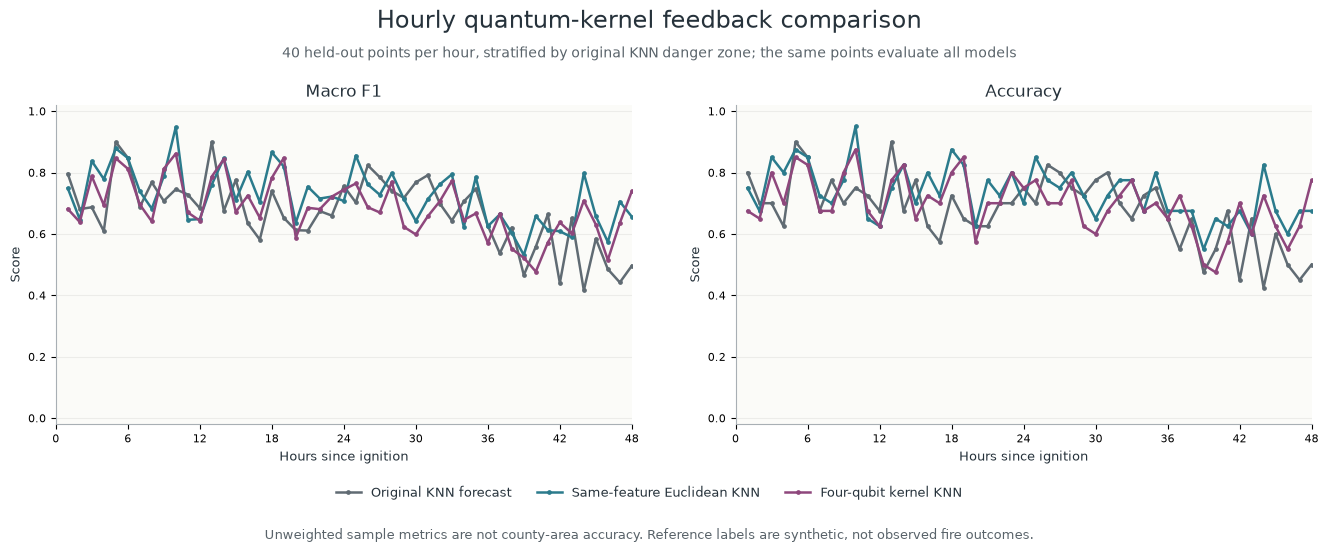

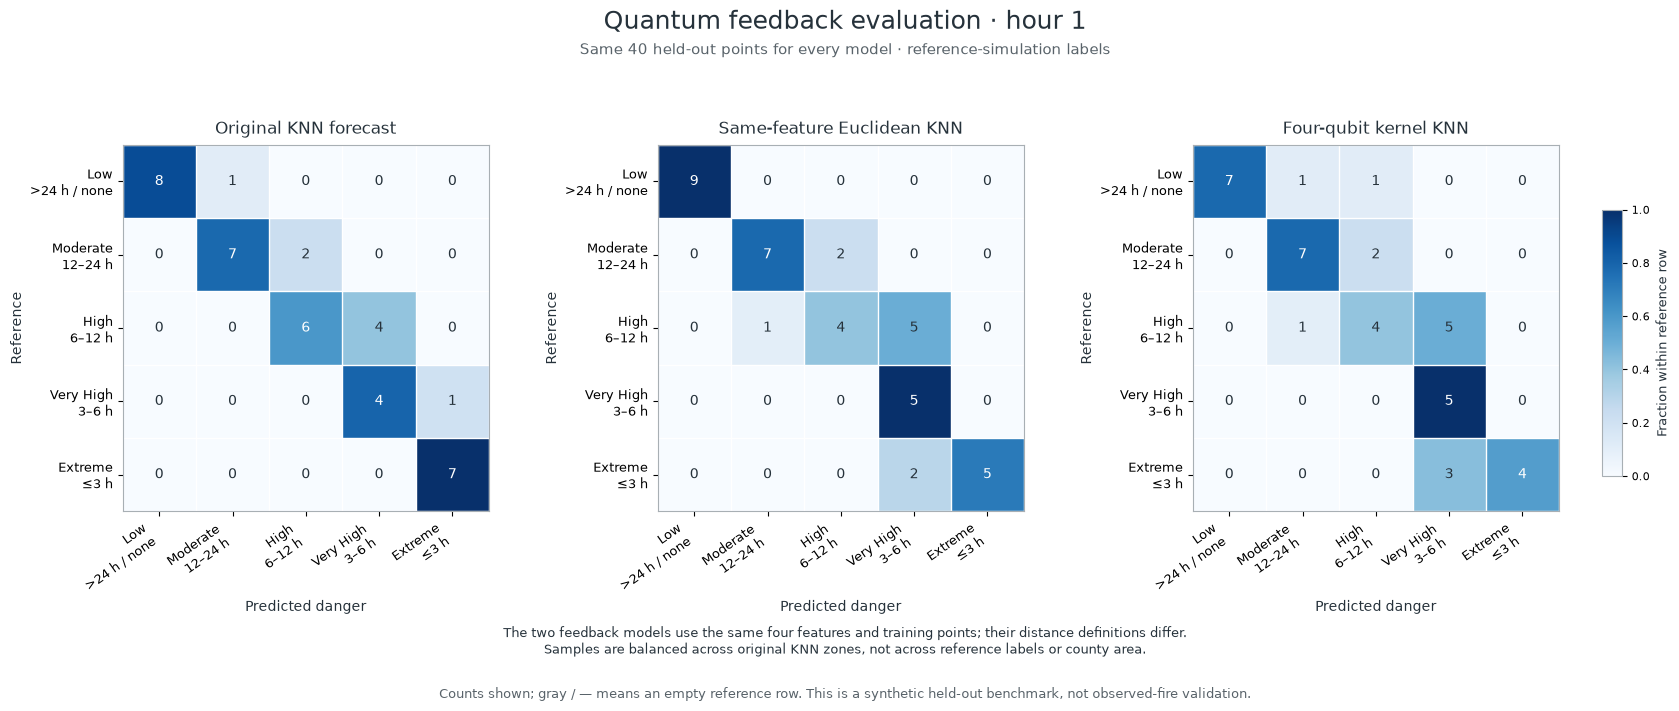

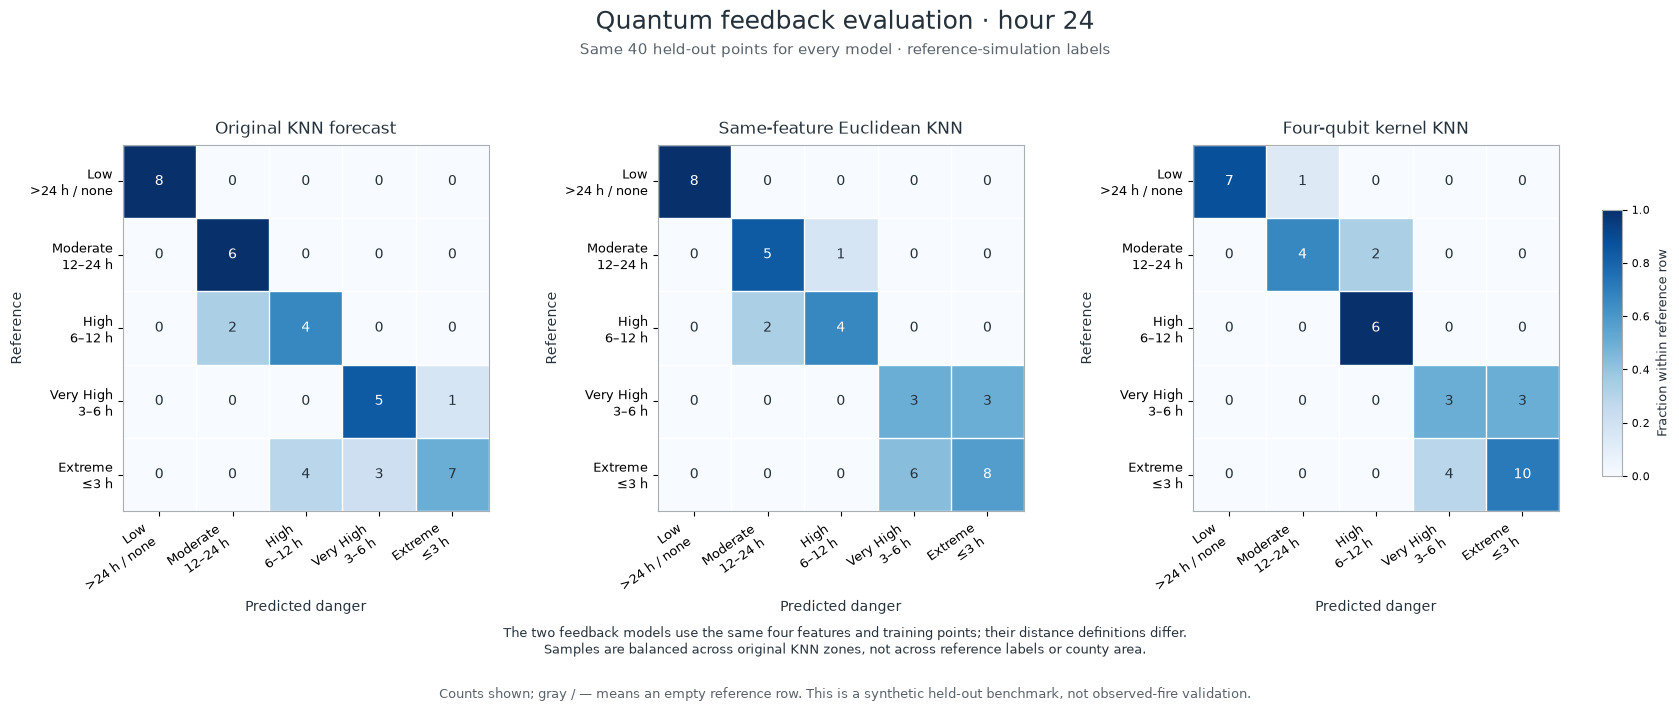

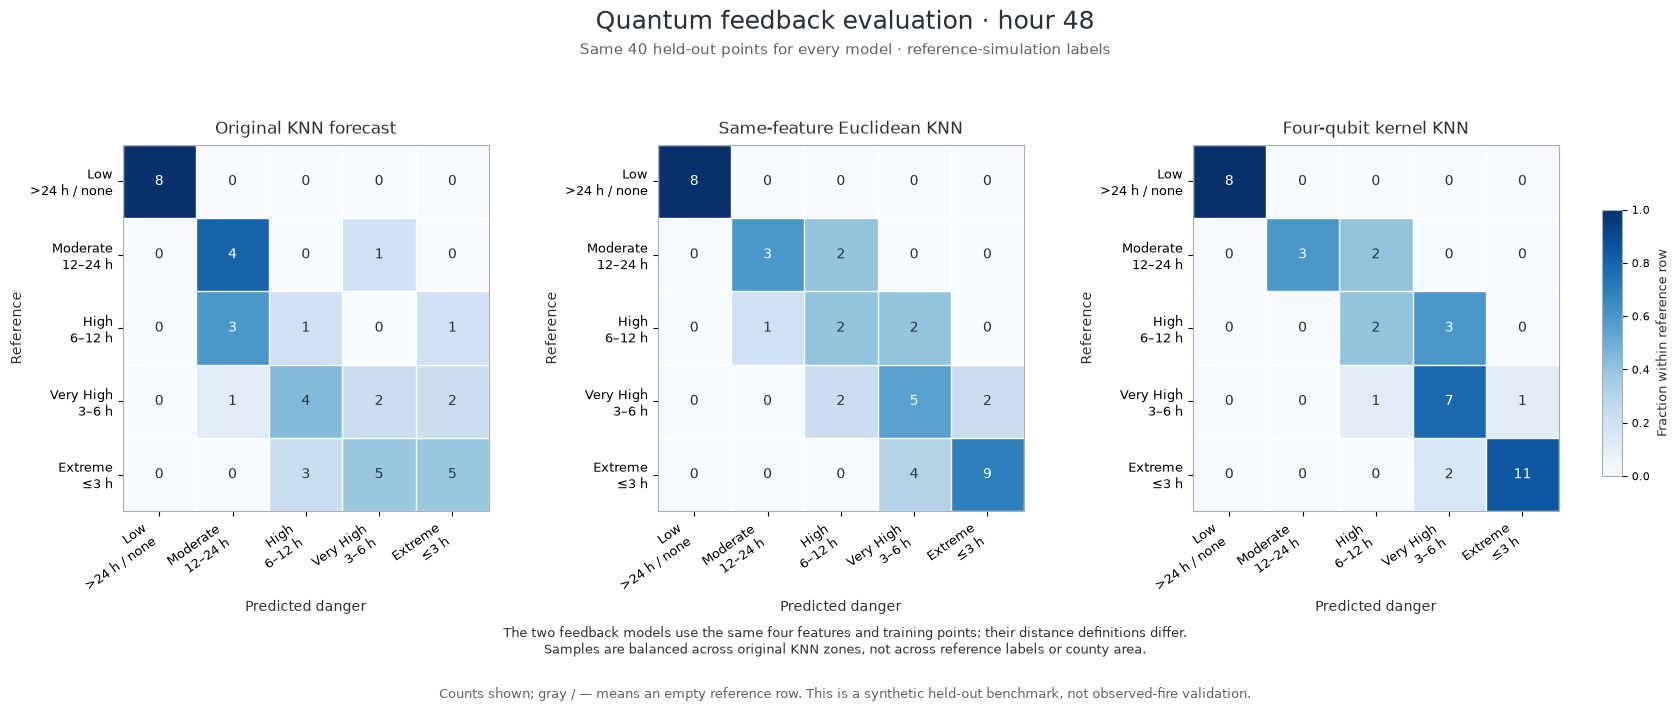

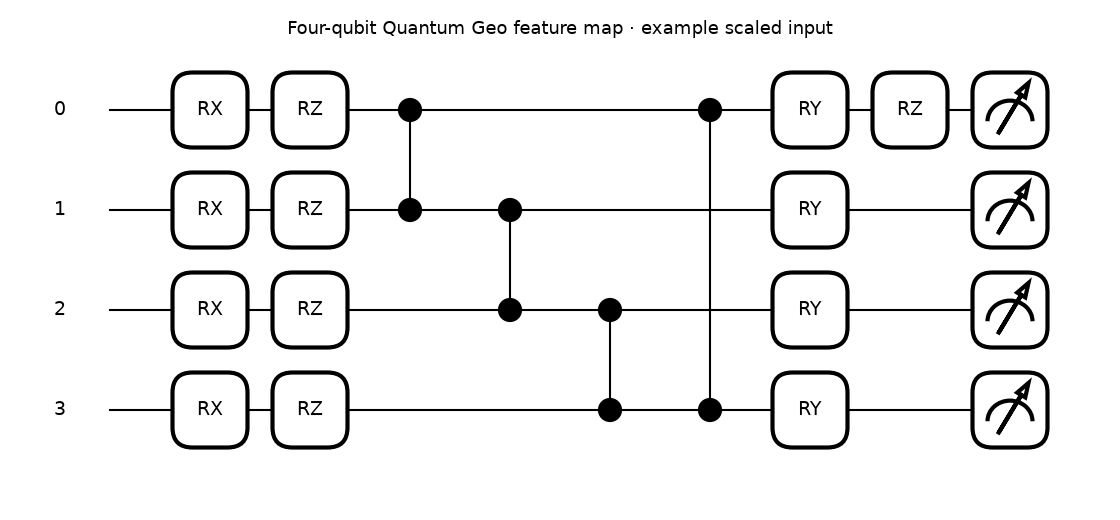

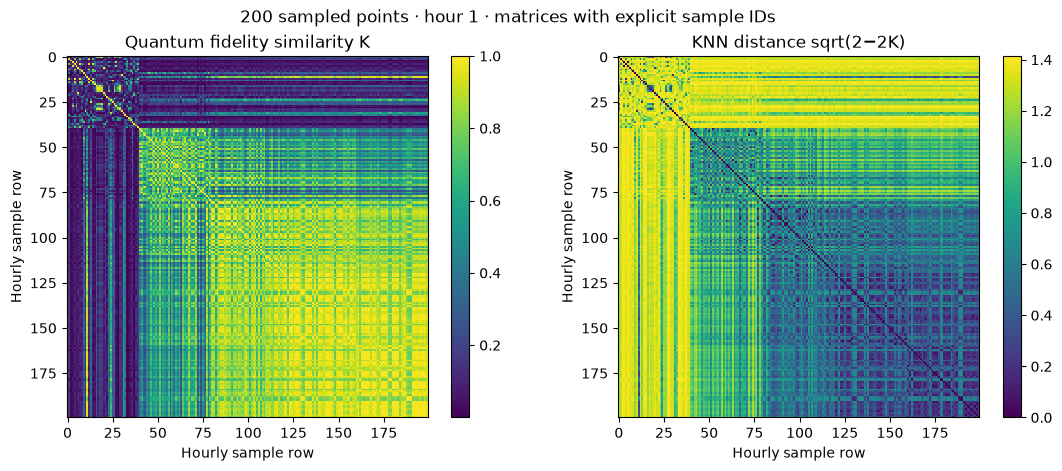

In [ ]:
with threadpool_limits(limits=NUM_THREADS):
    points, feature_table, metrics, models, matrices = fit_export_hourly_feedback(
        samples, OUTPUT, n_neighbors=KNN_K)
display(metrics[['hour','held_out_n','baseline_macro_f1','euclidean_macro_f1','quantum_macro_f1',
                 'baseline_accuracy','euclidean_accuracy','quantum_accuracy']].round(4))
fig = plot_feedback_scores(metrics)
fig.savefig(OUTPUT/'hourly_feedback_scores.png', dpi=160, bbox_inches='tight')
display(fig); plt.close(fig)
for hour in HOURS:
    cm = matrices[hour]
    fig = plot_feedback_confusions(hour, cm['baseline'], cm['euclidean'], cm['quantum'],
                                   forecast_bands=FORECAST_BANDS)
    fig.savefig(OUTPUT/f'feedback_confusion_hour_{hour:02d}.png', dpi=150, bbox_inches='tight')
    if hour in (min(HOURS), 24, max(HOURS)): display(fig)
    plt.close(fig)
fig, ax = qml.draw_mpl(four_qubit_reference_qnode)(np.array([0.2,0.4,0.6,0.8]))
fig.suptitle('Four-qubit Quantum Geo feature map · example scaled input', fontsize=13)
fig.savefig(OUTPUT/'four_qubit_feature_circuit.png', dpi=180, bbox_inches='tight')
display(fig); plt.close(fig)
bundle = np.load(OUTPUT/'kernels'/f'hour_{min(HOURS):02d}.npz', allow_pickle=False)
fig, axes = plt.subplots(1,2,figsize=(11,4.6),layout='constrained')
for ax, values, title in zip(axes,[bundle['kernel'],bundle['distances']],
                            ['Quantum fidelity similarity K','KNN distance sqrt(2−2K)']):
    im=ax.imshow(values, interpolation='nearest',cmap='viridis')
    ax.set(title=title,xlabel='Hourly sample row',ylabel='Hourly sample row')
    fig.colorbar(im,ax=ax)
fig.suptitle('200 sampled points · hour 1 · matrices with explicit sample IDs')
fig.savefig(OUTPUT/'kernel_and_distance_hour_01.png',dpi=170,bbox_inches='tight')
display(fig);plt.close(fig)

## 4. Data sheet and ready-to-use kernel blocks

The workbook contains all 9,600 rows, a separate 200-row sheet for each hour,
sampling counts, a data dictionary, and held-out scores. Training-row predictions
are explicitly marked in-sample. The 40 held-out points/hour are balanced by
**baseline** category, so these scores are not county prevalence estimates.

`quantum_feature_map.csv` contains ordered raw/scaled inputs, circuit angles,
and real/imaginary amplitudes. Its NPZ companion retains complex numbers.
Each `kernels/hour_XX.npz` carries the 200-row IDs, train/test indices, raw and
scaled features, states, kernel/distance matrices, targets, and scaler values.
The labeled CSVs make kernel axes reviewable in a spreadsheet.

In [ ]:
workbook = OUTPUT/'hourly_quantum_snapshots.xlsx'
try:
    export_snapshot_workbook(points, counts, metrics, workbook)
except PermissionError:
    # Excel locks an open workbook on Windows. Preserve it and save a new copy.
    stamp=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
    workbook=OUTPUT/f'hourly_quantum_snapshots_{stamp}.xlsx'
    export_snapshot_workbook(points, counts, metrics, workbook)
    print('Previous workbook is locked; saved a new copy:',workbook)
# A complete example feeding an exported kernel-derived distance matrix into KNN.
from sklearn.neighbors import KNeighborsRegressor
example = np.load(OUTPUT/'kernels'/'hour_48.npz', allow_pickle=False)
reloaded_knn = KNeighborsRegressor(n_neighbors=KNN_K, weights='distance', metric='precomputed')
reloaded_knn.fit(example['D_train'], example['y_train'])
reloaded_predictions = reloaded_knn.predict(example['D_test_train'])
np.testing.assert_allclose(reloaded_predictions, example['quantum_test_prediction'], atol=1e-12)
print('Exported distance matrices reproduce all 40 hour-48 held-out predictions.')
display(FileLink(workbook.relative_to(Path.cwd()).as_posix()))
display(FileLink((OUTPUT/'hourly_points_9600.csv').relative_to(Path.cwd()).as_posix()))
display(FileLink((OUTPUT/'quantum_feature_map.csv').relative_to(Path.cwd()).as_posix()))

## 5. Corrected physical quantum simulation

A danger category is not a fuel score. In particular, danger 0 means Low;
source fuel 0 means water. The correction therefore adds a **separate fuel
regression head**, rather than assigning speeds to the danger categories.

The physical head reuses the first snapshot's four-qubit feature map, fitted
scaler, kernel, 160 training locations and K=5 inverse-distance weighting.
Its targets are the supplied **fuel scores 1–4**, using training rows only.
The original future-danger target and its experiment above are retained.
The 40 held-out fuel labels evaluate this new head and do not fit it.

Features are frozen at `PHYSICAL_KERNEL_HOUR=1` for the whole run: X, Y,
baseline continuous fuel score, and baseline ETA minus 1 hour clipped to
[0,48]. The full fuel field is estimated once; it does not change between
animation frames. This is a retrospective static fuel estimate, not live
assimilation of an evolving fire. Predictions are rounded to 1–4. Known
water remains exactly 0 and unknown/outside remains −1.

The same connected-cell solver then computes arrivals from the common ignition
through hour 72. Speeds remain 0, 0.02, 0.10, 0.25, and 0.50 m/s. Water and
unknown cells have no graph nodes. Diagonals cannot cut blocked corners.
Consequently, disconnected land has infinite arrival time, however high the
quantum model estimates its fuel susceptibility. **No fuel prediction can
create a path through water.**

,head,static_kernel_hour,feature_hour,eta_feature_cap_hours,training_n,held_out_n,fuel_target_classes,training_source_fuel_counts,held_out_source_fuel_counts,feature_order,training_sample_ids,held_out_sample_ids,feature_scaler_kernel_parity,kernel_max_difference,held_out_fuel_metrics,interpretation
0,Additional reference-fuel regression; original...,1,1,48.0,160,40,"[1, 2, 3, 4]","{'1': 10, '2': 34, '3': 107, '4': 9}","{'1': 2, '2': 7, '3': 29, '4': 2}","[easting_m, northing_m, baseline_continuous_su...","[H01_P001, H01_P002, H01_P003, H01_P004, H01_P...","[H01_P033, H01_P034, H01_P035, H01_P036, H01_P...",passed against the exported hour-1 kernel bundle,1.110223e-15,"{'quantum_score_mae': 0.417990313560046, 'quan...",Retrospective static fuel estimate frozen from...


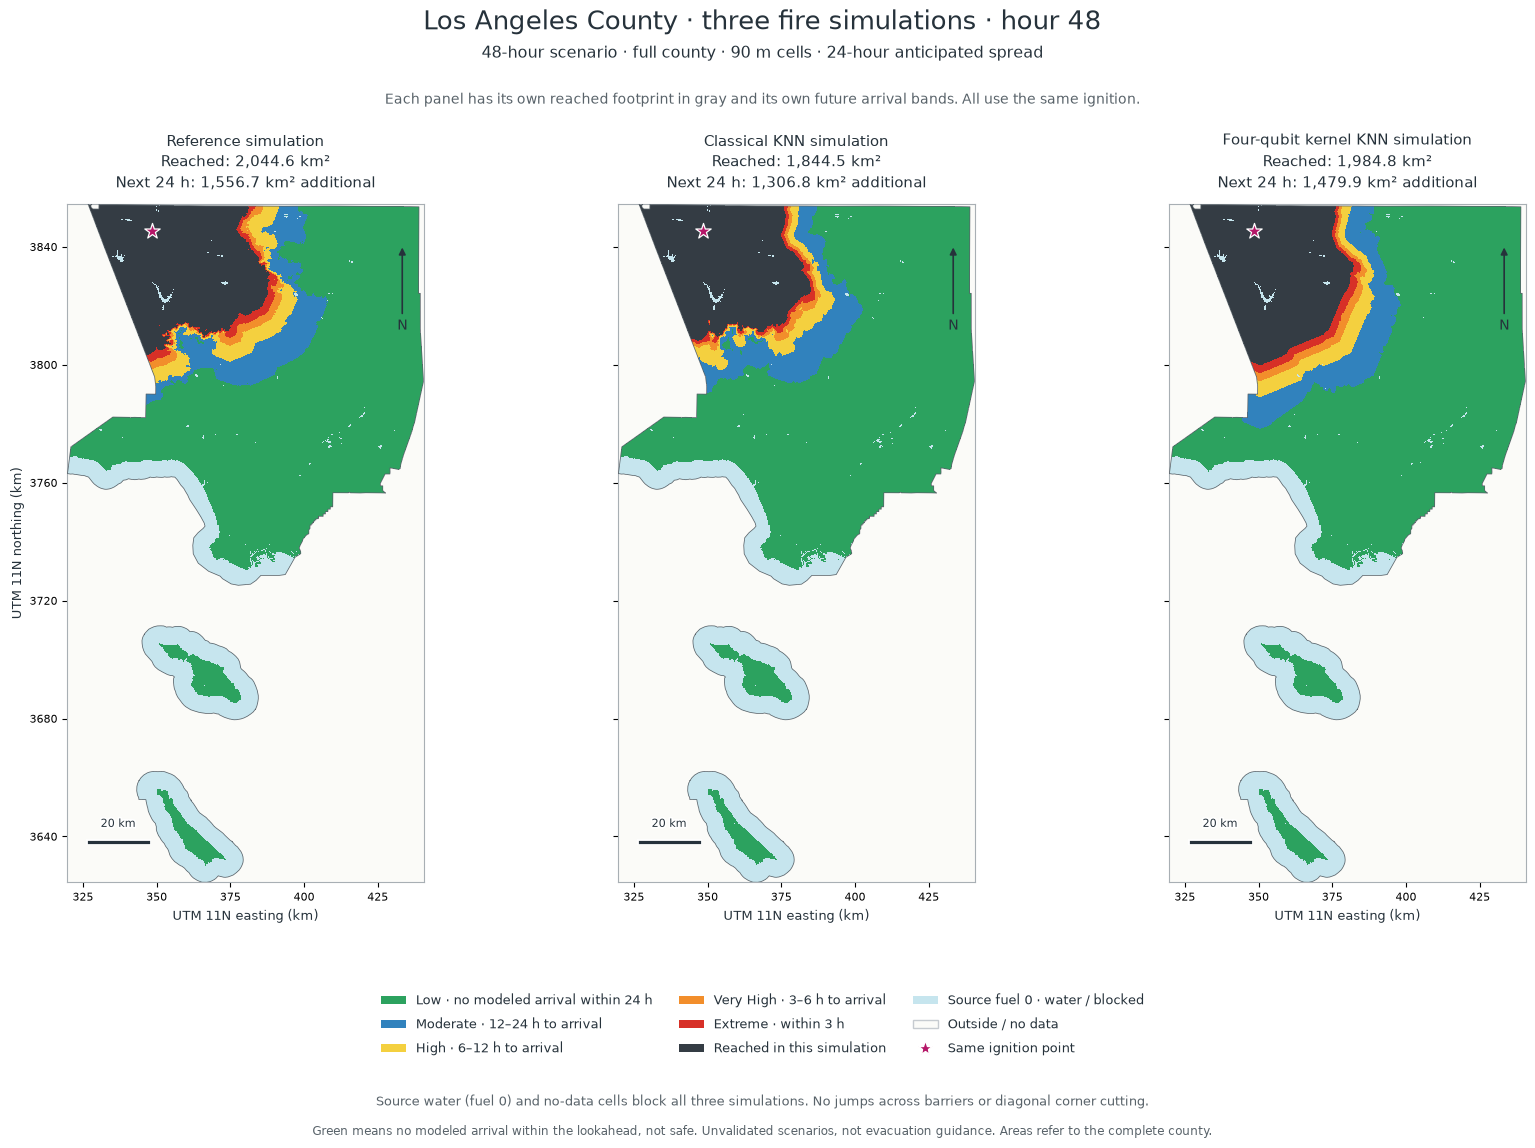

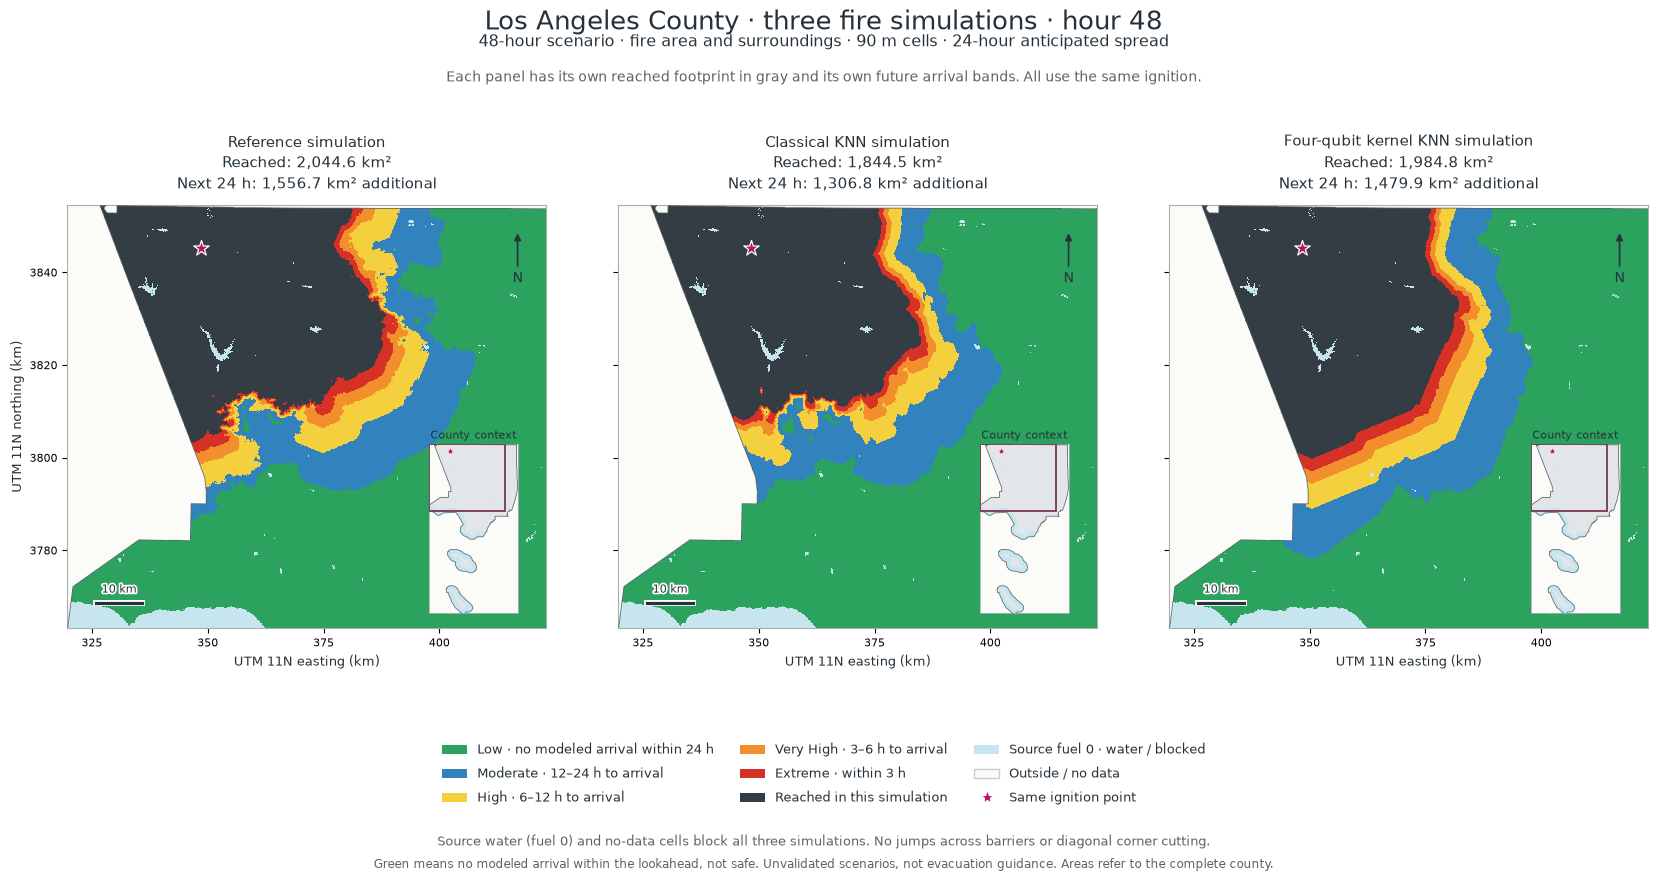

In [ ]:
physical_checks = validate_physical_feedback()
physical_bundle = np.load(OUTPUT/'kernels'/f'hour_{PHYSICAL_KERNEL_HOUR:02d}.npz',allow_pickle=False)
physical_points = points[points.hour.eq(PHYSICAL_KERNEL_HOUR)].sort_values('hour_row')
with threadpool_limits(limits=NUM_THREADS):
    physical_model, physical_info = fit_physical_quantum_head(
        grid, physical_points, physical_bundle, n_neighbors=KNN_K)
    print('Predicting one static quantum fuel field...',flush=True)
    quantum_continuous_fuel, quantum_fuel = predict_quantum_fuel_grid(
        grid,continuous_scores,arrival_pred,physical_model,
        feature_hour=PHYSICAL_KERNEL_HOUR,eta_cap_hours=ETA_FEATURE_CAP_HOURS,
        batch_size=QUERY_BATCH_SIZE)
print('Computing connected quantum fire travel times...',flush=True)
arrival_quantum = arrival_hours(quantum_fuel,grid['cell_m'],SPEED_MPS,ignition_flat,
                               CALCULATION_HOURS,connectivity=8,crop_to_horizon=False)
arrival_fields = {'reference':arrival_ref,'classical':arrival_pred,'quantum':arrival_quantum}
arrival_checks = validate_physical_arrivals(grid,arrival_fields,ignition_flat,CALCULATION_HOURS)
display(pd.DataFrame([physical_info]))
print('Physical tests:',physical_checks)
print('Arrival checks:',arrival_checks)
county_bounds = tuple(grid['bounds'])
detail_bounds = choose_view_bounds(grid,arrival_ref,np.minimum(arrival_pred,arrival_quantum),
                                   ignition_flat,padding_m=15000)
for mode,bounds in [('county',county_bounds),('detail',detail_bounds)]:
    fig=plot_three_simulations(grid,arrival_ref,arrival_pred,arrival_quantum,ignition_flat,
        DISPLAY_HOURS,forecast_bands=FORECAST_BANDS,view_bounds=bounds,map_mode=mode)
    fig.savefig(SIM_OUTPUT/f'three_simulations_hour_{DISPLAY_HOURS:02d}_{mode}.png',dpi=170,bbox_inches='tight')
    display(fig);plt.close(fig)

def save_physical_raster(path,values,nodata,dtype,tags=None):
    values=np.asarray(values)
    if np.issubdtype(values.dtype,np.floating): values=np.where(np.isfinite(values),values,nodata)
    with rasterio.open(path,'w',driver='GTiff',height=score.shape[0],width=score.shape[1],count=1,
                       dtype=dtype,crs=grid['crs'],transform=grid['transform'],nodata=nodata,
                       compress='deflate') as dst:
        dst.write(values.astype(dtype),1)
        if tags: dst.update_tags(**tags)
save_physical_raster(SIM_OUTPUT/'quantum_fuel_score_90m.tif',quantum_fuel,-1,'int16',
    {'meaning':'Fuel1..4;water0;unknown-1. Not danger categories.'})
save_physical_raster(SIM_OUTPUT/'quantum_continuous_fuel_90m.tif',quantum_continuous_fuel,-9999,'float32')
for name,arr in arrival_fields.items():
    save_physical_raster(SIM_OUTPUT/f'{name}_arrival_hours.tif',arr,-9999,'float32',
        {'calculation_hours':CALCULATION_HOURS,'blocked':'water0/unknown/disconnected; nodata also covers beyond horizon'})
np.savez_compressed(SIM_OUTPUT/'three_simulation_arrays.npz',
    reference_score=score,classical_score=baseline_scores,quantum_score=quantum_fuel,
    quantum_continuous_score=quantum_continuous_fuel,
    reference_arrival_hours=arrival_ref,classical_arrival_hours=arrival_pred,
    quantum_arrival_hours=arrival_quantum,ignition_flat=ignition_flat,
    transform=np.asarray(tuple(grid['transform'])),crs=str(grid['crs']),
    display_hours=DISPLAY_HOURS,calculation_hours=CALCULATION_HOURS,
    forecast_bands_hours=np.asarray(FORECAST_BANDS),physical_kernel_hour=PHYSICAL_KERNEL_HOUR)
np.savez_compressed(SIM_OUTPUT/'physical_fuel_training_kernel.npz',
    sample_ids=physical_bundle['sample_ids'],train_rows=physical_bundle['train_rows'],
    test_rows=physical_bundle['test_rows'],X_raw=physical_bundle['X_raw'],
    X_scaled=physical_bundle['X_scaled'],states=physical_bundle['states'],
    K_train=physical_model.train_kernel,D_train=physical_model.train_distances,
    y_train_fuel=physical_model.train_targets,
    scaler_scale=physical_model.scaler.scale_,scaler_min=physical_model.scaler.min_)

# Refresh the overview at the top of the notebook after this run's maps exist.
for _overview_mode in ('county', 'detail'):
    update_display(Image(filename=str(SIM_OUTPUT/f'three_simulations_hour_{DISPLAY_HOURS:02d}_{_overview_mode}.png')),
                   display_id=f'quantum_geo_overview_{_overview_mode}')


## 6. Hourly evaluation, interactive playback, and GIFs

All three panels now show **their own** cumulative reached area in dark gray.
Colors on their remaining land show ETA bands for the next 24 hours. No
shared reference-gray overlay is used to hide differences between the fronts.
The two learned simulations are evaluated on the same held-out, currently
reference-unreached population as before; overdue predictions remain counted.

The player runs hours 0–48. County and detail modes use fixed extents across
frames. Both standalone GIFs contain all 49 frames; the final frame retains
its full look-ahead because arrivals were computed through hour 72.

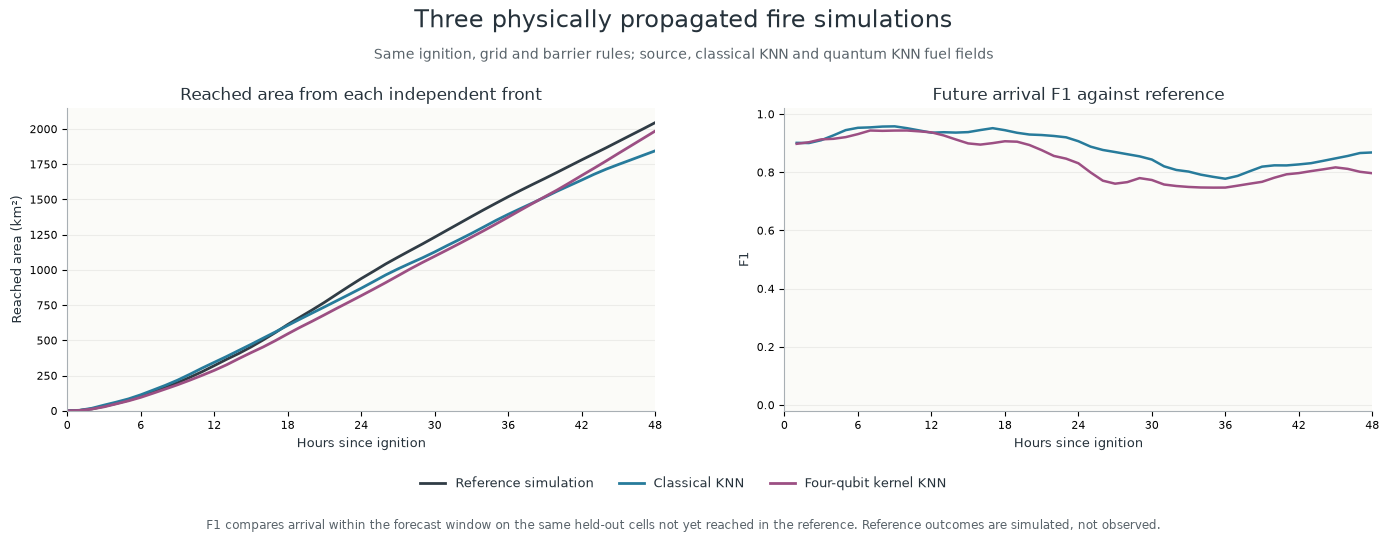

,hour,reference_area_km2,classical_area_km2,quantum_area_km2,classical_future_f1,quantum_future_f1
44,44,1866.2157,1714.4946,1772.6202,0.839294,0.810035
45,45,1910.7738,1747.6560,1826.2503,0.847672,0.816724
46,46,1955.2428,1779.7401,1878.9489,0.855991,0.811561
47,47,1999.4526,1812.2778,1931.8419,0.866094,0.801508
48,48,2044.5939,1844.5158,1984.7511,0.868022,0.796612


In [ ]:
evaluation_mask=arrays['evaluation_mask']
classical_hourly=evaluate_hourly(grid,baseline_scores,arrival_ref,arrival_pred,
    evaluation_mask,range(1,DISPLAY_HOURS+1),forecast_bands=FORECAST_BANDS)
quantum_hourly=evaluate_hourly(grid,quantum_fuel,arrival_ref,arrival_quantum,
    evaluation_mask,range(1,DISPLAY_HOURS+1),forecast_bands=FORECAST_BANDS)
export_hourly_tables(classical_hourly,SIM_OUTPUT/'evaluation_classical')
export_hourly_tables(quantum_hourly,SIM_OUTPUT/'evaluation_quantum')
area_per_cell=grid['cell_m']**2/1e6
summary_rows=[]
for hour in range(DISPLAY_HOURS+1):
    row={'hour':hour}
    for name,arr in arrival_fields.items():
        row[name+'_area_km2']=float(np.count_nonzero(arr<=hour)*area_per_cell)
    row['classical_future_f1']=classical_hourly[hour-1]['forecast_f1'] if hour else np.nan
    row['quantum_future_f1']=quantum_hourly[hour-1]['forecast_f1'] if hour else np.nan
    summary_rows.append(row)
physical_metrics=pd.DataFrame(summary_rows)
physical_metrics.to_csv(SIM_OUTPUT/'three_simulations_hourly_metrics.csv',index=False)
fig=plot_three_simulation_metrics(physical_metrics)
fig.savefig(SIM_OUTPUT/'three_simulations_metrics.png',dpi=170,bbox_inches='tight')
display(fig);plt.close(fig)
for record in quantum_hourly:
    hour=record['hour']
    fig=plot_confusion_pair(record)
    fig.suptitle(f'Physical quantum KNN vs reference · hour {hour:02d}',fontsize=17,y=0.965)
    fig.savefig(SIM_OUTPUT/f'quantum_confusion_hour_{hour:02d}.png',dpi=140,bbox_inches='tight')
    plt.close(fig)
    danger=forecast_danger(arrival_quantum,hour,FORECAST_BANDS)
    danger[score<0]=-1;danger[score==0]=-3
    danger[(score>0)&(arrival_quantum<=hour)]=-2
    save_physical_raster(SIM_OUTPUT/f'quantum_physical_danger_hour_{hour:02d}.tif',danger,-1,'int16',
        {'issue_hour':hour,'meaning':'Own quantum current footprint -2;water -3;unknown -1;danger0..4'})
display(physical_metrics.tail())
play=widgets.Play(value=0,min=0,max=DISPLAY_HOURS,step=1,interval=600,description='Play')
slider=widgets.IntSlider(value=0,min=0,max=DISPLAY_HOURS,step=1,description='Hour',continuous_update=False)
play_link=widgets.jslink((play,'value'),(slider,'value'))
map_view=widgets.ToggleButtons(options=[('Entire LA County','county'),('Expanded fire area','detail')],value='county')
def show_physical_hour(hour,mode):
    bounds=county_bounds if mode=='county' else detail_bounds
    fig=plot_three_simulations(grid,arrival_ref,arrival_pred,arrival_quantum,ignition_flat,hour,
        forecast_bands=FORECAST_BANDS,view_bounds=bounds,map_mode=mode)
    display(fig);plt.close(fig)
player_output=widgets.interactive_output(show_physical_hour,{'hour':slider,'mode':map_view})
display(widgets.VBox([widgets.HBox([play,slider]),map_view,player_output]))

Saved county animation preview: all 49 hourly frames. Run All for full resolution.
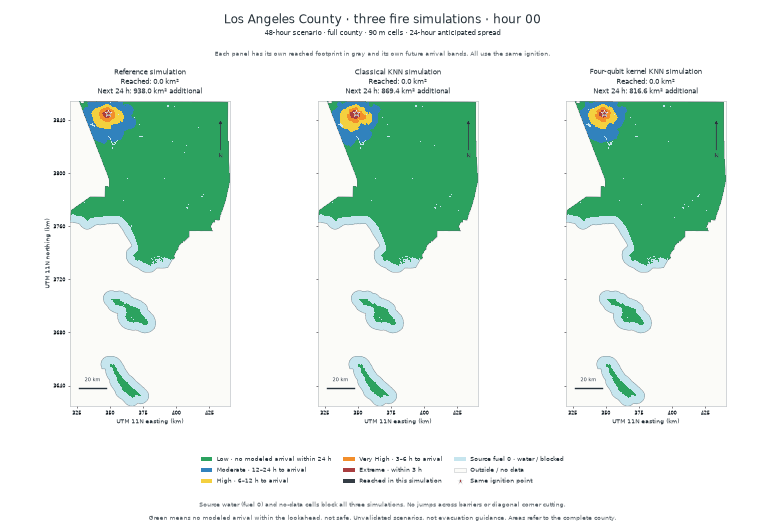

Saved detail animation preview: all 49 hourly frames. Run All for full resolution.
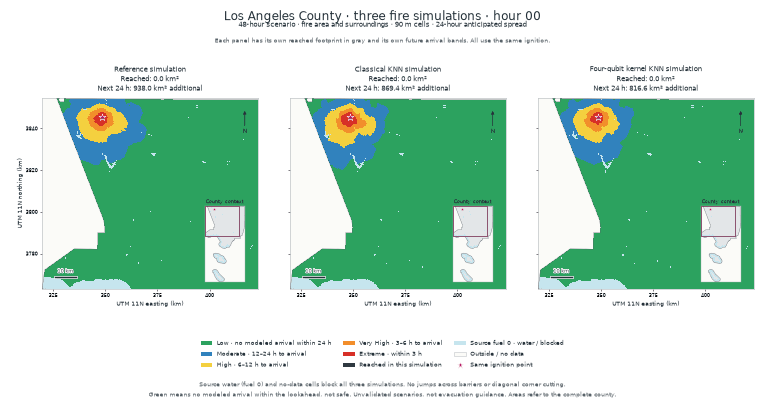

In [ ]:
gif_paths={}
for mode,bounds in [('county',county_bounds),('detail',detail_bounds)]:
    frames=[]
    for hour in range(DISPLAY_HOURS+1):
        fig=plot_three_simulations(grid,arrival_ref,arrival_pred,arrival_quantum,ignition_flat,hour,
            forecast_bands=FORECAST_BANDS,view_bounds=bounds,map_mode=mode)
        buffer=io.BytesIO()
        fig.savefig(buffer,format='png',dpi=GIF_DPI)  # Fixed canvas size in every frame.
        plt.close(fig);buffer.seek(0)
        with PILImage.open(buffer) as frame: frames.append(frame.convert('RGB').copy())
        if hour%8==0: print(f'{mode} GIF frame {hour}/{DISPLAY_HOURS}',flush=True)
    assert len({frame.size for frame in frames})==1
    path=SIM_OUTPUT/f'three_simulations_{DISPLAY_HOURS:02d}h_{mode}.gif'
    frames[0].save(path,save_all=True,append_images=frames[1:],duration=GIF_FRAME_MS,
                   loop=0,optimize=False,disposal=2)
    with PILImage.open(path) as saved: assert saved.n_frames==DISPLAY_HOURS+1
    gif_paths[mode]=path
    del frames
    display(HTML('<img alt="Three fire simulations over 48 hours" src="data:image/gif;base64,'
                         + base64.b64encode(path.read_bytes()).decode('ascii') + '" />'))
    display(FileLink(path.relative_to(Path.cwd()).as_posix()))

## 7. Provenance and completion

In [ ]:
feature_definition = {
 'features_in_order':list(FEEDBACK_FEATURE_NAMES), 'qubits':4, 'amplitudes':16,
 'basis_order':[f'{i:04b}' for i in range(16)], 'wire0_is_most_significant':True,
 'scaling':'Independent MinMaxScaler per hour, fitted only on 160 training rows; queries are not clipped.',
 'eta_cap_hours':ETA_FEATURE_CAP_HOURS,
 'eta_cap_meaning':'Feature cap/sentinel only; infinity does not imply arrival at the cap.',
 'gates':['RX(pi*x_i) then RZ(pi*x_i), wires0..3','CZ ring0-1-2-3-0',
          'RY(pi*x_i**2), wires0..3','RZ(pi*x0*x1), wire0'],
 'kernel':'abs(states_i @ states_j.conj())**2',
 'distance':'sqrt(max(0,2-2*kernel)); squared distances<=1e-12 treated as zero',
 'target':'Reference simulation future-danger code0..4',
 'no_reference_future_input':True, 'cross_hour_kernels':'Separate hourly scalers/models; do not concatenate as one global kernel.',
}
(OUTPUT/'quantum_feature_map_definition.json').write_text(json.dumps(feature_definition,indent=2),encoding='utf-8')
manifest = {
 'created_utc':datetime.now(timezone.utc).isoformat(),
 'notebook':'LA_County_Quantum_Geo.ipynb',
 'snapshot_hours':list(HOURS),'samples':len(points),'points_per_zone':POINTS_PER_ZONE,
 'training_rows':int(points.split.eq('train').sum()),'held_out_rows':int(points.split.eq('test').sum()),
 'seed':SNAPSHOT_SEED,'knn_k':KNN_K,
 'cell_m':grid['cell_m'],'feature_map':feature_definition,
 'baseline_hashes':baseline_hashes,
 'embedded_source_kml_sha256':SOURCE_KML_SHA256,
 'source_mode':'Embedded KML; baseline rebuilt from scratch in this execution.',
 'baseline_checks':baseline_checks,
 'runtime':{'python':sys.version,'platform':platform.platform()},
 'presentation_sha256':PRESENTATION_SHA256,
 'presentation_reference':'Pages2-5 circuit/fidelity kernel; adapted3->4qubits andSVM->KNN; originalsyntheticclasslabelsnotused.',
 'sampling_checks':sampling_checks,'quantum_checks':quantum_checks,
 'evaluation':'Danger experiment:40 heldout points/hour. Physical simulation:hourly reference-unreached spatial holdout, using original fixed evaluation mask.',
 'physical_correction':{
     'fuel_target':'Additional head learns reference fuel1..4; original danger target retained separately.',
     'physical_kernel_hour':PHYSICAL_KERNEL_HOUR,'display_hours':DISPLAY_HOURS,
     'calculation_hours':CALCULATION_HOURS,'speed_m_s':SPEED_MPS.tolist(),
     'method':'Static quantum fuel estimate -> original connected-cell travel-time solver; blocked water/unknown; no diagonal corner cutting.',
     'display_masks':'Each simulation has its own reached footprint and future ETA bands.',
     'fit_and_held_out_fuel_metrics':physical_info,'synthetic_tests':physical_checks,
     'arrival_validation':arrival_checks,'output_folder':str(SIM_OUTPUT),
     'gifs':{mode:path.name for mode,path in gif_paths.items()},
 },
 'limits':'Noiseless classical state-vector simulation. Reference future labels are synthetic hindsight supervision. No observed-fire or operational evacuation validation.',
 'package_versions':{p:version(p) for p in ['numpy','pandas','scikit-learn','pennylane','rasterio','openpyxl']},
}
for name,digest in baseline_hashes.items():
    assert hashlib.sha256((BASELINE_DIR/name).read_bytes()).hexdigest()==digest
(OUTPUT/'run_manifest.json').write_text(json.dumps(manifest,indent=2,default=str),encoding='utf-8')
(SIM_OUTPUT/'run_manifest.json').write_text(json.dumps(manifest,indent=2,default=str),encoding='utf-8')
display(Markdown(f'**Completed {len(HOURS)} hourly snapshots: {len(points):,} points and {len(HOURS)} four-qubit kernels.** '
    f'New KNN predictions include {int(points.split.eq("test").sum()):,} spatially held-out records. '
    'The corrected physical model adds a separate fuel head and three connected spread simulations. '
    'Both GIFs contain all49 frames, hours0–48; water and disconnected land remain unreachable.'))
display(metrics[['baseline_macro_f1','euclidean_macro_f1','quantum_macro_f1']].mean().rename('Mean hourly held-out macro F1').to_frame())
display(FileLink(workbook.relative_to(Path.cwd()).as_posix()))
display(FileLink((OUTPUT/'quantum_feature_map.npz').relative_to(Path.cwd()).as_posix()))
display(FileLink((OUTPUT/'run_manifest.json').relative_to(Path.cwd()).as_posix()))
display(FileLink(gif_paths['county'].relative_to(Path.cwd()).as_posix()))
display(FileLink(gif_paths['detail'].relative_to(Path.cwd()).as_posix()))
print('Saved results:',OUTPUT)

,Mean hourly held-out macro F1
baseline_macro_f1,0.671276
euclidean_macro_f1,0.722637
quantum_macro_f1,0.685396


## 8. Download the complete results

The archive includes the three simulations, both GIFs, the workbook,
hourly tables, all quantum kernels and features, rasters, and manifests.
It does not include any environment files or unrelated local data.
In Colab, select a download below or use the Files panel.

In [ ]:
import zipfile
archive_path = PROJECT_DIR / 'quantum_geo_results.zip'
with zipfile.ZipFile(archive_path, 'w', compression=zipfile.ZIP_DEFLATED,
                     compresslevel=4) as archive:
    for folder in (BASELINE_DIR, SIM_OUTPUT):
        for path in sorted(folder.rglob('*')):
            if path.is_file():
                archive.write(path, path.relative_to(PROJECT_DIR).as_posix())
print(f'Complete results ZIP: {archive_path} ({archive_path.stat().st_size / 2**20:.1f} MiB)')
display(FileLink(archive_path.relative_to(Path.cwd()).as_posix()))
if IN_COLAB:
    from google.colab import files as colab_files
    download_paths = {'All results (ZIP)': archive_path,
                      'County animation (GIF)': gif_paths['county'],
                      'Fire-area animation (GIF)': gif_paths['detail'],
                      'Hourly data (Excel)': workbook}
    download_choice = widgets.Dropdown(options=list(download_paths), description='File:')
    download_button = widgets.Button(description='Download', icon='download')
    def download_selected(_):
        colab_files.download(str(download_paths[download_choice.value]))
    download_button.on_click(download_selected)
    display(widgets.HBox([download_choice, download_button]))
display(Markdown('**Completed.** Both 49-frame GIFs and all hourly results are ready.'))